In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Loading data set

In [3]:
df = pd.read_csv(
    r"C:\Users\rajab\Desktop\ML-Health-Insurance\Data\final_renewal_dataset.csv"
)

### Inspect the dataset structure, feature data types, and non-null counts to obtain an initial understanding of data completeness

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123298 entries, 0 to 123297
Data columns (total 44 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    123298 non-null  str    
 1   ID_policy             123298 non-null  int64  
 2   ID_insured            123298 non-null  int64  
 3   period                123298 non-null  int64  
 4   date_effect_insured   123298 non-null  str    
 5   date_lapse_insured    20071 non-null   str    
 6   date_effect_policy    123298 non-null  str    
 7   date_lapse_policy     17294 non-null   str    
 8   year_effect_insured   123298 non-null  int64  
 9   year_lapse_insured    20071 non-null   float64
 10  year_effect_policy    123298 non-null  int64  
 11  year_lapse_policy     17294 non-null   float64
 12  exposure_time         123298 non-null  float64
 13  lapse                 123298 non-null  int64  
 14  seniority_insured     123298 non-null  int64  
 15  seniority_p

### Examining the dataset dimensions to identify the total number of observations and features

In [5]:
df.shape

(123298, 44)

### Display the first five observations to understand the dataset structure and sample values

In [6]:
df.head()

,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C,target_premium,age_difference
0,10000_1,10000,1,2017,2004-07-01,NaN,2004-07-01,NaN,2004,NaN,...,18.0,67.0,91.0,17.0,23.0,72.0,70.0,C3,630.3600,1
1,10000_1,10000,1,2018,2004-07-01,NaN,2004-07-01,NaN,2004,NaN,...,13.0,66.0,90.0,18.0,23.0,72.0,70.0,C3,652.5858,1
2,10001_1,10001,1,2017,2004-07-09,NaN,2004-07-09,NaN,2004,NaN,...,98.0,7.0,4.0,97.0,1.0,1.0,100.0,C1,2882.5400,1
3,10001_1,10001,1,2018,2004-07-09,NaN,2004-07-09,NaN,2004,NaN,...,98.0,7.0,4.0,97.0,1.0,1.0,100.0,C1,3038.3931,1
4,10002_1,10002,1,2017,2004-08-01,NaN,2004-08-01,NaN,2004,NaN,...,90.0,24.0,20.0,80.0,6.0,2.0,99.0,C1,2010.9100,1


### Identify the data type of each feature to distinguish numerical, categorical, and temporal variables.

In [7]:
df.dtypes

ID                          str
ID_policy                 int64
ID_insured                int64
period                    int64
date_effect_insured         str
date_lapse_insured          str
date_effect_policy          str
date_lapse_policy           str
year_effect_insured       int64
year_lapse_insured      float64
year_effect_policy        int64
year_lapse_policy       float64
exposure_time           float64
lapse                     int64
seniority_insured         int64
seniority_policy          int64
type_policy                 str
type_policy_dg              str
type_product                str
reimbursement               str
new_business                str
distribution_channel        str
gender                      str
age                       int64
previous_premium        float64
cost_claims_year        float64
n_medical_services        int64
n_insured_pc              int64
n_insured_mun             int64
n_insured_prov            int64
IICIMUN                 float64
IICIPROV

### Examine descriptive statistics to understand the central tendency, variability, and range of numerical features.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID_policy,123298.0,18666.367216,11065.288503,1.0000,8979.000000,18260.00,28973.00,38910.0000
ID_insured,123298.0,9.955587,71.451569,1.0000,1.000000,2.00,3.00,1228.0000
period,123298.0,2017.485255,0.499785,2017.0000,2017.000000,2017.00,2018.00,2018.0000
year_effect_insured,123298.0,2003.334320,13.149195,1933.0000,1995.000000,2006.00,2015.00,2018.0000
year_lapse_insured,20071.0,2018.609885,0.487788,2018.0000,2018.000000,2019.00,2019.00,2019.0000
year_effect_policy,123298.0,2002.331352,14.120342,1932.0000,1994.000000,2005.00,2014.00,2018.0000
year_lapse_policy,17294.0,2018.600266,0.489858,2018.0000,2018.000000,2019.00,2019.00,2019.0000
exposure_time,123298.0,0.985661,0.118885,0.0000,1.000000,1.00,1.00,1.0000
lapse,123298.0,2.000000,0.000000,2.0000,2.000000,2.00,2.00,2.0000
seniority_insured,123298.0,14.150935,13.148043,0.0000,3.000000,12.00,23.00,85.0000


### Examine the number of unique values in each feature to identify categorical variables, identifiers, and potential high-cardinality features.

In [9]:
df.nunique()

ID                      69738
ID_policy               32543
ID_insured               1205
period                      2
date_effect_insured      4822
date_lapse_insured        437
date_effect_policy       3034
date_lapse_policy         257
year_effect_insured        86
year_lapse_insured          2
year_effect_policy         87
year_lapse_policy           2
exposure_time               2
lapse                       1
seniority_insured          86
seniority_policy           87
type_policy                 2
type_policy_dg              6
type_product                4
reimbursement               2
new_business                2
distribution_channel        3
gender                      2
age                       100
previous_premium         5835
cost_claims_year         9273
n_medical_services        312
n_insured_pc              285
n_insured_mun             228
n_insured_prov             99
IICIMUN                   875
IICIPROV                   72
C_H                         6
C_GI      

### Examine the distribution of records across observation periods to understand the dataset's temporal coverage

In [10]:
df["period"].value_counts().sort_index()

period
2017    63467
2018    59831
Name: count, dtype: int64

#### The renewal dataset contains 123,298 observations and 44 columns, covering 2017 and 2018. It includes 69,738 unique `ID` values, 32,543 unique `ID_policy` values, and 1,205 unique `ID_insured` values. Repeated identifiers and missing values require further investigation before preprocessing and modeling.

## 2. Feature Classification

### Classify dataset attributes according to their statistical meaning to identify suitable methods for exploratory analysis and subsequent preprocessing.

### 2.1 Identifier Features

#### Identify columns representing insured individuals, policies, and insured-policy records, which should be treated as identifiers rather than numerical measurements.

In [11]:

id_cols = [
    "ID",
    "ID_policy",
    "ID_insured"
]

print("Identifier features:", id_cols)


Identifier features: ['ID', 'ID_policy', 'ID_insured']


### 2.2 Temporal Features

#### Identify date and year-related attributes to distinguish temporal information from ordinary numerical features.

In [12]:

date_cols = [
    "date_effect_insured",
    "date_lapse_insured",
    "date_effect_policy",
    "date_lapse_policy"
]

year_cols = [
    "period",
    "year_effect_insured",
    "year_lapse_insured",
    "year_effect_policy",
    "year_lapse_policy"
]

print("Date features:", date_cols)
print("Year features:", year_cols)


Date features: ['date_effect_insured', 'date_lapse_insured', 'date_effect_policy', 'date_lapse_policy']
Year features: ['period', 'year_effect_insured', 'year_lapse_insured', 'year_effect_policy', 'year_lapse_policy']


### 2.3 Categorical Features

#### Identify features representing discrete categories, including policy characteristics, demographic attributes, and geographical classifications.

In [13]:

cat_cols = [
    "lapse",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "new_business",
    "distribution_channel",
    "gender",
    "C_H",
    "C_C"
]

print("Categorical features:", cat_cols)


Categorical features: ['lapse', 'type_policy', 'type_policy_dg', 'type_product', 'reimbursement', 'new_business', 'distribution_channel', 'gender', 'C_H', 'C_C']


### 2.4 Numerical Features

#### Identify quantitative variables representing demographic, financial, insurance-related, and geographical characteristics for numerical statistical analysis.

In [14]:

num_cols = [
    "exposure_time",
    "seniority_insured",
    "seniority_policy",
    "age",
    "previous_premium",
    "cost_claims_year",
    "n_medical_services",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "IICIMUN",
    "IICIPROV",
    "C_GI",
    "C_II",
    "C_IE_P",
    "C_IE_S",
    "C_IE_T",
    "C_GE_P",
    "C_GE_S",
    "C_GE_T",
    "age_difference"
]

print("Numerical features:", num_cols)


Numerical features: ['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'previous_premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'age_difference']


### 2.5 Target Variable

#### Identify the response variable representing the premium amount to be predicted during the renewal period.

In [15]:

target_col = "target_premium"

print("Target variable:", target_col)
print("Target data type:", df[target_col].dtype)


Target variable: target_premium
Target data type: float64


### 2.6 Feature Classification Summary

#### Summarize the number of features in each statistical category and verify that every dataset column has been classified exactly once.

In [16]:

feature_groups = {
    "Identifiers": id_cols,
    "Dates": date_cols,
    "Years": year_cols,
    "Categorical": cat_cols,
    "Numerical": num_cols,
    "Target": [target_col]
}

classification_summary = pd.DataFrame({
    "Feature Group": list(feature_groups.keys()),
    "Count": [
        len(cols) for cols in feature_groups.values()
    ]
})

display(classification_summary)


,Feature Group,Count
0,Identifiers,3
1,Dates,4
2,Years,5
3,Categorical,10
4,Numerical,21
5,Target,1


### 2.7 Feature Classification Validation

#### Verify that all dataset attributes have been included in the classification and that no feature has been assigned to multiple groups.

In [17]:

all_classified = [
    col
    for cols in feature_groups.values()
    for col in cols
]

missing_features = set(df.columns) - set(all_classified)
extra_features = set(all_classified) - set(df.columns)

duplicate_features = pd.Series(
    all_classified
).value_counts()

duplicate_features = duplicate_features[
    duplicate_features > 1
]

print("Total dataset columns:", len(df.columns))
print("Total classified features:", len(all_classified))
print("Unclassified features:", missing_features)
print("Nonexistent features:", extra_features)
print("Duplicate assignments:", duplicate_features.to_dict())

print(
    "Classification valid:",
    not missing_features
    and not extra_features
    and duplicate_features.empty
)


Total dataset columns: 44
Total classified features: 44
Unclassified features: set()
Nonexistent features: set()
Duplicate assignments: {}
Classification valid: True


### 3.1 Exact Duplicate Records

#### Identify completely duplicated observations to assess potential data redundancy and recording errors.

In [18]:

exact_duplicates = df.duplicated().sum()

print("Total observations:", len(df))
print("Exact duplicate records:", exact_duplicates)
print("Duplicate percentage:",
      round(exact_duplicates / len(df) * 100, 2))



Total observations: 123298
Exact duplicate records: 0
Duplicate percentage: 0.0


### 3.2 Identifier Uniqueness

#### Examine the uniqueness and repetition of insured-policy identifiers to understand the dataset's observational structure.

In [19]:

id_summary = pd.DataFrame({
    "Identifier": id_cols,
    "Unique Values": [
        df[col].nunique() for col in id_cols
    ],
    "Repeated Rows": [
        df[col].duplicated().sum() for col in id_cols
    ],
    "Missing Values": [
        df[col].isna().sum() for col in id_cols
    ]
})

display(id_summary)


,Identifier,Unique Values,Repeated Rows,Missing Values
0,ID,69738,53560,0
1,ID_policy,32543,90755,0
2,ID_insured,1205,122093,0


### 3.3 Identifier–Period Consistency

#### Check whether the same insured-policy identifier appears multiple times within an observation period and investigate potentially duplicated annual records.

In [20]:

id_period_duplicates = df.duplicated(
    subset=["ID", "period"],
    keep=False
)

print("Rows with repeated ID-period combinations:",
      id_period_duplicates.sum())

display(
    df.loc[id_period_duplicates]
      .sort_values(["ID", "period"])
      .head(20)
)


Rows with repeated ID-period combinations: 0


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C,target_premium,age_difference


# 3.4 Identifier Relationship Consistency

#### Investigate whether insured-policy identifiers maintain consistent relationships with their associated policy and insured-person identifiers.

In [21]:

id_relationships = df.groupby("ID").agg(
    unique_policies=("ID_policy", "nunique"),
    unique_insured=("ID_insured", "nunique")
)

print("IDs linked to multiple policies:",
      (id_relationships["unique_policies"] > 1).sum())

print("IDs linked to multiple insured identifiers:",
      (id_relationships["unique_insured"] > 1).sum())

display(id_relationships.describe())


IDs linked to multiple policies: 0
IDs linked to multiple insured identifiers: 0


,unique_policies,unique_insured
count,69738.0,69738.0
mean,1.0,1.0
std,0.0,0.0
min,1.0,1.0
25%,1.0,1.0
50%,1.0,1.0
75%,1.0,1.0
max,1.0,1.0


### 3.5 Numerical Integrity Checks

#### Evaluate numerical attributes for negative values, impossible ranges, and unexpected observations based on their domain-specific meanings.

In [22]:

numerical_checks = {
    "Negative age": (df["age"] < 0).sum(),
    "Age above 110": (df["age"] > 110).sum(),
    "Negative previous premium":
        (df["previous_premium"] < 0).sum(),
    "Negative target premium":
        (df["target_premium"] < 0).sum(),
    "Negative claim costs":
        (df["cost_claims_year"] < 0).sum(),
    "Negative medical services":
        (df["n_medical_services"] < 0).sum(),
    "Exposure below 0":
        (df["exposure_time"] < 0).sum(),
    "Exposure above 1":
        (df["exposure_time"] > 1).sum(),
    "Negative insured seniority":
        (df["seniority_insured"] < 0).sum(),
    "Negative policy seniority":
        (df["seniority_policy"] < 0).sum()
}

display(
    pd.DataFrame(
        numerical_checks.items(),
        columns=["Integrity Check", "Flagged Records"]
    )
)


,Integrity Check,Flagged Records
0,Negative age,0
1,Age above 110,0
2,Negative previous premium,0
3,Negative target premium,0
4,Negative claim costs,0
5,Negative medical services,0
6,Exposure below 0,0
7,Exposure above 1,0
8,Negative insured seniority,0
9,Negative policy seniority,0


### 3.6 Age Difference Consistency

#### Examine the range and distribution of age differences to identify unusual values and assess whether they are consistent with the renewal dataset construction.

In [23]:

print("Age difference summary:")
display(df["age_difference"].describe())

print("\nAge difference frequencies:")
display(
    df["age_difference"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nNegative age differences:",
      (df["age_difference"] < 0).sum())

print("Zero age differences:",
      (df["age_difference"] == 0).sum())

print("Positive age differences:",
      (df["age_difference"] > 0).sum())


Age difference summary:


count    123298.000000
mean          0.967039
std           0.249448
min         -30.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          30.000000
Name: age_difference, dtype: float64


Age difference frequencies:


age_difference
-30         1
-8          1
-3          3
-2          1
-1          1
 0       4168
 1     119101
 2          8
 3          2
 5          3
 9          2
 11         1
 13         1
 14         1
 18         1
 21         2
 30         1
Name: count, dtype: int64


Negative age differences: 7
Zero age differences: 4168
Positive age differences: 119123


# 3.7 Date Consistency

#### Examine the chronological relationships between policy commencement and termination dates to identify potentially inconsistent insurance records.

In [24]:

date_check = df[date_cols].apply(
    pd.to_datetime,
    errors="coerce"
)

insured_invalid_dates = (
    date_check["date_lapse_insured"]
    < date_check["date_effect_insured"]
)

policy_invalid_dates = (
    date_check["date_lapse_policy"]
    < date_check["date_effect_policy"]
)

print("Insured termination before commencement:",
      insured_invalid_dates.sum())

print("Policy termination before commencement:",
      policy_invalid_dates.sum())


Insured termination before commencement: 0
Policy termination before commencement: 0


### 3.8 Date–Year Consistency

#### Verify that the recorded commencement and termination years agree with their corresponding date attributes.

In [25]:

date_year_pairs = {
    "date_effect_insured": "year_effect_insured",
    "date_lapse_insured": "year_lapse_insured",
    "date_effect_policy": "year_effect_policy",
    "date_lapse_policy": "year_lapse_policy"
}

year_mismatches = {}

for date_col, year_col in date_year_pairs.items():

    extracted_year = pd.to_datetime(
        df[date_col], errors="coerce"
    ).dt.year

    recorded_year = pd.to_numeric(
        df[year_col], errors="coerce"
    )

    valid = extracted_year.notna() & recorded_year.notna()

    year_mismatches[date_col] = (
        extracted_year[valid] != recorded_year[valid]
    ).sum()

display(
    pd.DataFrame(
        year_mismatches.items(),
        columns=["Date Feature", "Year Mismatches"]
    )
)


,Date Feature,Year Mismatches
0,date_effect_insured,0
1,date_lapse_insured,0
2,date_effect_policy,0
3,date_lapse_policy,0


### 3.9 Categorical Value Consistency

#### Inspect the distinct values of categorical attributes to identify inconsistent labels, unexpected codes, and constant features.

In [26]:

for col in cat_cols:
    print(f"\nFeature: {col}")
    print("Unique categories:", df[col].nunique(dropna=True))

    display(
        df[col]
        .value_counts(dropna=False)
        .rename("Count")
        .to_frame()
    )



Feature: lapse
Unique categories: 1


,Count
lapse,
2,123298



Feature: type_policy
Unique categories: 2


,Count
type_policy,
I,74805
C,48493



Feature: type_policy_dg
Unique categories: 6


,Count
type_policy_dg,
I,58420
C3,31356
SE,16385
C1,12853
C2,2485
C4,1799


... (10 outputs left out)


Feature: C_H
Unique categories: 6


,Count
C_H,
H6,72445
H3,14563
H2,11284
H5,9178
H4,8411
NaN,6010
H1,1407



Feature: C_C
Unique categories: 6


,Count
C_C,
C3,57103
C6,28480
C1,13115
C4,12434
NaN,5755
C5,3214
C2,3197


### 3.10 Constant and Near-Constant Features

#### Identify attributes with little or no variation that may contribute limited information to subsequent machine learning models.

In [27]:

constant_features = [
    col for col in df.columns
    if df[col].nunique(dropna=True) <= 1
]

print("Constant features:", constant_features)

near_constant = []

for col in df.columns:
    frequencies = df[col].value_counts(
        normalize=True, dropna=False
    )

    if len(frequencies) > 1 and frequencies.iloc[0] >= 0.99:
        near_constant.append({
            "Feature": col,
            "Dominant Percentage": round(
                frequencies.iloc[0] * 100, 2
            )
        })

display(pd.DataFrame(
    near_constant,
    columns=["Feature", "Dominant Percentage"]
))


Constant features: ['lapse']


,Feature,Dominant Percentage


### 3.11 Data Integrity Summary
#### Consolidate the identified data quality concerns to guide further investigation and establish evidence-based preprocessing decisions.

In [28]:

integrity_summary = pd.DataFrame({
    "Check": [
        "Exact duplicate rows",
        "Repeated ID-period rows",
        "Negative ages",
        "Negative previous premiums",
        "Negative target premiums",
        "Invalid insured date order",
        "Invalid policy date order",
        "Constant features"
    ],
    "Flagged Count": [
        exact_duplicates,
        id_period_duplicates.sum(),
        (df["age"] < 0).sum(),
        (df["previous_premium"] < 0).sum(),
        (df["target_premium"] < 0).sum(),
        insured_invalid_dates.sum(),
        policy_invalid_dates.sum(),
        len(constant_features)
    ]
})

display(integrity_summary)


,Check,Flagged Count
0,Exact duplicate rows,0
1,Repeated ID-period rows,0
2,Negative ages,0
3,Negative previous premiums,0
4,Negative target premiums,0
5,Invalid insured date order,0
6,Invalid policy date order,0
7,Constant features,1


#### Each of the 69,738 unique identifiers maps consistently to one policy and one insured identifier, indicating no inconsistencies in the examined identifier relationships.

#### Examine observations with age differences outside the expected annual progression of 0–1 years to identify potential data inconsistencies.

In [29]:

unusual_age = df[
    ~df["age_difference"].isin([0, 1])
]

display(
    unusual_age[
        [
            "ID",
            "ID_policy",
            "ID_insured",
            "period",
            "age",
            "age_difference",
            "previous_premium",
            "target_premium"
        ]
    ].sort_values("age_difference")
)

print("Unusual observations:", len(unusual_age))




,ID,ID_policy,ID_insured,period,age,age_difference,previous_premium,target_premium
39830,20951_2,20951,2,2018,74,-30,976.14,1014.7571
22334,16022_1,16022,1,2017,82,-8,1015.05,1101.6000
49639,23697_1,23697,1,2018,53,-3,639.54,604.4214
29117,177_2,177,2,2018,71,-3,650.76,648.6996
121272,940_4,940,4,2017,79,-3,2980.44,3045.1500
100108,38902_2,38902,2,2018,44,-2,775.20,759.5634
123133,996_2,996,2,2017,44,-1,1630.98,1496.8200
14278,1372_1,1372,1,2018,84,2,1472.58,1568.9640
70070,29964_2,29964,2,2017,64,2,1018.98,1322.9400
61976,28081_1,28081,1,2018,50,2,1195.44,1301.2854


Unusual observations: 29


#### No year mismatches were detected between the available commencement and termination dates and their corresponding recorded year attributes.

In [30]:

for col in constant_features:
    print(f"\nConstant feature: {col}")
    display(df[col].value_counts(dropna=False))



Constant feature: lapse


lapse
2    123298
Name: count, dtype: int64

### Data Integrity — Key Findings

#### The dataset contains no exact duplicates, repeated ID–period combinations, negative premiums, or invalid commencement–termination date sequences. Identifier relationships and available date–year pairs are consistent. However, 29 unusual age differences and one constant feature require further investigation before preprocessing.

### 4.1 Overall Missing Values

#### Calculate the total number and percentage of missing observations to assess the overall completeness of the dataset.

In [31]:

total_cells = df.size
missing_cells = df.isna().sum().sum()

print("Total observations:", len(df))
print("Total features:", df.shape[1])
print("Total cells:", total_cells)
print("Missing cells:", missing_cells)

print(
    "Overall missing percentage:",
    round(missing_cells / total_cells * 100, 2)
)


Total observations: 123298
Total features: 44
Total cells: 5425112
Missing cells: 498548
Overall missing percentage: 9.19


### 4.2 Feature-Wise Missing Values

#### Examine the number and percentage of missing values in each feature to identify variables with substantial data incompleteness.

In [32]:

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100,
    "Non-Missing Count": df.notna().sum()
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_summary.round(2))


,Missing Count,Missing Percentage,Non-Missing Count
year_lapse_policy,106004,85.97,17294
date_lapse_policy,106004,85.97,17294
date_lapse_insured,103227,83.72,20071
year_lapse_insured,103227,83.72,20071
C_II,7415,6.01,115883
C_IE_P,7415,6.01,115883
C_GI,7415,6.01,115883
C_GE_T,7415,6.01,115883
C_GE_S,7415,6.01,115883
C_GE_P,7415,6.01,115883


### 4.3 Missing Values by Feature Group

#### Compare missing-value percentages across numerical, categorical, temporal, identifier, and target variables to identify which feature groups are most affected.

In [33]:

group_missing = []

for group_name, columns in feature_groups.items():

    group_missing.append({
        "Feature Group": group_name,
        "Number of Features": len(columns),
        "Missing Values": df[columns].isna().sum().sum(),
        "Missing Percentage":
            df[columns].isna().mean().mean() * 100
    })

group_missing_df = pd.DataFrame(group_missing)

display(group_missing_df.round(2))


,Feature Group,Number of Features,Missing Values,Missing Percentage
0,Identifiers,3,0,0.00
1,Dates,4,209231,42.42
2,Years,5,209231,33.94
3,Categorical,10,11765,0.95
4,Numerical,21,68321,2.64
5,Target,1,0,0.00


### 4.4 Missing Values Visualization

#### Visualize feature-wise missing percentages to identify attributes with the highest levels of incompleteness.

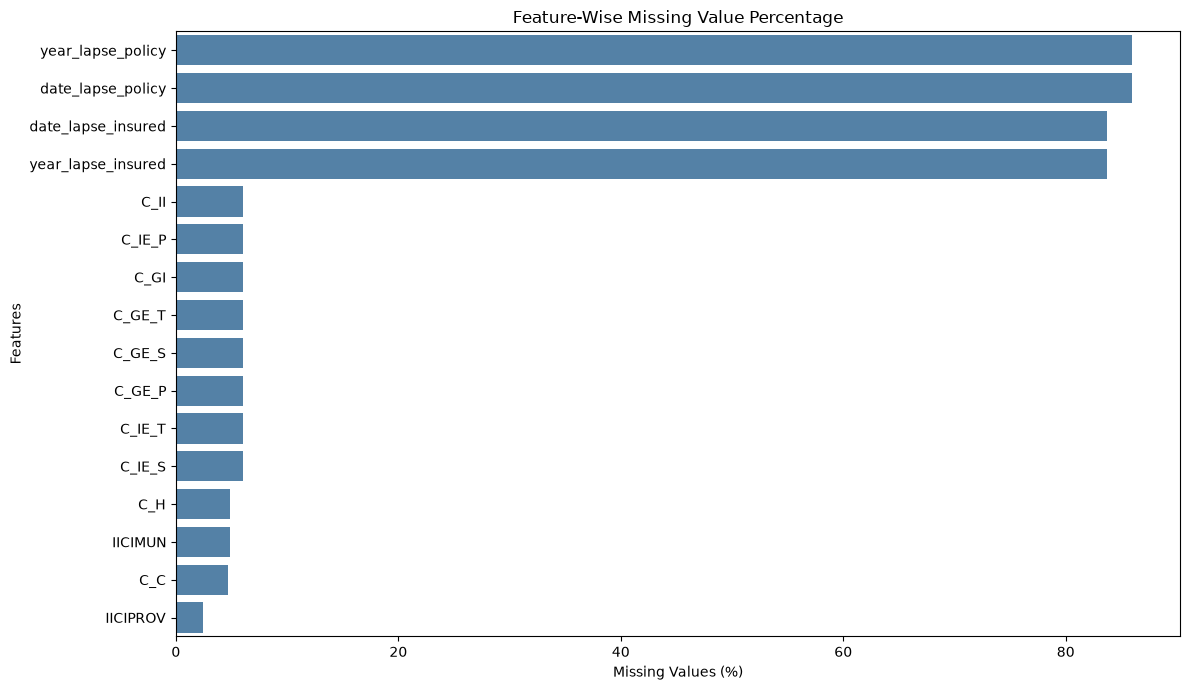

In [34]:

import matplotlib.pyplot as plt
import seaborn as sns

missing_plot = missing_summary[
    missing_summary["Missing Count"] > 0
]

plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_plot["Missing Percentage"],
    y=missing_plot.index,
    color="steelblue"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.title("Feature-Wise Missing Value Percentage")

plt.tight_layout()
plt.show()


### 4.5 Row-Wise Missing Values

#### Examine the number of missing attributes per observation to determine whether missingness is concentrated within particular records.

In [35]:

row_missing = df.isna().sum(axis=1)

row_missing_summary = (
    row_missing
    .value_counts()
    .sort_index()
    .rename_axis("Missing Features per Row")
    .reset_index(name="Number of Rows")
)

row_missing_summary["Percentage"] = (
    row_missing_summary["Number of Rows"]
    / len(df) * 100
)

display(row_missing_summary.round(2))

print("Complete observations:", (row_missing == 0).sum())
print("Rows with missing values:", (row_missing > 0).sum())


,Missing Features per Row,Number of Rows,Percentage
0,0,15187,12.32
1,1,1,0.00
2,2,2609,2.12
3,4,98044,79.52
4,5,32,0.03
5,7,10,0.01
6,8,138,0.11
7,10,94,0.08
8,11,228,0.18
9,12,2929,2.38


Complete observations: 15187
Rows with missing values: 108111


### 4.6 Missingness Heatmap

#### Visualize missing-value locations across a representative sample of observations to investigate whether missingness exhibits visible patterns.

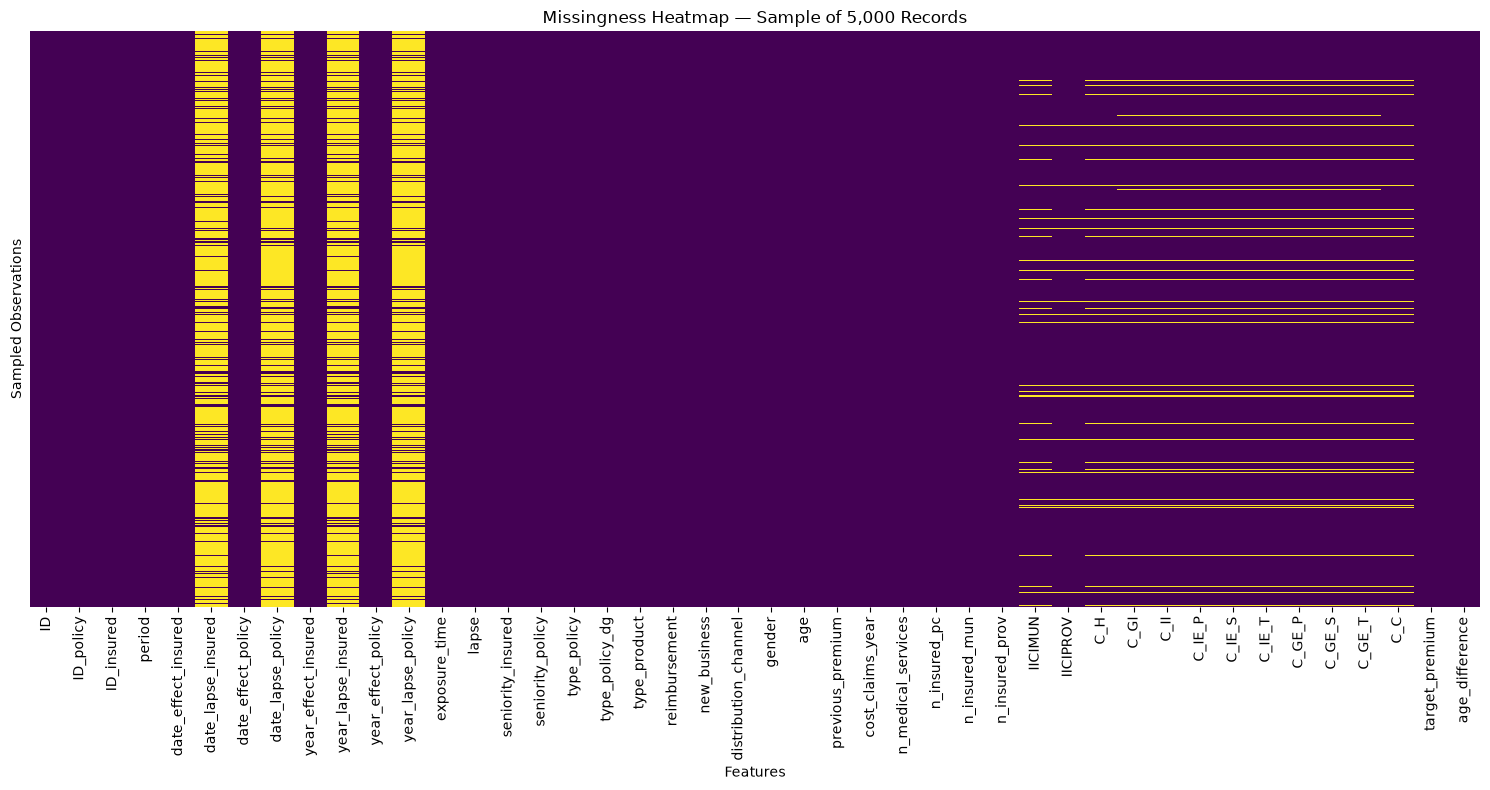

In [36]:

missing_sample = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(15, 8))

sns.heatmap(
    missing_sample.isna(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missingness Heatmap — Sample of 5,000 Records")
plt.xlabel("Features")
plt.ylabel("Sampled Observations")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


### 4.7 Missingness Pattern Analysis

#### Identify the most frequent combinations of missing attributes to determine whether multiple features tend to be missing within the same observations.

In [37]:

missing_cols = df.columns[df.isna().any()].tolist()

missing_patterns = (
    df[missing_cols]
    .isna()
    .groupby(missing_cols, dropna=False)
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Count")
)

missing_patterns["Percentage"] = (
    missing_patterns["Count"] / len(df) * 100
)

display(missing_patterns.head(20))


,date_lapse_insured,date_lapse_policy,year_lapse_insured,year_lapse_policy,IICIMUN,IICIPROV,C_H,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C,Count,Percentage
0,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,98044,79.517916
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,15187,12.317313
2,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,2609,2.116012
3,True,True,True,True,True,False,True,True,True,True,True,True,True,True,True,True,2424,1.965969
4,False,False,False,False,True,True,True,True,True,True,True,True,True,True,True,True,1686,1.367419
5,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,1252,1.015426
6,True,True,True,True,False,False,False,True,True,True,True,True,True,True,True,False,1231,0.998394
7,False,False,False,False,True,False,True,True,True,True,True,True,True,True,True,True,228,0.184918
8,True,True,True,True,True,False,True,True,True,True,True,True,True,True,True,False,228,0.184918
9,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True,False,138,0.111924


### 4.8 Missingness Correlation

#### Examine correlations between missing-value indicators to identify features that tend to be missing together.

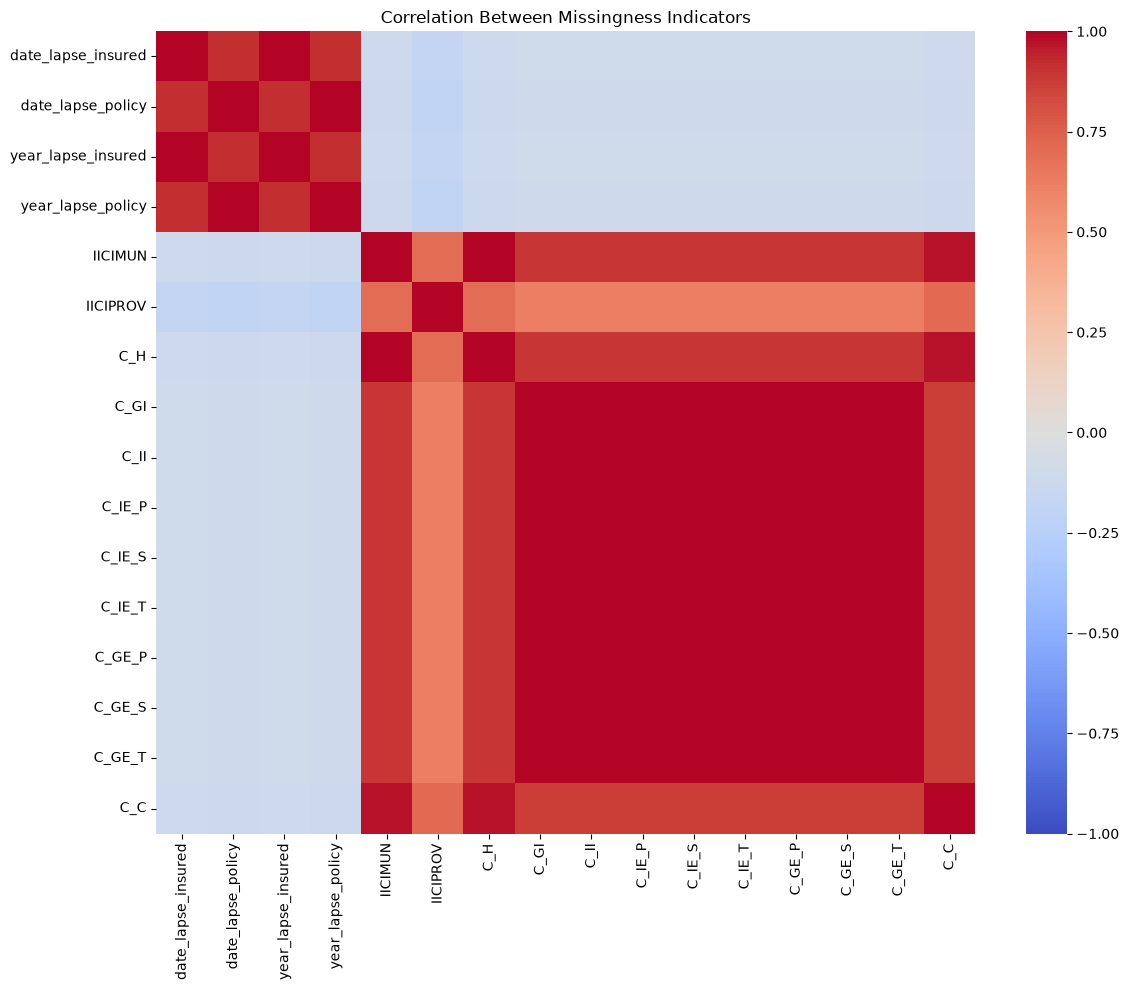

In [38]:

missing_indicators = df[missing_cols].isna().astype(int)

varying_missing_cols = missing_indicators.columns[
    missing_indicators.nunique() > 1
]

missing_corr = missing_indicators[
    varying_missing_cols
].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    missing_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Missingness Indicators")
plt.tight_layout()
plt.show()


### 4.9 Missingness Across Observation Years

#### Compare missing-value percentages between observation periods to investigate whether data completeness changes over time.

In [39]:

year_missing = (
    df.groupby("period")[missing_cols]
    .apply(lambda x: x.isna().mean() * 100)
)

display(year_missing.round(2))


,date_lapse_insured,date_lapse_policy,year_lapse_insured,year_lapse_policy,IICIMUN,IICIPROV,C_H,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C
period,,,,,,,,,,,,,,,,
2017,77.33,80.29,77.33,80.29,6.06,3.61,6.06,7.22,7.22,7.22,7.22,7.22,7.22,7.22,7.22,5.81
2018,90.50,92.00,90.50,92.00,3.62,1.17,3.62,4.74,4.74,4.74,4.74,4.74,4.74,4.74,4.74,3.45


### 4.10 Missingness Association with Observed Features

#### Investigate whether missingness varies across observation years, policy types, and other observed characteristics to assess possible systematic missingness patterns.

In [40]:

from scipy.stats import chi2_contingency

results = []

for missing_col in missing_cols:

    missing_flag = df[missing_col].isna()

    for group_col in ["period", "type_policy", "gender"]:

        if missing_col == group_col:
            continue

        contingency = pd.crosstab(
            df[group_col].fillna("Missing").astype(str),
            missing_flag
        )

        if contingency.shape[0] < 2 or contingency.shape[1] < 2:
            continue

        chi2, p_value, dof, expected = chi2_contingency(
            contingency
        )

        results.append({
            "Missing Feature": missing_col,
            "Observed Feature": group_col,
            "Chi-Square": chi2,
            "P-Value": p_value
        })

association_results = pd.DataFrame(results)

display(
    association_results.sort_values("P-Value").round(5)
)


,Missing Feature,Observed Feature,Chi-Square,P-Value
0,date_lapse_insured,period,3921.51557,0.00000
3,date_lapse_policy,period,3498.38167,0.00000
6,year_lapse_insured,period,3921.51557,0.00000
9,year_lapse_policy,period,3498.38167,0.00000
16,IICIPROV,type_policy,845.08981,0.00000
15,IICIPROV,period,775.54122,0.00000
18,C_H,period,394.83121,0.00000
12,IICIMUN,period,394.83121,0.00000
45,C_C,period,384.76639,0.00000
24,C_II,period,334.14390,0.00000


### 4.11 Missing Values Summary

#### Summarize the extent, concentration, and observed patterns of missingness to guide evidence-based missing-data treatment during preprocessing.

In [41]:

print("Overall missing percentage:",
      round(df.isna().mean().mean() * 100, 2))

print("Features with missing values:",
      len(missing_cols))

print("Rows containing missing values:",
      (df.isna().any(axis=1)).sum())

print("Complete rows:",
      df.notna().all(axis=1).sum())

print("\nTop 10 features by missing percentage:")

display(
    missing_summary[
        ["Missing Count", "Missing Percentage"]
    ].head(10).round(2)
)


Overall missing percentage: 9.19
Features with missing values: 16
Rows containing missing values: 108111
Complete rows: 15187

Top 10 features by missing percentage:


,Missing Count,Missing Percentage
year_lapse_policy,106004,85.97
date_lapse_policy,106004,85.97
date_lapse_insured,103227,83.72
year_lapse_insured,103227,83.72
C_II,7415,6.01
C_IE_P,7415,6.01
C_GI,7415,6.01
C_GE_T,7415,6.01
C_GE_S,7415,6.01
C_GE_P,7415,6.01


#### Missingness exhibits distinct co-occurrence patterns. Termination-related attributes frequently occur as a missing block, while eight socioeconomic indicators share identical missingness patterns. Other geographical attributes show partial overlap, suggesting differences in contextual data availability.

#### Chi-square tests reveal significant associations between missingness and several observed variables, particularly observation period and policy type. These findings suggest systematic missingness patterns, although statistical significance alone does not establish practical importance or the underlying missingness mechanism.

### Missingness Rates Across Observed Groups

#### Compare missing-value percentages across observation periods and policy categories to assess the magnitude and direction of statistically significant missingness associations.

In [42]:

features_to_check = [
    "date_lapse_insured",
    "date_lapse_policy",
    "IICIPROV",
    "C_GI",
    "C_H",
    "C_C"
]

missing_by_period = (
    df.groupby("period")[features_to_check]
    .apply(lambda x: x.isna().mean() * 100)
)

display(missing_by_period.round(2))


,date_lapse_insured,date_lapse_policy,IICIPROV,C_GI,C_H,C_C
period,,,,,,
2017,77.33,80.29,3.61,7.22,6.06,5.81
2018,90.50,92.00,1.17,4.74,3.62,3.45


#### Examine whether geographical missingness differs between policy types to assess potential relationships between insurance characteristics and data completeness.

In [43]:

missing_by_policy = (
    df.groupby("type_policy")[features_to_check]
    .apply(lambda x: x.isna().mean() * 100)
)

display(missing_by_policy.round(2))


,date_lapse_insured,date_lapse_policy,IICIPROV,C_GI,C_H,C_C
type_policy,,,,,,
C,82.52,85.35,4.01,5.45,4.80,4.73
I,84.50,86.38,1.40,6.38,4.92,4.62


#### Missingness varies substantially across observation periods. Termination-related attributes exhibit higher missingness in 2018, potentially reflecting observation-window effects, while geographical and socioeconomic attributes exhibit lower missingness in 2018. These temporal differences indicate systematic missingness patterns.

### Part 4 — Missing Values Analysis: Summary

#### The renewal dataset exhibits structured missingness concentrated in termination-related and geographical/socioeconomic attributes. Approximately 79.52% of observations have exactly four missing termination variables, while eight socioeconomic indicators share identical missingness patterns. Missingness varies significantly across observation periods, with termination-related missingness increasing and geographical missingness decreasing from 2017 to 2018. Policy-type differences are most pronounced for IICIPROV. These findings indicate that missingness is not uniformly random across observed groups; structural missingness and MAR are plausible explanations for different feature groups, but the underlying mechanisms remain unconfirmed.

### 5.1 Numerical Feature Selection

#### Identify numerical attributes for distribution analysis, excluding identifiers, dates, categorical codes, and the target variable.

In [44]:

numerical_features = [
    col for col in num_cols
    if col in df.columns
]

print("Total numerical features:", len(numerical_features))
print(numerical_features)


Total numerical features: 21
['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'previous_premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'age_difference']


### 5.2 Descriptive Statistics

#### Calculate the mean, median, standard deviation, minimum, maximum, and quartiles to understand the central tendency and variability of numerical attributes.

In [45]:

numerical_summary = df[numerical_features].describe().T

numerical_summary["median"] = (
    df[numerical_features].median()
)

display(numerical_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,median
exposure_time,123298.0,0.986,0.119,0.00,1.000,1.00,1.00,1.00,1.00
seniority_insured,123298.0,14.151,13.148,0.00,3.000,12.00,23.00,85.00,12.00
seniority_policy,123298.0,15.154,14.119,0.00,3.000,13.00,23.00,86.00,13.00
age,123298.0,46.387,23.013,0.00,31.000,48.00,64.00,99.00,48.00
previous_premium,123298.0,874.596,547.157,33.33,591.860,789.48,1027.17,15339.78,789.48
cost_claims_year,123298.0,633.662,1639.917,0.00,34.680,228.26,602.82,78035.10,228.26
n_medical_services,123298.0,16.668,25.852,0.00,1.000,7.00,23.00,1029.00,7.00
n_insured_pc,123298.0,309.082,450.406,1.00,46.000,120.00,410.00,2518.00,120.00
n_insured_mun,123298.0,5981.457,7849.178,1.00,107.000,1234.00,17991.00,19315.00,1234.00
n_insured_prov,123298.0,13803.217,12021.780,4.00,2872.000,7467.00,27261.00,29465.00,7467.00


### 5.3 Numerical Feature Histograms

#### Visualize the frequency distributions of numerical variables to identify asymmetry, concentration, multimodality, and unusual observations.

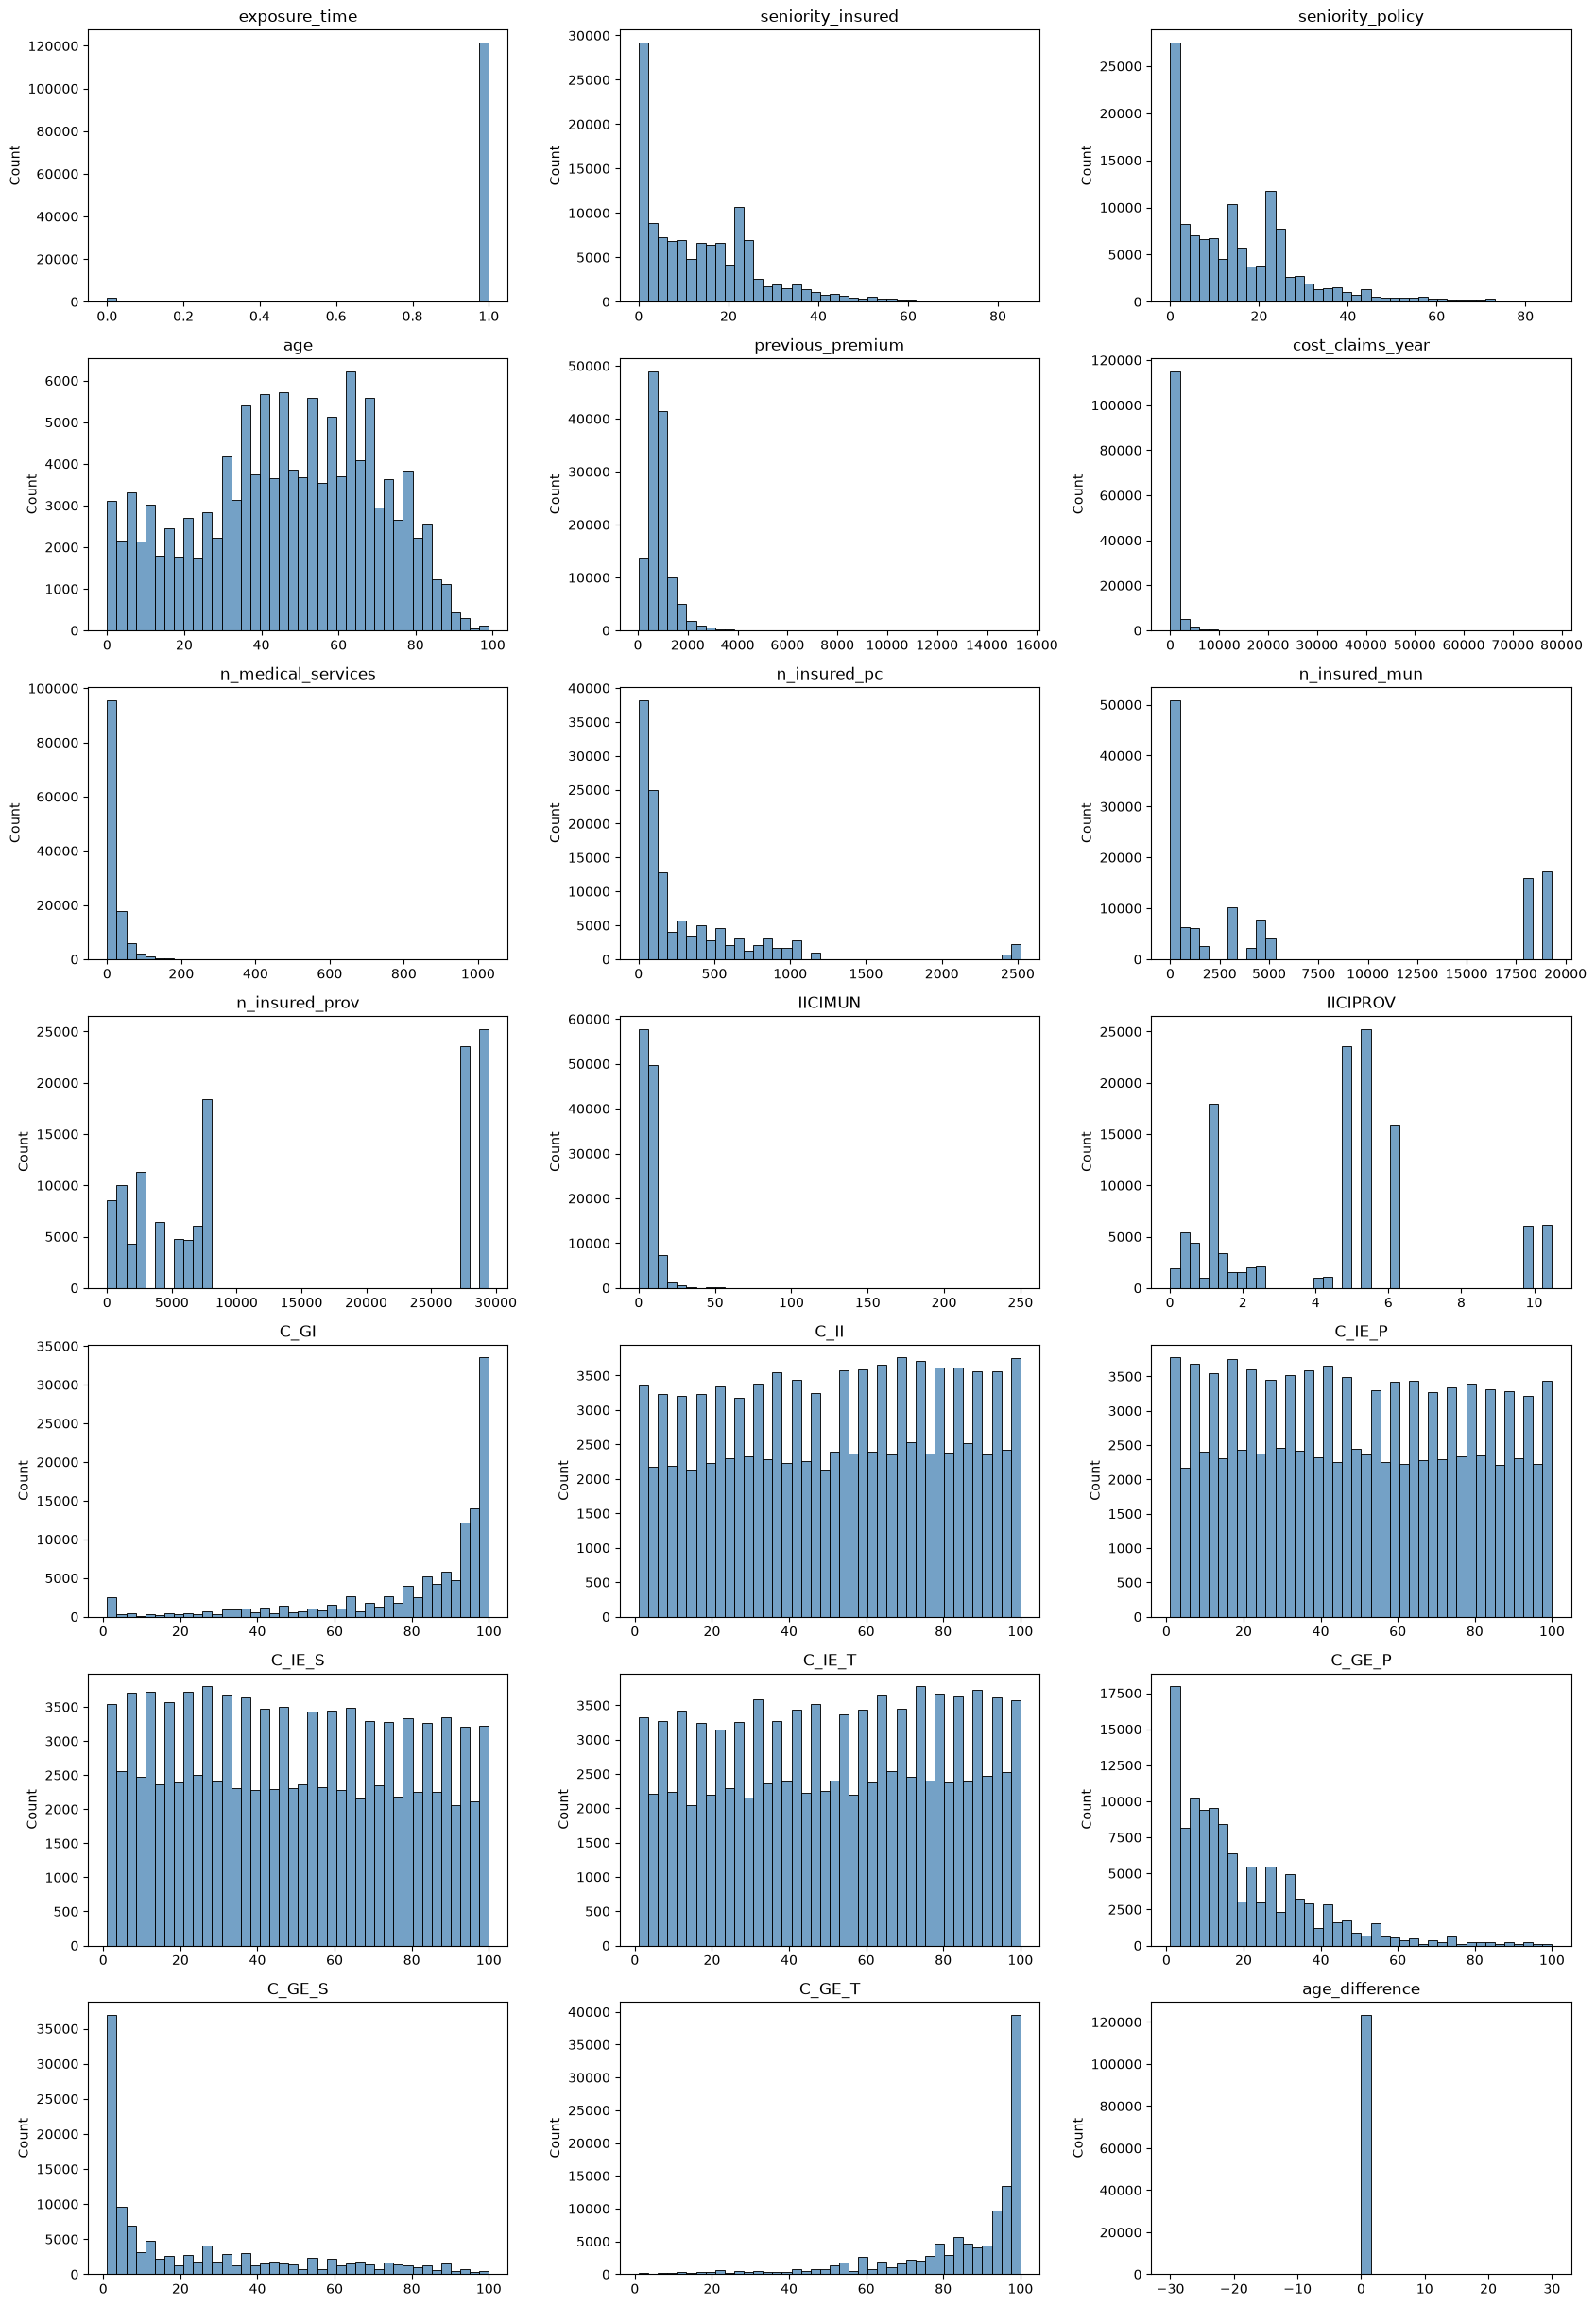

In [46]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

n_cols = 3
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(17, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=col,
        bins=40,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")

for j in range(len(numerical_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 5.4 Kernel Density Estimation

#### Examine smoothed distributions of continuous numerical variables to identify skewness, peaks, and possible multimodal patterns.

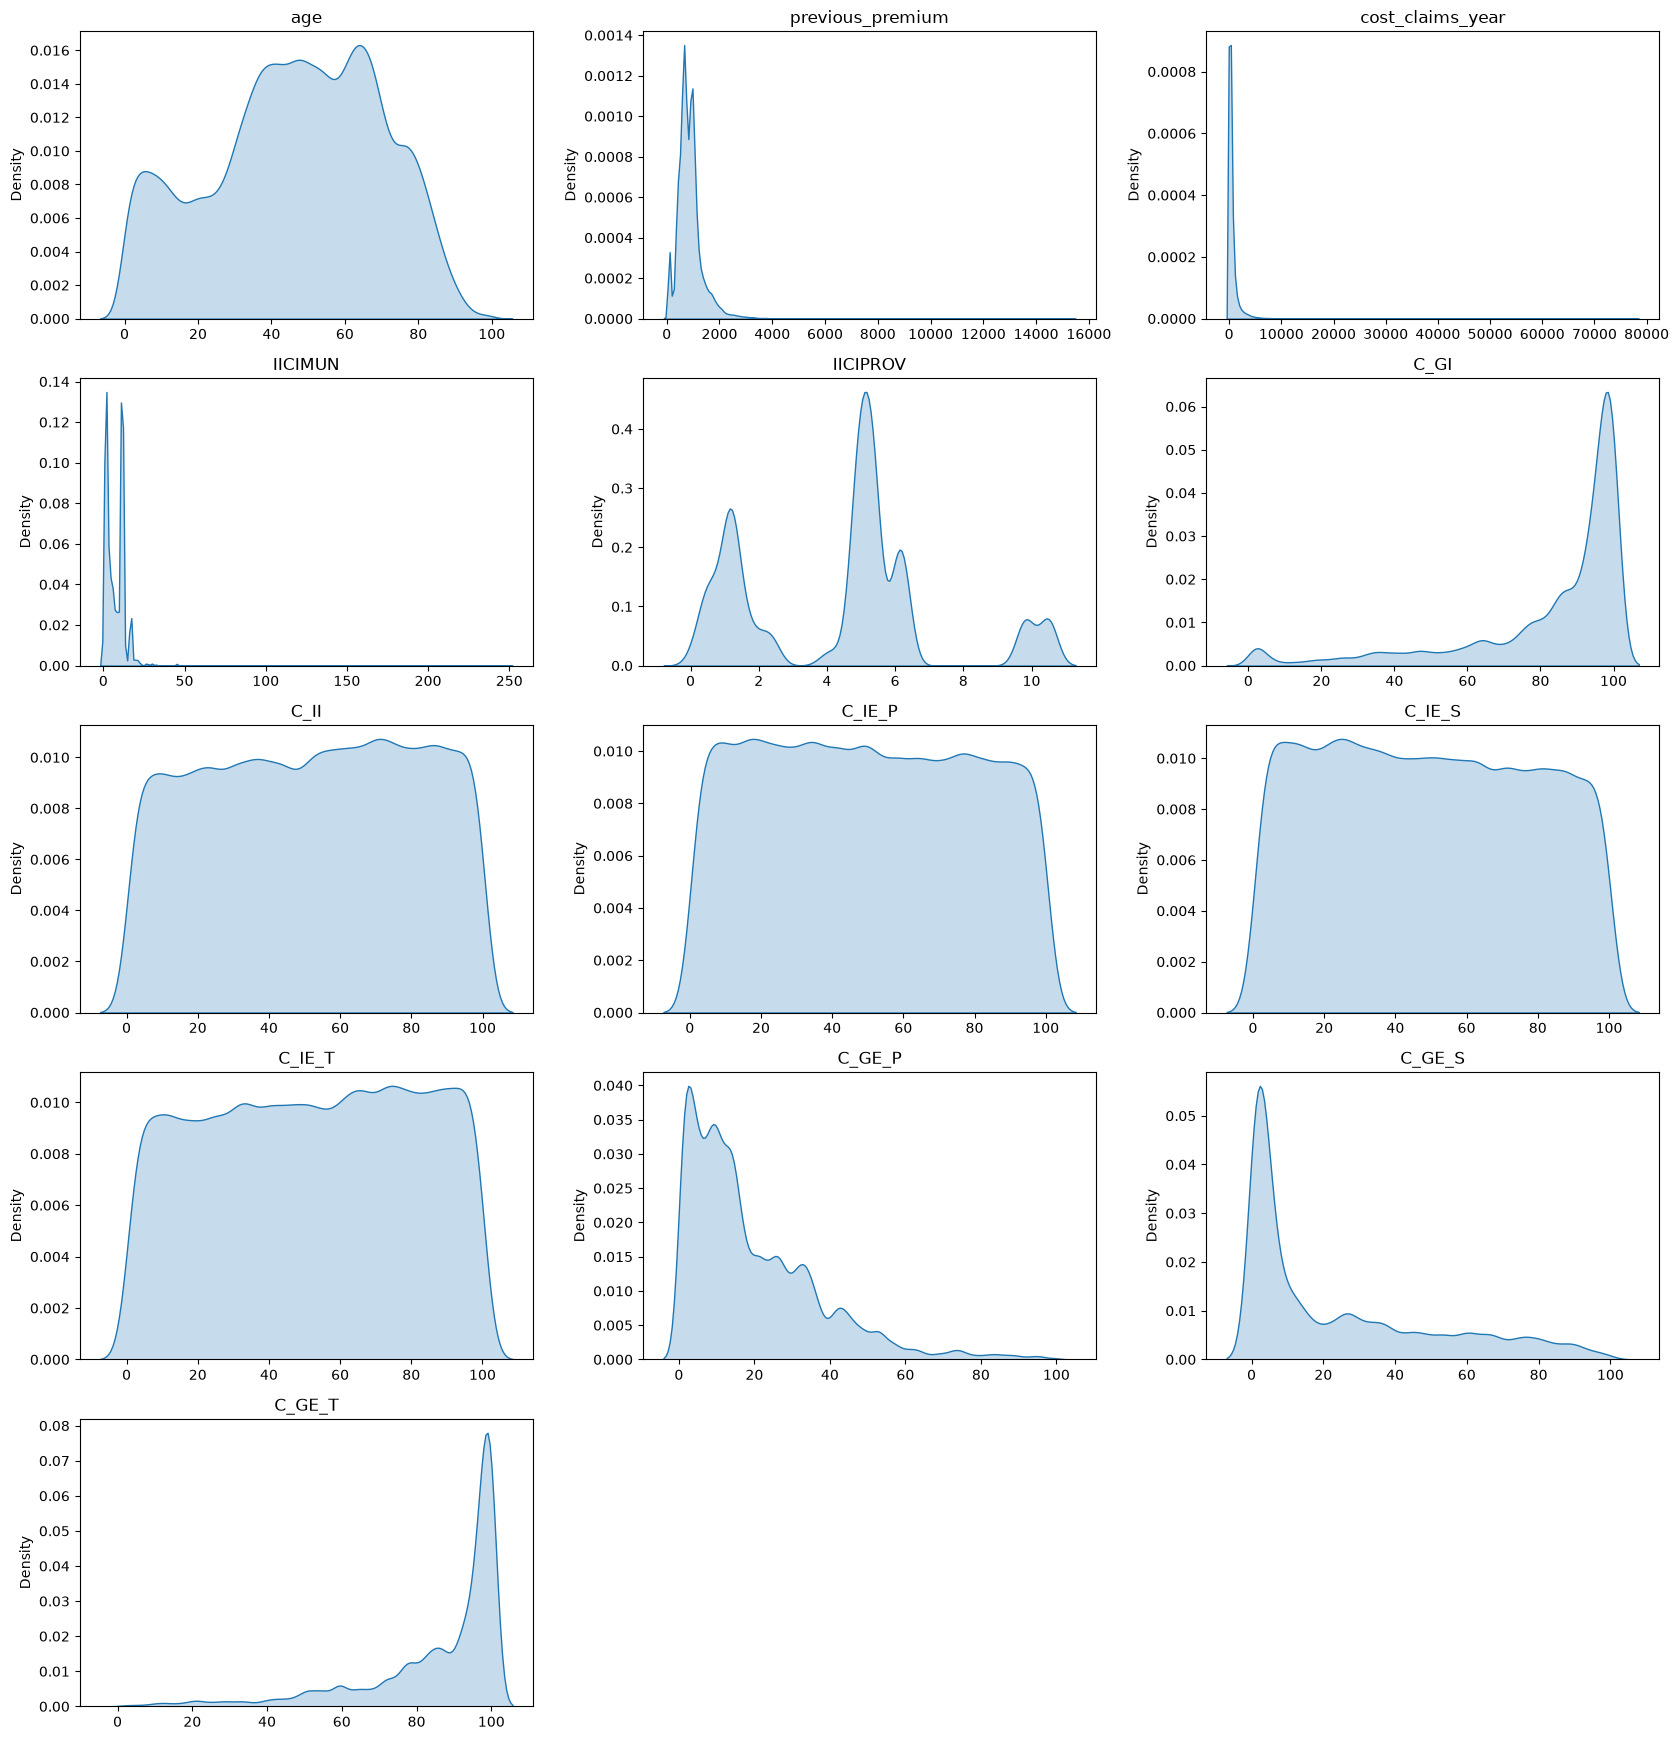

In [47]:

# KDE is intended for approximately continuous variables.
# Exclude counts, binary indicators, and constant variables.

continuous_features = [
    "age",
    "previous_premium",
    "cost_claims_year",
    "IICIMUN",
    "IICIPROV",
    "C_GI",
    "C_II",
    "C_IE_P",
    "C_IE_S",
    "C_IE_T",
    "C_GE_P",
    "C_GE_S",
    "C_GE_T"
]

continuous_features = [
    col for col in continuous_features
    if col in numerical_features
    and df[col].nunique(dropna=True) > 1
]

n_cols = 3
n_rows = int(np.ceil(len(continuous_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(17, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(continuous_features):
    sns.kdeplot(
        data=df,
        x=col,
        fill=True,
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")

for j in range(len(continuous_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 5.5 Numerical Feature Boxplots

#### Examine numerical variables using boxplots to identify dispersion, asymmetry, and potential extreme observations.

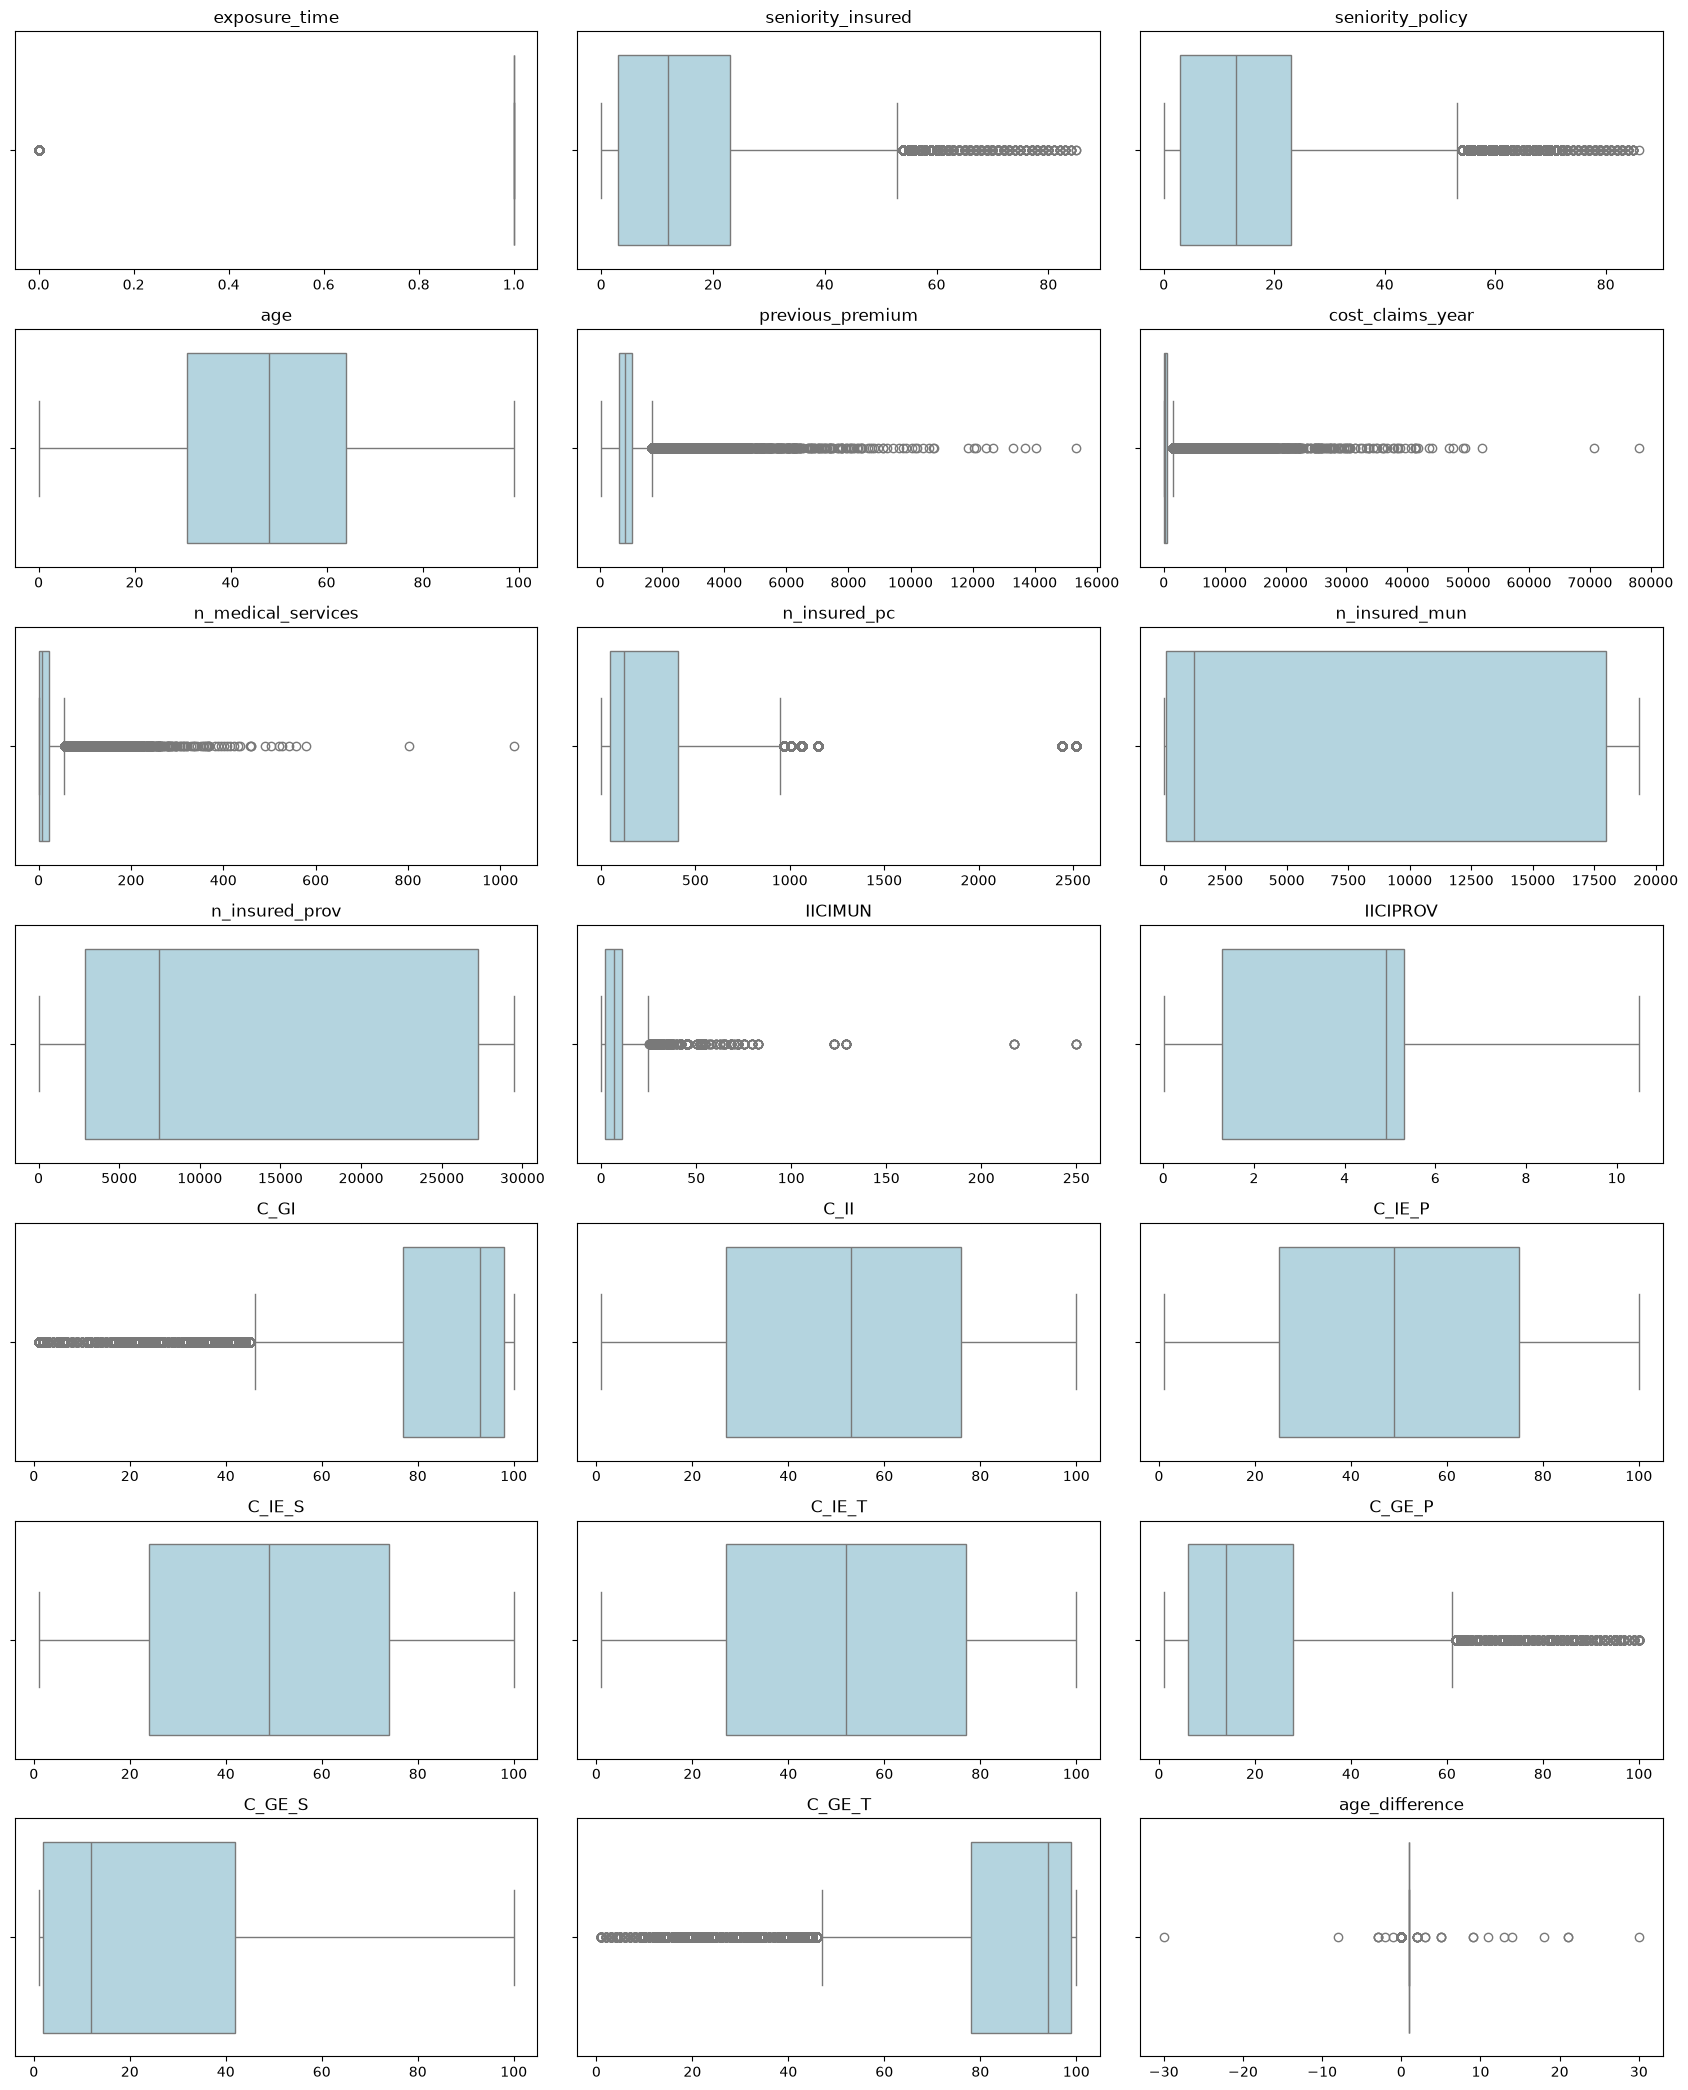

In [48]:

n_cols = 3
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(17, n_rows * 3)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(
        x=df[col],
        ax=axes[i],
        color="lightblue"
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")

for j in range(len(numerical_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 5.6 Skewness Analysis

#### Measure distribution asymmetry to identify numerical variables with long positive or negative tails.

In [49]:

skewness_summary = pd.DataFrame({
    "Feature": numerical_features,
    "Skewness": [
        df[col].skew() for col in numerical_features
    ]
})

skewness_summary["Absolute Skewness"] = (
    skewness_summary["Skewness"].abs()
)

skewness_summary = skewness_summary.sort_values(
    "Absolute Skewness",
    ascending=False
)

display(skewness_summary.round(3))


,Feature,Skewness,Absolute Skewness
5,cost_claims_year,10.895,10.895
20,age_difference,9.048,9.048
0,exposure_time,-8.170,8.170
10,IICIMUN,6.306,6.306
6,n_medical_services,4.551,4.551
4,previous_premium,4.370,4.370
7,n_insured_pc,3.013,3.013
19,C_GE_T,-1.811,1.811
12,C_GI,-1.790,1.790
17,C_GE_P,1.470,1.470


### 5.7 Kurtosis Analysis

#### Measure excess kurtosis to examine tail heaviness and the influence of extreme observations in numerical distributions.

In [50]:

kurtosis_summary = pd.DataFrame({
    "Feature": numerical_features,
    "Excess Kurtosis": [
        df[col].kurt() for col in numerical_features
    ]
})

kurtosis_summary = kurtosis_summary.sort_values(
    "Excess Kurtosis",
    ascending=False
)

display(kurtosis_summary.round(3))


,Feature,Excess Kurtosis
20,age_difference,4430.620
5,cost_claims_year,217.023
10,IICIMUN,153.038
0,exposure_time,64.756
6,n_medical_services,57.454
4,previous_premium,49.515
7,n_insured_pc,11.128
19,C_GE_T,3.060
12,C_GI,2.534
2,seniority_policy,2.477


### 5.8 Zero-Value Analysis

#### Examine the frequency of zero values in numerical features to identify zero-inflated distributions and distinguish potentially meaningful zeros from unusual observations.

In [51]:

zero_summary = pd.DataFrame({
    "Feature": numerical_features,
    "Zero Count": [
        (df[col] == 0).sum()
        for col in numerical_features
    ],
    "Zero Percentage": [
        (df[col] == 0).mean() * 100
        for col in numerical_features
    ]
})

zero_summary = zero_summary.sort_values(
    "Zero Percentage",
    ascending=False
)

display(zero_summary.round(2))


,Feature,Zero Count,Zero Percentage
5,cost_claims_year,28058,22.76
6,n_medical_services,28058,22.76
1,seniority_insured,13752,11.15
2,seniority_policy,13084,10.61
20,age_difference,4168,3.38
0,exposure_time,1768,1.43
3,age,998,0.81
4,previous_premium,0,0.00
7,n_insured_pc,0,0.00
9,n_insured_prov,0,0.00


### 5.9 Numerical Feature Cardinality

#### Inspect the number of distinct values in numerical attributes to identify discrete, continuous, binary, and near-constant variables.

In [52]:

cardinality_summary = pd.DataFrame({
    "Feature": numerical_features,
    "Unique Values": [
        df[col].nunique(dropna=True)
        for col in numerical_features
    ],
    "Unique Percentage": [
        df[col].nunique(dropna=True) / len(df) * 100
        for col in numerical_features
    ]
})

display(
    cardinality_summary.sort_values(
        "Unique Values"
    ).round(2)
)


,Feature,Unique Values,Unique Percentage
0,exposure_time,2,0.00
20,age_difference,17,0.01
11,IICIPROV,72,0.06
1,seniority_insured,86,0.07
2,seniority_policy,87,0.07
9,n_insured_prov,99,0.08
12,C_GI,100,0.08
13,C_II,100,0.08
14,C_IE_P,100,0.08
15,C_IE_S,100,0.08


### 5.10 Numerical Distributions by Observation Year

#### Compare numerical feature distributions between 2017 and 2018 to identify possible temporal changes in the renewal insurance population.

In [53]:

yearly_numerical_summary = (
    df.groupby("period")[numerical_features]
    .agg(["count", "mean", "median", "std"])
)

display(yearly_numerical_summary.round(2))


exposure_time                    seniority_insured                      \
               count  mean median   std             count   mean median   std   
period                                                                          
2017           63467  0.97    1.0  0.16             63467  13.94   12.0  13.0   
2018           59831  1.00    1.0  0.00             59831  14.38   12.0  13.3   

       seniority_policy         ... C_GE_S        C_GE_T                       \
                  count   mean  ... median    std  count   mean median    std   
period                          ...                                             
2017              63467  14.95  ...   11.0  27.11  58887  85.39   94.0  19.31   
2018              59831  15.37  ...   12.0  27.33  56996  85.11   93.0  19.38   

       age_difference                     
                count  mean median   std  
period                                    
2017            63467  0.97    1.0  0.22  
2018            59831  0.96    1.0  0.28  

[2 rows x 84 columns]

### 5.11 Numerical Distribution Summary

#### Consolidate descriptive statistics, distribution shape, zero frequencies, and feature cardinality to identify variables requiring closer investigation during preprocessing.

In [54]:

distribution_summary = pd.DataFrame({
    "Feature": numerical_features,
    "Mean": df[numerical_features].mean(),
    "Median": df[numerical_features].median(),
    "Std": df[numerical_features].std(),
    "Skewness": df[numerical_features].skew(),
    "Excess Kurtosis": df[numerical_features].kurt(),
    "Zero %": (
        df[numerical_features].eq(0).mean() * 100
    ),
    "Unique Values": df[numerical_features].nunique()
})

display(distribution_summary.round(3))


,Feature,Mean,Median,Std,Skewness,Excess Kurtosis,Zero %,Unique Values
exposure_time,exposure_time,0.986,1.00,0.119,-8.170,64.756,1.434,2
seniority_insured,seniority_insured,14.151,12.00,13.148,1.248,1.985,11.153,86
seniority_policy,seniority_policy,15.154,13.00,14.119,1.368,2.477,10.612,87
age,age,46.387,48.00,23.013,-0.230,-0.813,0.809,100
previous_premium,previous_premium,874.596,789.48,547.157,4.370,49.515,0.000,5835
cost_claims_year,cost_claims_year,633.662,228.26,1639.917,10.895,217.023,22.756,9273
n_medical_services,n_medical_services,16.668,7.00,25.852,4.551,57.454,22.756,312
n_insured_pc,n_insured_pc,309.082,120.00,450.406,3.013,11.128,0.000,285
n_insured_mun,n_insured_mun,5981.457,1234.00,7849.178,0.941,-0.977,0.000,228
n_insured_prov,n_insured_prov,13803.217,7467.00,12021.780,0.343,-1.748,0.000,99


### 6.1 Categorical Feature Identification

#### Identify categorical attributes and examine their distinct values to understand the structure of qualitative and coded variables.

In [55]:

categorical_features = [
    col for col in cat_cols
    if col in df.columns
]

print("Total categorical features:", len(categorical_features))
print(categorical_features)


Total categorical features: 10
['lapse', 'type_policy', 'type_policy_dg', 'type_product', 'reimbursement', 'new_business', 'distribution_channel', 'gender', 'C_H', 'C_C']


### 6.2 Categorical Descriptive Statistics

#### Examine category cardinality, most frequent values, and dominant-category proportions to identify imbalanced or low-variability attributes.

In [56]:

categorical_summary = pd.DataFrame({
    "Feature": categorical_features,
    "Unique Categories": [
        df[col].nunique(dropna=True)
        for col in categorical_features
    ],
    "Most Frequent Category": [
        df[col].mode(dropna=True).iloc[0]
        if not df[col].mode(dropna=True).empty
        else np.nan
        for col in categorical_features
    ],
    "Dominant Category %": [
        df[col].value_counts(
            normalize=True, dropna=False
        ).iloc[0] * 100
        for col in categorical_features
    ],
    "Missing %": [
        df[col].isna().mean() * 100
        for col in categorical_features
    ]
})

display(categorical_summary.round(2))


,Feature,Unique Categories,Most Frequent Category,Dominant Category %,Missing %
0,lapse,1,2,100.00,0.00
1,type_policy,2,I,60.67,0.00
2,type_policy_dg,6,I,47.38,0.00
3,type_product,4,S,77.38,0.00
4,reimbursement,2,No,82.45,0.00
5,new_business,2,No,88.85,0.00
6,distribution_channel,3,I,65.16,0.00
7,gender,2,F,54.63,0.00
8,C_H,6,H6,58.76,4.87
9,C_C,6,C3,46.31,4.67


### 6.3 Category Frequency Distributions

#### Calculate the count and percentage of each category to assess the distribution and representation of categorical values.

In [57]:

for col in categorical_features:

    counts = df[col].value_counts(dropna=False)

    frequency_table = pd.DataFrame({
        "Count": counts,
        "Percentage": counts / len(df) * 100
    })

    print(f"\nFeature: {col}")
    display(frequency_table.round(2))



Feature: lapse


,Count,Percentage
lapse,,
2,123298,100.0



Feature: type_policy


,Count,Percentage
type_policy,,
I,74805,60.67
C,48493,39.33



Feature: type_policy_dg


,Count,Percentage
type_policy_dg,,
I,58420,47.38
C3,31356,25.43
SE,16385,13.29
C1,12853,10.42
C2,2485,2.02
C4,1799,1.46


... (10 outputs left out)


Feature: C_H


,Count,Percentage
C_H,,
H6,72445,58.76
H3,14563,11.81
H2,11284,9.15
H5,9178,7.44
H4,8411,6.82
NaN,6010,4.87
H1,1407,1.14



Feature: C_C


,Count,Percentage
C_C,,
C3,57103,46.31
C6,28480,23.10
C1,13115,10.64
C4,12434,10.08
NaN,5755,4.67
C5,3214,2.61
C2,3197,2.59


### 6.4 Categorical Distribution Visualization

#### Visualize category frequencies to identify dominant classes, minority categories, and differences in categorical distributions.

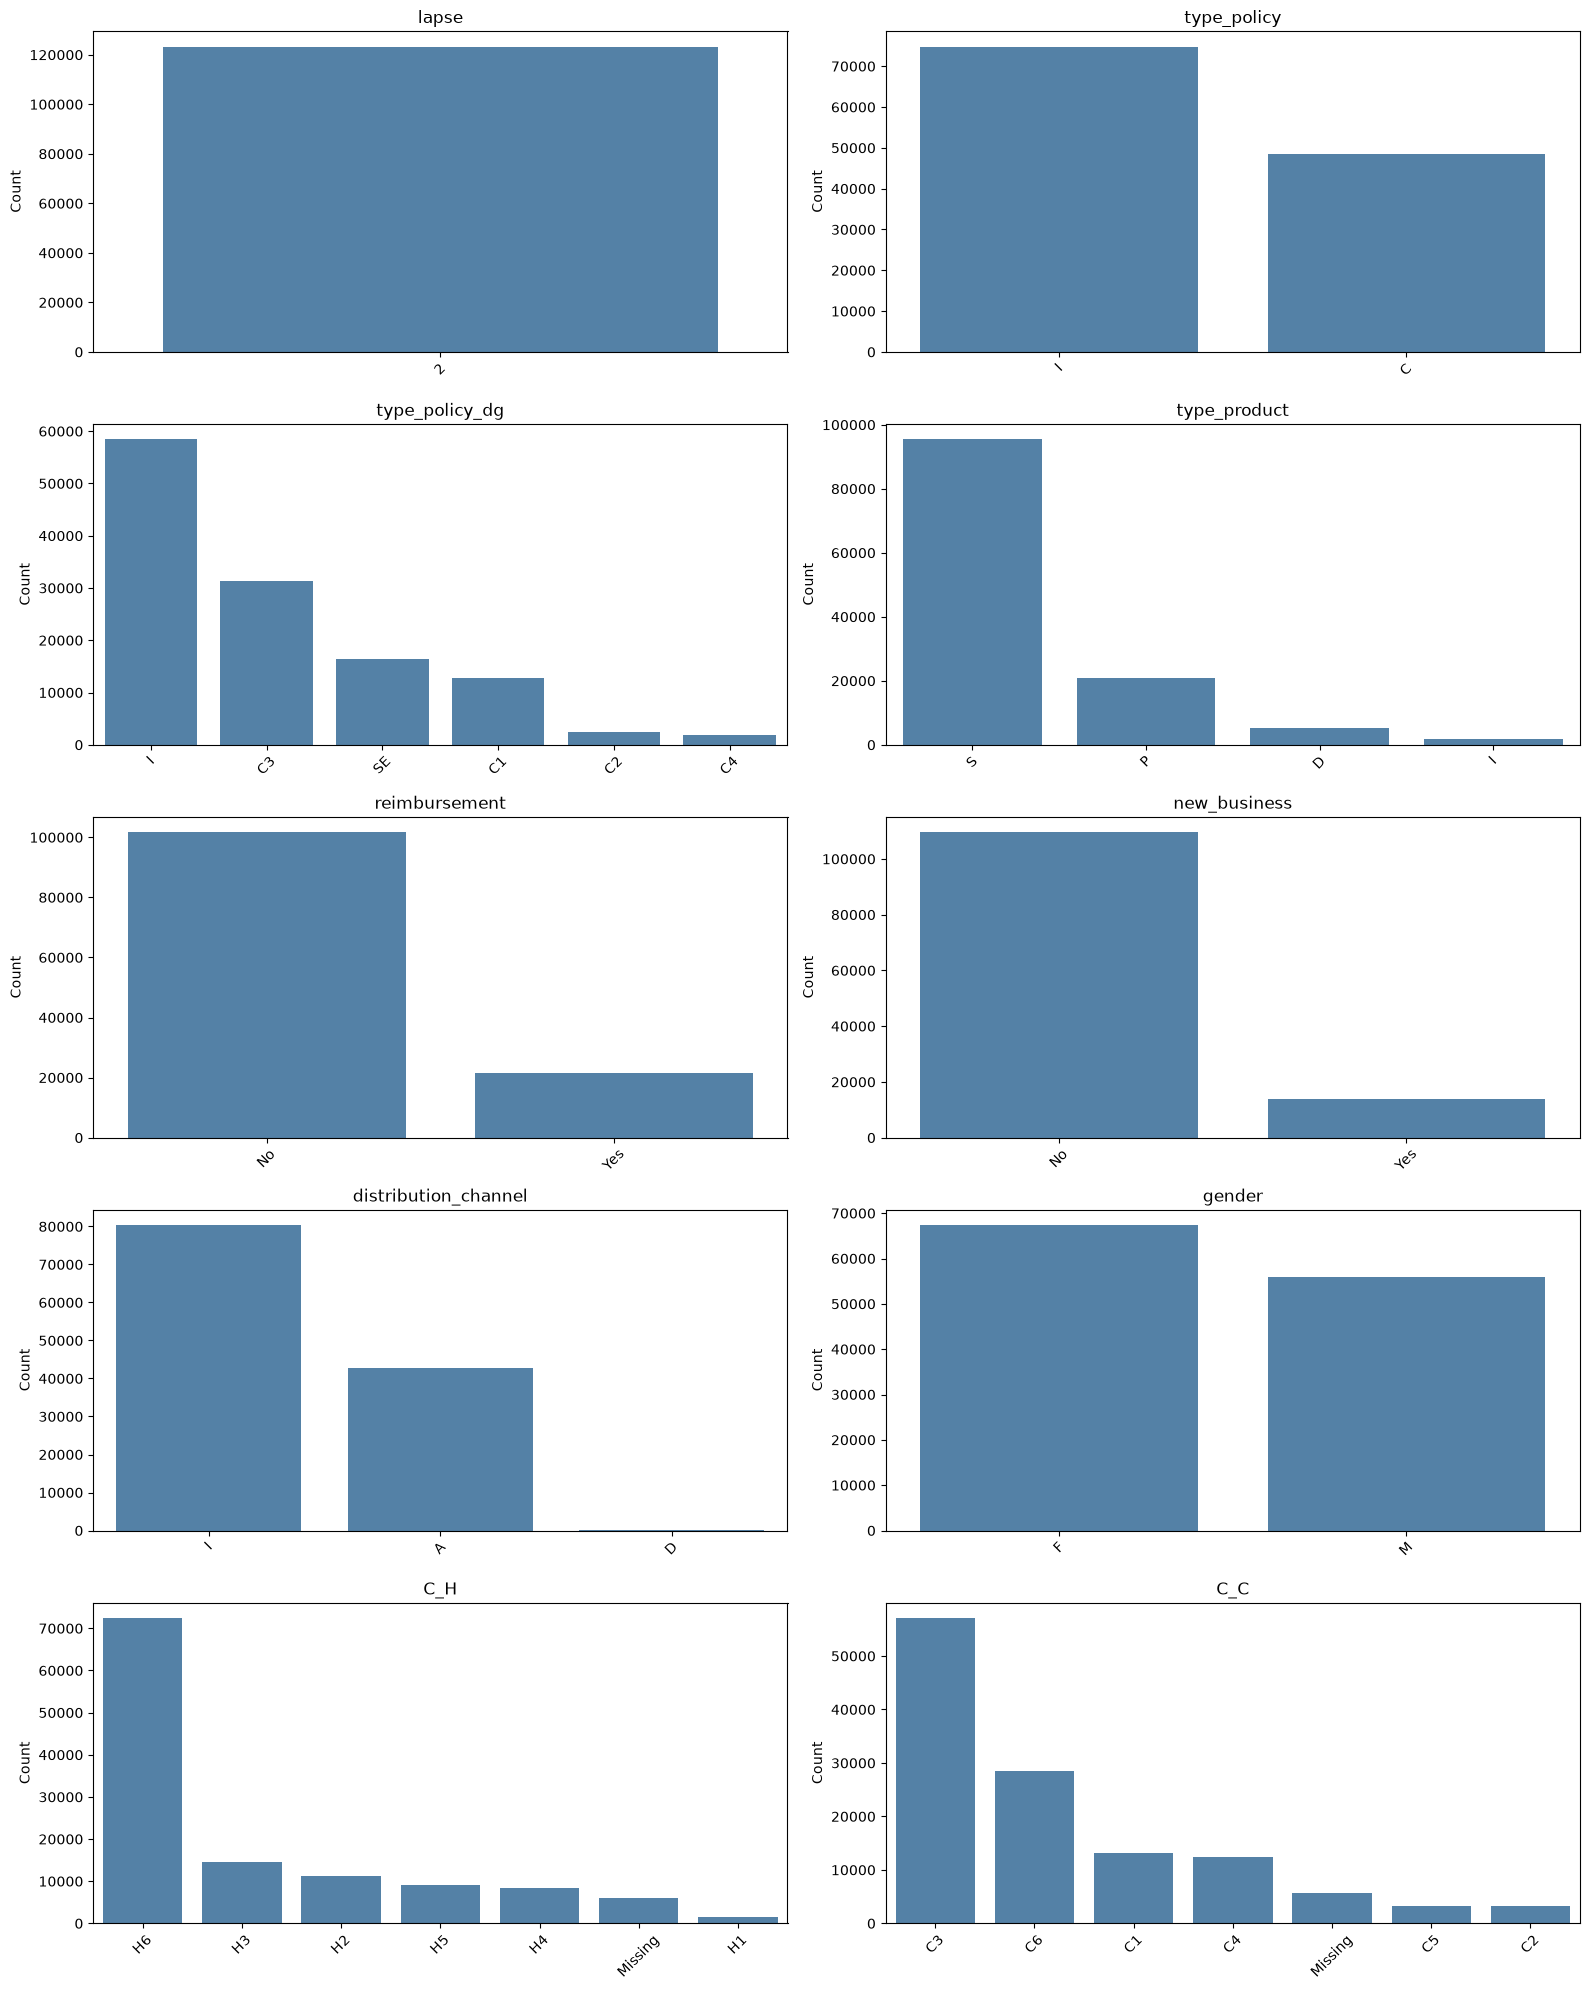

In [58]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plot_features = [
    col for col in categorical_features
    if df[col].nunique(dropna=True) <= 20
]

n_cols = 2
n_rows = int(np.ceil(len(plot_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 4)
)

axes = np.array(axes).flatten()

for i, col in enumerate(plot_features):

    values = (
        df[col]
        .astype("string")
        .fillna("Missing")
    )

    order = values.value_counts().index

    sns.countplot(
        x=values,
        order=order,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

for j in range(len(plot_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 6.5 Rare Category Analysis

#### Identify categories representing less than 1% of observations to assess sparsity and potential challenges for categorical encoding.

In [59]:

rare_category_results = []

for col in categorical_features:

    proportions = df[col].value_counts(
        normalize=True,
        dropna=True
    )

    rare = proportions[proportions < 0.01]

    rare_category_results.append({
        "Feature": col,
        "Total Categories": len(proportions),
        "Rare Categories (<1%)": len(rare),
        "Rows in Rare Categories": (
            df[col].isin(rare.index).sum()
        )
    })

rare_category_summary = pd.DataFrame(
    rare_category_results
)

display(rare_category_summary)


,Feature,Total Categories,Rare Categories (<1%),Rows in Rare Categories
0,lapse,1,0,0
1,type_policy,2,0,0
2,type_policy_dg,6,0,0
3,type_product,4,0,0
4,reimbursement,2,0,0
5,new_business,2,0,0
6,distribution_channel,3,1,140
7,gender,2,0,0
8,C_H,6,0,0
9,C_C,6,0,0


### 6.6 Categorical Imbalance and Constant Features

#### Identify categorical variables dominated by a single value, including features with no observed variation.

In [60]:

imbalance_results = []

for col in categorical_features:

    proportions = df[col].value_counts(
        normalize=True,
        dropna=False
    )

    imbalance_results.append({
        "Feature": col,
        "Unique Values": df[col].nunique(dropna=True),
        "Dominant Category %": proportions.iloc[0] * 100,
        "Constant": df[col].nunique(dropna=True) <= 1
    })

imbalance_summary = pd.DataFrame(
    imbalance_results
).sort_values(
    "Dominant Category %",
    ascending=False
)

display(imbalance_summary.round(2))


,Feature,Unique Values,Dominant Category %,Constant
0,lapse,1,100.00,True
5,new_business,2,88.85,False
4,reimbursement,2,82.45,False
3,type_product,4,77.38,False
6,distribution_channel,3,65.16,False
1,type_policy,2,60.67,False
8,C_H,6,58.76,False
7,gender,2,54.63,False
2,type_policy_dg,6,47.38,False
9,C_C,6,46.31,False


### 6.7 Categorical Distributions Across Observation Years

#### Compare category proportions across observation periods to identify changes in the composition of the insured population.

In [61]:

year_comparison_features = [
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "new_business",
    "distribution_channel",
    "gender"
]

for col in year_comparison_features:

    table = pd.crosstab(
        df["period"],
        df[col],
        normalize="index",
        dropna=False
    ) * 100

    print(f"\nFeature: {col}")
    display(table.round(2))



Feature: type_policy


type_policy,C,I
period,,
2017,41.21,58.79
2018,37.34,62.66



Feature: type_policy_dg


type_policy_dg,C1,C2,C3,C4,I,SE
period,,,,,,
2017,10.70,2.02,25.67,2.82,45.09,13.71
2018,10.14,2.01,25.18,0.02,49.82,12.84



Feature: type_product


type_product,D,I,P,S
period,,,,
2017,4.31,1.59,15.80,78.31
2018,4.31,1.16,18.13,76.40


... (4 outputs left out)


Feature: distribution_channel


distribution_channel,A,D,I
period,,,
2017,33.54,0.01,66.45
2018,35.98,0.23,63.79



Feature: gender


gender,F,M
period,,
2017,54.38,45.62
2018,54.89,45.11


### 6.8 Categorical Distributions by Policy Type

#### Examine whether product, reimbursement, distribution channel, and demographic categories differ across policy types.

In [62]:

policy_comparison_features = [
    "type_product",
    "reimbursement",
    "new_business",
    "distribution_channel",
    "gender"
]

for col in policy_comparison_features:

    table = pd.crosstab(
        df["type_policy"],
        df[col],
        normalize="index",
        dropna=False
    ) * 100

    print(f"\nFeature: {col}")
    display(table.round(2))



Feature: type_product


type_product,D,I,P,S
type_policy,,,,
C,0.47,0.50,7.47,91.56
I,6.79,1.95,23.07,68.19



Feature: reimbursement


reimbursement,No,Yes
type_policy,,
C,92.03,7.97
I,76.25,23.75



Feature: new_business


new_business,No,Yes
type_policy,,
C,90.66,9.34
I,87.67,12.33



Feature: distribution_channel


distribution_channel,A,D,I
type_policy,,,
C,21.92,0.00,78.08
I,43.03,0.19,56.79



Feature: gender


gender,F,M
type_policy,,
C,54.77,45.23
I,54.53,45.47


### 6.9 Categorical Association Analysis

#### Measure the strength of association between categorical attributes using Cramér's V to identify potentially redundant or closely related features.

In [63]:

from scipy.stats import chi2_contingency

def cramers_v(x, y):

    table = pd.crosstab(
        x.fillna("Missing").astype(str),
        y.fillna("Missing").astype(str)
    )

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(
        table, correction=False
    )[0]

    n = table.to_numpy().sum()

    phi2 = chi2 / n

    return np.sqrt(
        phi2 / min(table.shape[0] - 1, table.shape[1] - 1)
    )


association_matrix = pd.DataFrame(
    np.nan,
    index=categorical_features,
    columns=categorical_features
)

for col1 in categorical_features:
    for col2 in categorical_features:

        association_matrix.loc[col1, col2] = (
            cramers_v(df[col1], df[col2])
        )

display(association_matrix.round(3))


,lapse,type_policy,type_policy_dg,type_product,reimbursement,new_business,distribution_channel,gender,C_H,C_C
lapse,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_policy,NaN,1.000,1.000,0.277,0.203,0.046,0.219,0.002,0.223,0.494
type_policy_dg,NaN,1.000,1.000,0.226,0.306,0.400,0.227,0.045,0.258,0.373
type_product,NaN,0.277,0.226,1.000,0.988,0.294,0.151,0.022,0.084,0.170
reimbursement,NaN,0.203,0.306,0.988,1.000,0.286,0.189,0.007,0.115,0.196
new_business,NaN,0.046,0.400,0.294,0.286,1.000,0.144,0.004,0.176,0.163
distribution_channel,NaN,0.219,0.227,0.151,0.189,0.144,1.000,0.005,0.064,0.157
gender,NaN,0.002,0.045,0.022,0.007,0.004,0.005,1.000,0.035,0.035
C_H,NaN,0.223,0.258,0.084,0.115,0.176,0.064,0.035,1.000,0.425
C_C,NaN,0.494,0.373,0.170,0.196,0.163,0.157,0.035,0.425,1.000


### 6.10 Categorical Association Heatmap

#### Visualize Cramér's V values to identify strong relationships among categorical variables and possible feature redundancy.

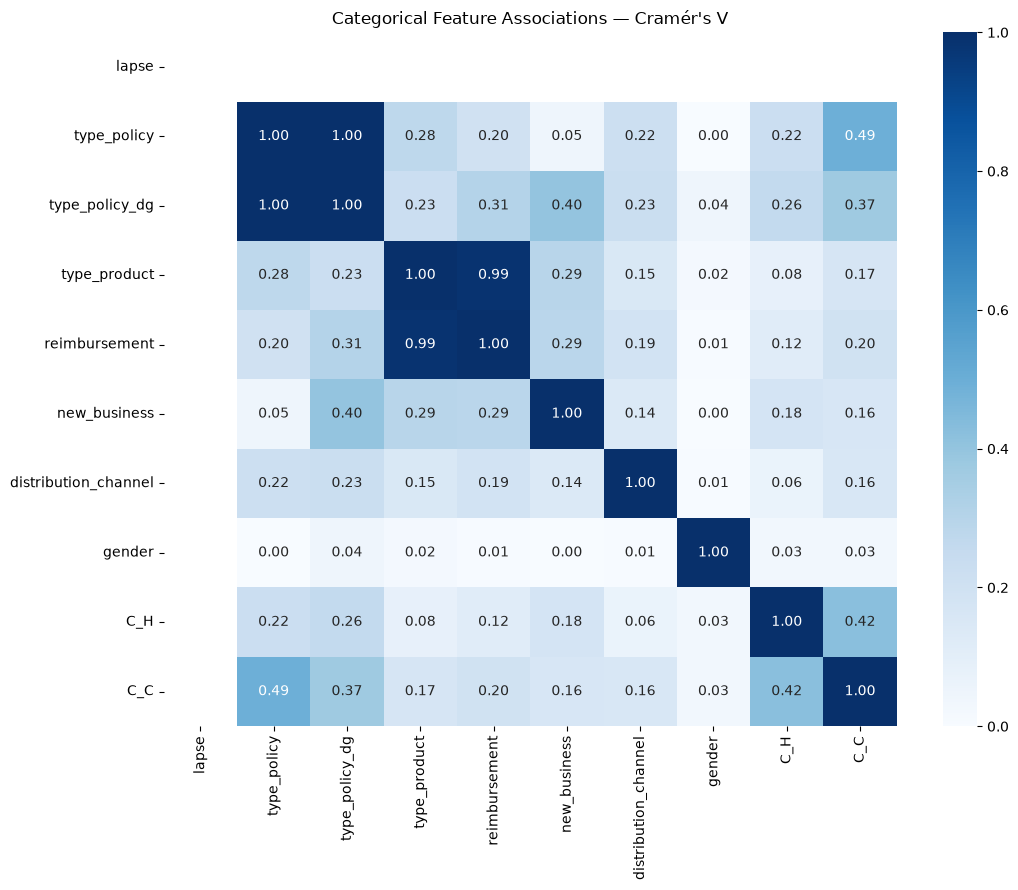

In [64]:

plt.figure(figsize=(11, 9))

sns.heatmap(
    association_matrix.astype(float),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Categorical Feature Associations — Cramér's V")
plt.tight_layout()
plt.show()


### 6.11 Categorical Distribution Summary

#### Consolidate category cardinality, dominant-category proportions, rare-category counts, and missingness to identify potential issues for subsequent preprocessing.

In [65]:

final_categorical_summary = categorical_summary.merge(
    rare_category_summary,
    on="Feature",
    how="left"
)

display(final_categorical_summary.round(2))


,Feature,Unique Categories,Most Frequent Category,Dominant Category %,Missing %,Total Categories,Rare Categories (<1%),Rows in Rare Categories
0,lapse,1,2,100.00,0.00,1,0,0
1,type_policy,2,I,60.67,0.00,2,0,0
2,type_policy_dg,6,I,47.38,0.00,6,0,0
3,type_product,4,S,77.38,0.00,4,0,0
4,reimbursement,2,No,82.45,0.00,2,0,0
5,new_business,2,No,88.85,0.00,2,0,0
6,distribution_channel,3,I,65.16,0.00,3,1,140
7,gender,2,F,54.63,0.00,2,0,0
8,C_H,6,H6,58.76,4.87,6,0,0
9,C_C,6,C3,46.31,4.67,6,0,0


### 7.1 Observation Period Distribution

#### Examine the number and percentage of observations in each year to understand the temporal coverage and balance of the renewal dataset.

In [66]:

period_summary = df["period"].value_counts().sort_index()

period_table = pd.DataFrame({
    "Count": period_summary,
    "Percentage": period_summary / len(df) * 100
})

display(period_table.round(2))


,Count,Percentage
period,,
2017,63467,51.47
2018,59831,48.53


### 7.2 Observation Period Visualization

#### Visualize the distribution of observations across years to identify differences in sample size between renewal periods.

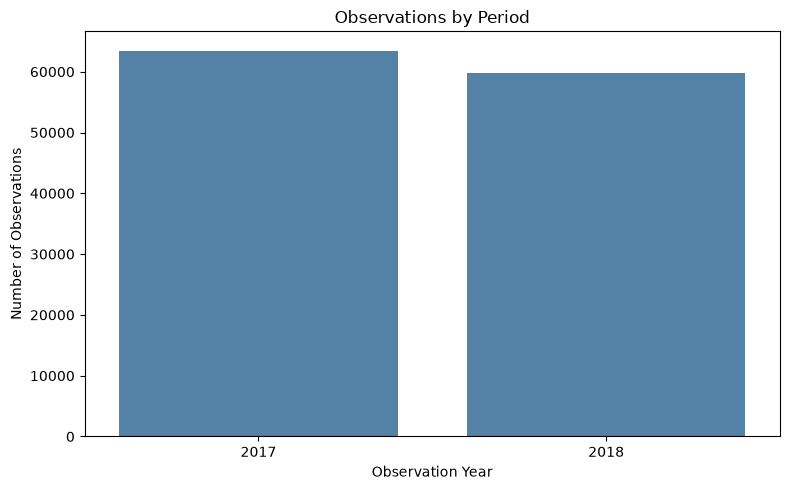

In [67]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="period",
    order=sorted(df["period"].dropna().unique()),
    color="steelblue"
)

plt.title("Observations by Period")
plt.xlabel("Observation Year")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()


### 7.3 Commencement Year Distributions

#### Examine when policies and insured-person relationships commenced to understand the historical composition of the renewal population.

In [68]:

commencement_cols = [
    "year_effect_policy",
    "year_effect_insured"
]

for col in commencement_cols:
    print(f"\n{col}")
    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("Count")
    )



year_effect_policy


,Count
year_effect_policy,
1932,2
1933,14
1934,22
1935,30
1936,14
...,...
2014,3969
2015,5370
2016,7334



year_effect_insured


,Count
year_effect_insured,
1933,4
1934,8
1935,10
1936,6
1937,12
...,...
2014,4200
2015,5835
2016,7907


### 7.4 Commencement Year Visualization

#### Visualize the distribution of commencement years to identify concentrations of newer and older insurance relationships.

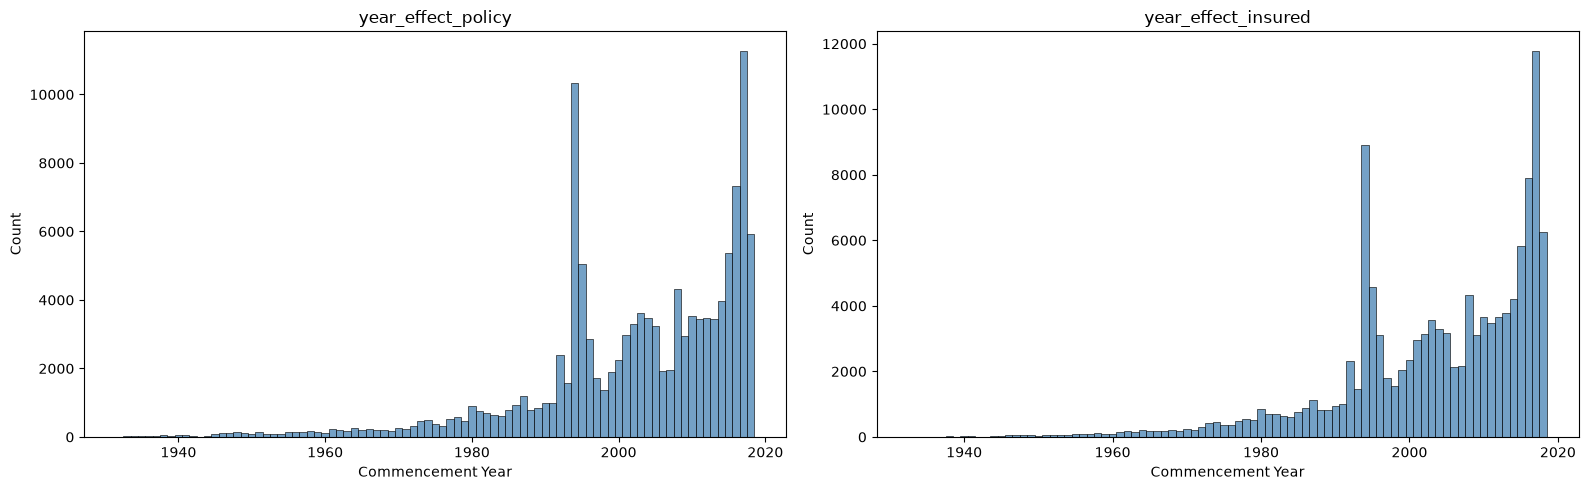

In [69]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, col in zip(axes, commencement_cols):
    sns.histplot(
        df[col].dropna(),
        discrete=True,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(col)
    ax.set_xlabel("Commencement Year")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()


### 7.5 Policy and Insured Seniority

#### Examine the distributions of policy and insured seniority to understand the length of insurance relationships and identify unusual values.

,count,mean,std,min,25%,50%,75%,max
seniority_policy,123298.0,15.15,14.12,0.0,3.0,13.0,23.0,86.0
seniority_insured,123298.0,14.15,13.15,0.0,3.0,12.0,23.0,85.0


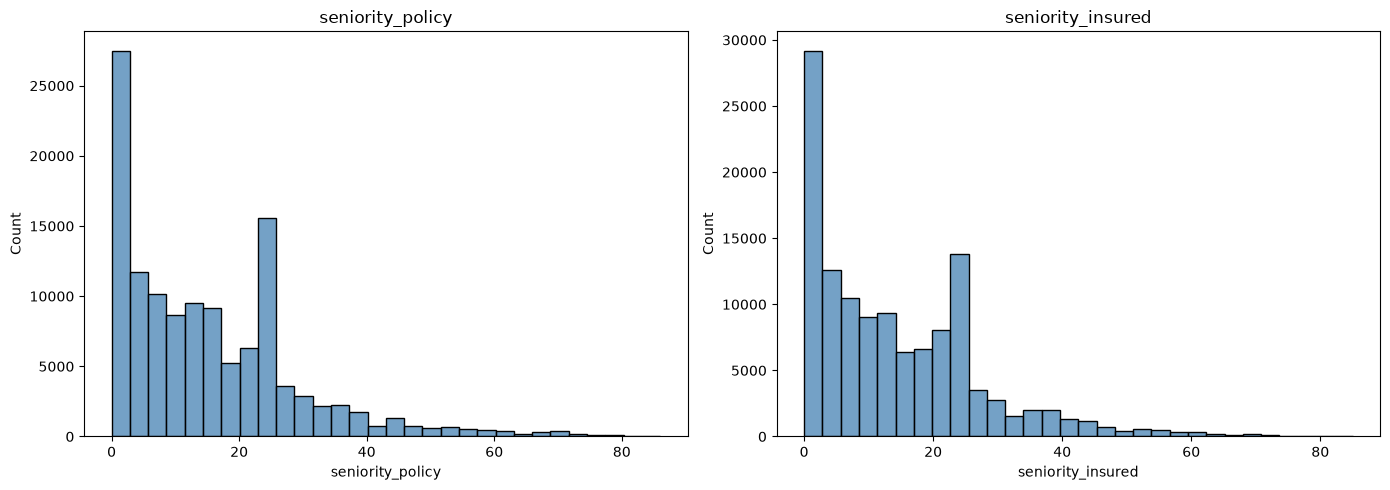

In [70]:

seniority_cols = [
    "seniority_policy",
    "seniority_insured"
]

display(
    df[seniority_cols]
    .describe()
    .T
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, seniority_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(col)

plt.tight_layout()
plt.show()


### 7.6 Seniority Consistency

#### Compare recorded seniority with the elapsed years since commencement to identify potential inconsistencies in the temporal attributes.

In [71]:

seniority_checks = {}

pairs = [
    ("seniority_policy", "year_effect_policy"),
    ("seniority_insured", "year_effect_insured")
]

for seniority_col, start_year_col in pairs:

    expected = (
        pd.to_numeric(df["period"], errors="coerce")
        - pd.to_numeric(df[start_year_col], errors="coerce")
    )

    observed = pd.to_numeric(
        df[seniority_col], errors="coerce"
    )

    valid = expected.notna() & observed.notna()

    difference = observed[valid] - expected[valid]

    seniority_checks[seniority_col] = {
        "Comparable Records": valid.sum(),
        "Exact Matches": (difference == 0).sum(),
        "Within One Year": (difference.abs() <= 1).sum(),
        "Beyond One Year": (difference.abs() > 1).sum()
    }

display(pd.DataFrame(seniority_checks).T)


,Comparable Records,Exact Matches,Within One Year,Beyond One Year
seniority_policy,123298,123298,123298,0
seniority_insured,123298,123298,123298,0


### 7.7 Repeated Identifiers Across Observation Years

#### Determine how many insured-policy identifiers appear in both observation periods to understand the longitudinal structure of the dataset.

In [72]:

id_period_counts = (
    df.groupby("ID")["period"]
    .nunique()
)

display(
    id_period_counts
    .value_counts()
    .sort_index()
    .rename_axis("Number of Observation Periods")
    .to_frame("Number of IDs")
)

print(
    "IDs observed in both years:",
    (id_period_counts == 2).sum()
)


,Number of IDs
Number of Observation Periods,
1,16178
2,53560


IDs observed in both years: 53560


### 7.8 Premium Distribution by Observation Year

#### Compare renewal premium distributions across 2017 and 2018 to identify differences in central tendency and variability.

In [73]:

premium_by_year = (
    df.groupby("period")["target_premium"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(premium_by_year.round(2))


,count,mean,median,std,min,max
period,,,,,,
2017,63467,900.74,813.96,563.19,34.34,13679.44
2018,59831,950.76,853.82,589.65,34.19,15307.59


### 7.9 Premium Distribution Comparison

#### Visualize renewal premium distributions across observation periods to assess changes in spread, central tendency, and extreme values.

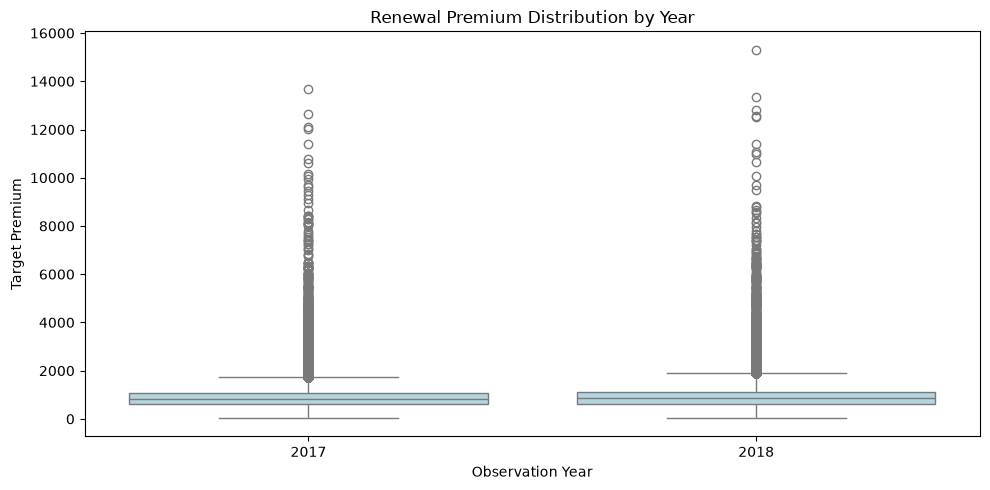

In [74]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="period",
    y="target_premium",
    color="lightblue"
)

plt.title("Renewal Premium Distribution by Year")
plt.xlabel("Observation Year")
plt.ylabel("Target Premium")

plt.tight_layout()
plt.show()


### 7.10 Previous and Target Premium Comparison

#### Compare previous and renewal premium values to understand premium adjustments between successive insurance periods.

In [75]:

premium_comparison = df[
    ["previous_premium", "target_premium"]
].describe().T

display(premium_comparison.round(2))

premium_change = (
    df["target_premium"] - df["previous_premium"]
)

print("\nPremium change summary:")
display(premium_change.describe().round(2))

print("Premium increased:", (premium_change > 0).sum())
print("Premium unchanged:", (premium_change == 0).sum())
print("Premium decreased:", (premium_change < 0).sum())


,count,mean,std,min,25%,50%,75%,max
previous_premium,123298.0,874.60,547.16,33.33,591.86,789.48,1027.17,15339.78
target_premium,123298.0,925.02,576.72,34.19,620.86,834.26,1092.82,15307.59



Premium change summary:


count    123298.00
mean         50.42
std          98.32
min       -4810.63
25%          14.59
50%          37.33
75%          69.13
max        4086.79
dtype: float64

Premium increased: 105304
Premium unchanged: 1832
Premium decreased: 16162


### 7.11 Relative Premium Changes

#### Calculate percentage changes between previous and target premiums to examine the magnitude and direction of renewal premium adjustments.

In [76]:

valid_previous = df["previous_premium"] > 0

premium_change_pct = (
    (
        df.loc[valid_previous, "target_premium"]
        - df.loc[valid_previous, "previous_premium"]
    )
    / df.loc[valid_previous, "previous_premium"]
) * 100

display(premium_change_pct.describe().round(2))

print(
    "Excluded zero/nonpositive previous premiums:",
    (~valid_previous).sum()
)


count    123298.00
mean          5.61
std           8.63
min         -73.05
25%           2.16
50%           4.49
75%           7.95
max         366.15
dtype: float64

Excluded zero/nonpositive previous premiums: 0


### 7.12 Premium Changes Across Observation Years

#### Compare premium adjustment distributions between 2017 and 2018 to identify differences in renewal pricing patterns.

In [77]:

premium_changes_by_year = df[
    ["period", "previous_premium", "target_premium"]
].copy()

premium_changes_by_year["premium_change"] = (
    premium_changes_by_year["target_premium"]
    - premium_changes_by_year["previous_premium"]
)

display(
    premium_changes_by_year
    .groupby("period")["premium_change"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)


,count,mean,median,std
period,,,,
2017,63467,44.37,33.66,91.48
2018,59831,56.83,41.86,104.71


### 7.13 Temporal Data Leakage Assessment

#### Identify attributes whose values may only become available after premium determination, requiring verification before inclusion in predictive modeling.

In [78]:

leakage_review = pd.DataFrame({
    "Feature": [
        "previous_premium",
        "cost_claims_year",
        "n_medical_services",
        "date_lapse_policy",
        "date_lapse_insured",
        "year_lapse_policy",
        "year_lapse_insured",
        "exposure_time",
        "lapse",
        "age_difference"
    ],
    "Review Question": [
        "Is this premium from the preceding policy period?",
        "Are these claim costs known before renewal?",
        "Are these medical services from the prior period?",
        "Was this termination date known at pricing?",
        "Was this termination date known at pricing?",
        "Was this termination year known at pricing?",
        "Was this termination year known at pricing?",
        "Is exposure calculated using future information?",
        "Does lapse represent an outcome after pricing?",
        "How was this difference constructed?"
    ]
})

display(leakage_review)


,Feature,Review Question
0,previous_premium,Is this premium from the preceding policy period?
1,cost_claims_year,Are these claim costs known before renewal?
2,n_medical_services,Are these medical services from the prior period?
3,date_lapse_policy,Was this termination date known at pricing?
4,date_lapse_insured,Was this termination date known at pricing?
5,year_lapse_policy,Was this termination year known at pricing?
6,year_lapse_insured,Was this termination year known at pricing?
7,exposure_time,Is exposure calculated using future information?
8,lapse,Does lapse represent an outcome after pricing?
9,age_difference,How was this difference constructed?


### 7.14 Temporal Analysis Summary

#### Consolidate temporal coverage, identifier recurrence, seniority consistency, and premium changes to assess the longitudinal structure and modeling suitability of the renewal dataset.

In [79]:

temporal_summary = pd.DataFrame({
    "Metric": [
        "Observation periods",
        "Unique IDs",
        "IDs observed in both years",
        "Mean previous premium",
        "Mean target premium",
        "Mean premium change",
        "Policy seniority discrepancies (>1 year)",
        "Insured seniority discrepancies (>1 year)"
    ],
    "Value": [
        df["period"].nunique(),
        df["ID"].nunique(),
        (id_period_counts == 2).sum(),
        round(df["previous_premium"].mean(), 2),
        round(df["target_premium"].mean(), 2),
        round(premium_change.mean(), 2),
        seniority_checks["seniority_policy"]["Beyond One Year"],
        seniority_checks["seniority_insured"]["Beyond One Year"]
    ]
})

display(temporal_summary)


,Metric,Value
0,Observation periods,2.00
1,Unique IDs,69738.00
2,IDs observed in both years,53560.00
3,Mean previous premium,874.60
4,Mean target premium,925.02
5,Mean premium change,50.42
6,Policy seniority discrepancies (>1 year),0.00
7,Insured seniority discrepancies (>1 year),0.00


#### Policy and insured seniority are temporally consistent across all 123,298 observations, with no discrepancies between recorded seniority and elapsed years since commencement. These attributes are therefore consistent with their corresponding commencement-year variables.

### Part 7 — Temporal Analysis: Key Findings

#### The renewal dataset demonstrates complete consistency between seniority and commencement-year attributes. A substantial proportion of identifiers (76.80%) appear in both observation periods, supporting longitudinal analysis. Premium increases dominate the observations (85.41%), with an average absolute increase of 50.42 and an average relative increase of 5.61%. Extreme premium adjustments warrant further investigation. Temporal alignment of previous and target premiums must be verified before predictive modeling.

### 8.1 Target Variable Descriptive Statistics

#### Examine the central tendency, dispersion, and range of the renewal premium to understand the scale and variability of the prediction target.

In [80]:

target = "target_premium"

target_summary = df[target].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

display(target_summary.to_frame("Value").round(2))

print("Missing target values:", df[target].isna().sum())
print("Unique target values:", df[target].nunique())


,Value
count,123298.00
mean,925.02
std,576.72
min,34.19
1%,94.94
5%,295.80
25%,620.86
50%,834.26
75%,1092.82
95%,1867.83


Missing target values: 0
Unique target values: 37371


### 8.2 Target Premium Distribution

#### Visualize the distribution of renewal premiums to identify concentration, asymmetry, and the presence of long tails.

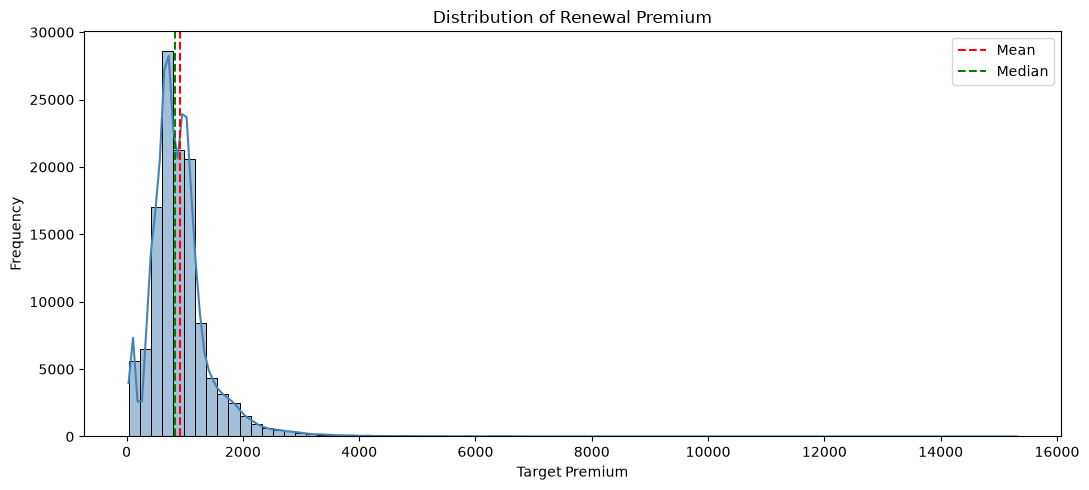

In [81]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=df,
    x=target,
    bins=80,
    kde=True,
    color="steelblue"
)

plt.axvline(
    df[target].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    df[target].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.title("Distribution of Renewal Premium")
plt.xlabel("Target Premium")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


### 8.3 Central Premium Distribution

#### Examine the central 98% of target premiums to better understand the distribution of typical observations without allowing extreme values to dominate the visualization.

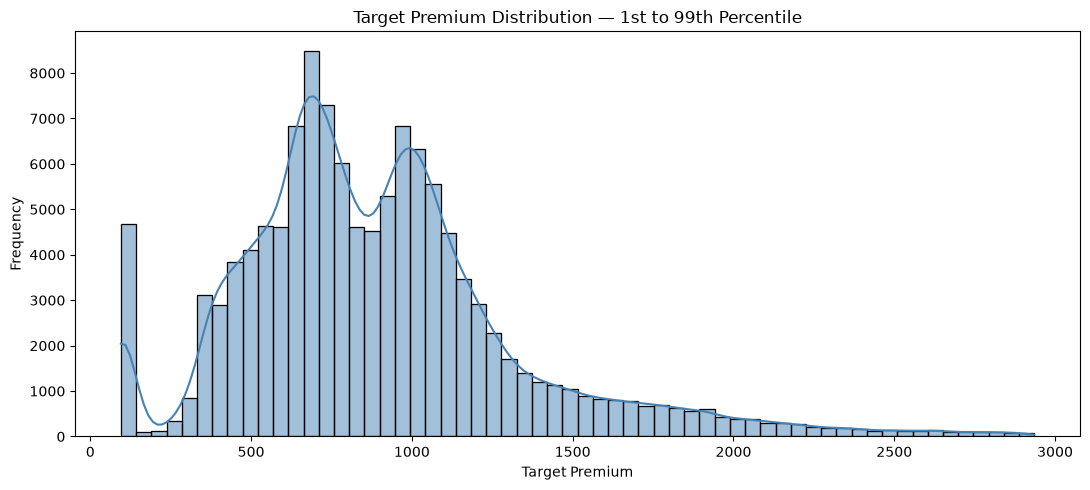

In [82]:

lower = df[target].quantile(0.01)
upper = df[target].quantile(0.99)

central_target = df.loc[
    df[target].between(lower, upper),
    target
]

plt.figure(figsize=(11, 5))

sns.histplot(
    central_target,
    bins=60,
    kde=True,
    color="steelblue"
)

plt.title("Target Premium Distribution — 1st to 99th Percentile")
plt.xlabel("Target Premium")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### 8.4 Target Premium Boxplot

#### Examine the spread and potential extreme values of the renewal premium using the interquartile range and boxplot whiskers.

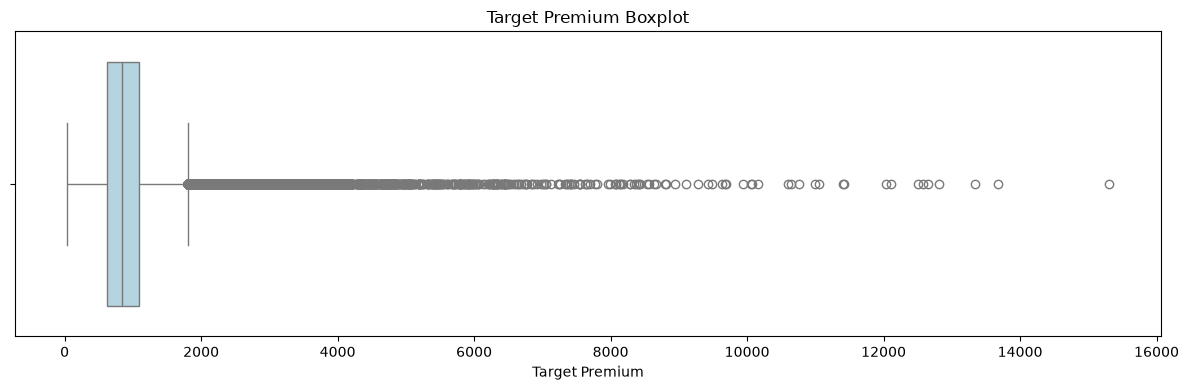

In [83]:

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=df[target],
    color="lightblue"
)

plt.title("Target Premium Boxplot")
plt.xlabel("Target Premium")
plt.tight_layout()
plt.show()


### 8.5 Target Distribution Shape

#### Calculate skewness and excess kurtosis to assess asymmetry and tail heaviness in the renewal premium distribution.

In [84]:

target_skewness = df[target].skew()
target_kurtosis = df[target].kurt()

print("Skewness:", round(target_skewness, 4))
print("Excess kurtosis:", round(target_kurtosis, 4))

print("Mean:", round(df[target].mean(), 2))
print("Median:", round(df[target].median(), 2))


Skewness: 4.1016
Excess kurtosis: 43.7018
Mean: 925.02
Median: 834.26


### 8.6 Target Premium Quantile Analysis

#### Examine premium thresholds across the distribution to understand the concentration of low, medium, and high premium values.

In [85]:

quantiles = df[target].quantile([
    0.01, 0.05, 0.10, 0.25,
    0.50, 0.75, 0.90, 0.95, 0.99
])

quantile_table = pd.DataFrame({
    "Percentile": [
        "1%", "5%", "10%", "25%",
        "50%", "75%", "90%", "95%", "99%"
    ],
    "Premium": quantiles.values
})

display(quantile_table.round(2))


,Percentile,Premium
0,1%,94.94
1,5%,295.80
2,10%,418.20
3,25%,620.86
4,50%,834.26
5,75%,1092.82
6,90%,1488.74
7,95%,1867.83
8,99%,2935.58


### 8.7 Target Premium Outlier Screening

#### Identify observations outside the conventional 1.5×IQR boundaries to estimate the prevalence of statistically extreme premiums.

In [86]:

Q1 = df[target].quantile(0.25)
Q3 = df[target].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

target_outliers = (
    (df[target] < lower_bound)
    | (df[target] > upper_bound)
)

print("Lower IQR bound:", round(lower_bound, 2))
print("Upper IQR bound:", round(upper_bound, 2))
print("Potential outliers:", target_outliers.sum())

print(
    "Outlier percentage:",
    round(target_outliers.mean() * 100, 2)
)


Lower IQR bound: -87.07
Upper IQR bound: 1800.75
Potential outliers: 7053
Outlier percentage: 5.72


### 8.8 Target Premium by Observation Year

#### Compare renewal premium distributions between 2017 and 2018 to assess changes in target scale and variability across periods.

,count,mean,median,std,min,max
period,,,,,,
2017,63467,900.74,813.96,563.19,34.34,13679.44
2018,59831,950.76,853.82,589.65,34.19,15307.59


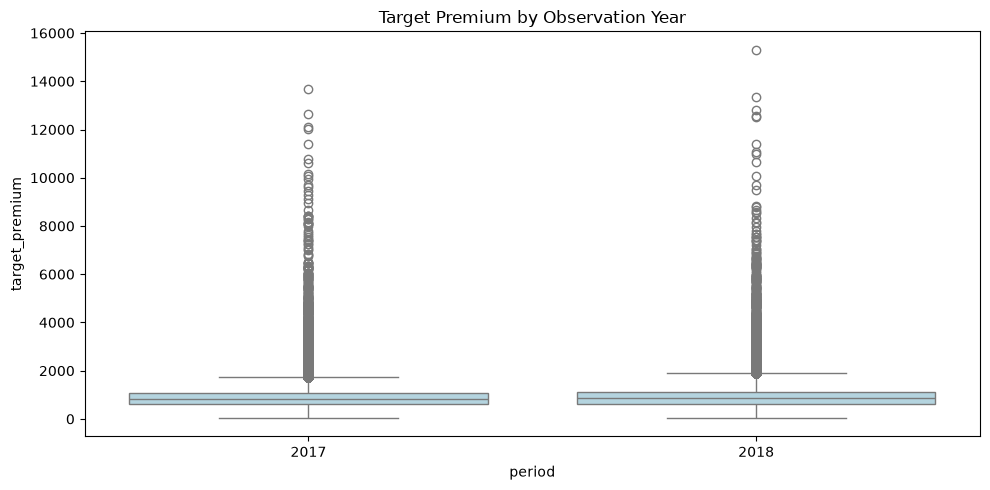

In [87]:

target_by_year = (
    df.groupby("period")[target]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(target_by_year.round(2))

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="period",
    y=target,
    color="lightblue"
)

plt.title("Target Premium by Observation Year")
plt.tight_layout()
plt.show()


### 8.9 Previous Premium and Target Premium Relationship

#### Examine the association between previous and renewal premiums to understand whether historical pricing information may help predict the new premium.

,previous_premium,target_premium
previous_premium,1.0000,0.9861
target_premium,0.9861,1.0000


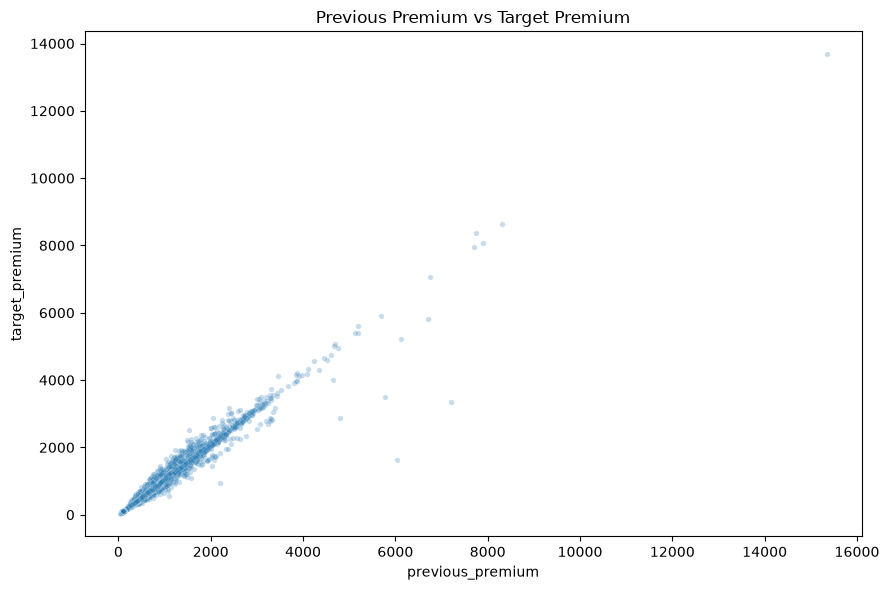

In [88]:

premium_corr = df[
    ["previous_premium", "target_premium"]
].corr(method="pearson")

display(premium_corr.round(4))

sample_df = df[
    ["previous_premium", "target_premium"]
].sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_df,
    x="previous_premium",
    y="target_premium",
    alpha=0.25,
    s=15
)

plt.title("Previous Premium vs Target Premium")
plt.tight_layout()
plt.show()


### 8.10 Premium Change Distribution

#### Analyze the difference between target and previous premiums to understand the magnitude, direction, and variability of renewal adjustments.

count    123298.00
mean         50.42
std          98.32
min       -4810.63
25%          14.59
50%          37.33
75%          69.13
max        4086.79
dtype: float64

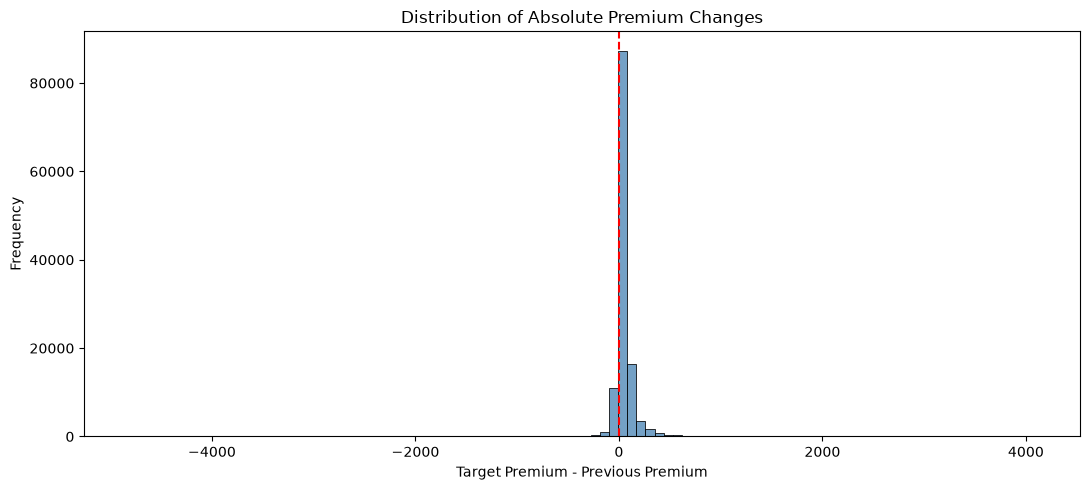

In [89]:

premium_change = (
    df["target_premium"] - df["previous_premium"]
)

display(premium_change.describe().round(2))

plt.figure(figsize=(11, 5))

sns.histplot(
    premium_change,
    bins=100,
    color="steelblue"
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Absolute Premium Changes")
plt.xlabel("Target Premium - Previous Premium")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### 8.11 Relative Premium Change Distribution

#### Examine percentage premium adjustments to identify whether unusually large changes occur relative to the previous premium.

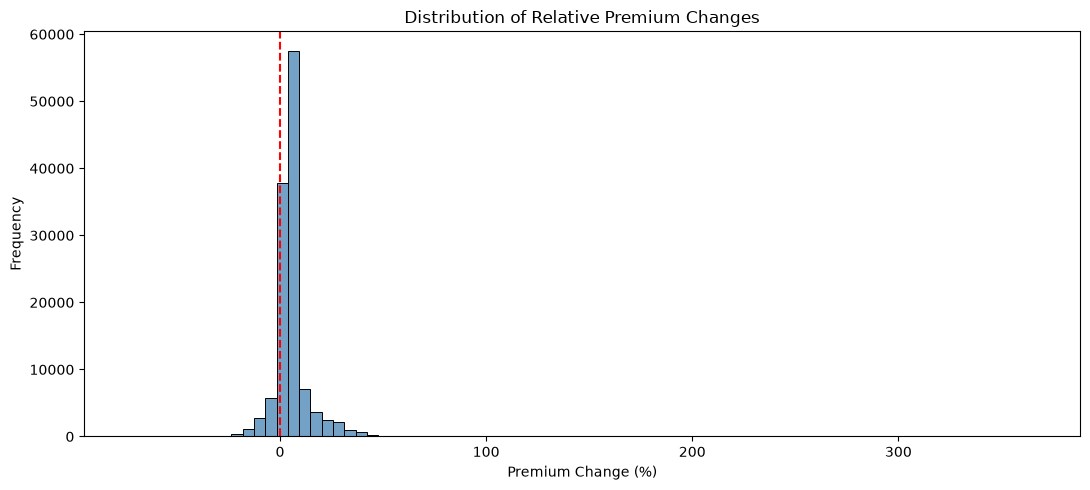

In [90]:

valid_previous = df["previous_premium"] > 0

relative_change = (
    (
        df.loc[valid_previous, "target_premium"]
        - df.loc[valid_previous, "previous_premium"]
    )
    / df.loc[valid_previous, "previous_premium"]
) * 100

plt.figure(figsize=(11, 5))

sns.histplot(
    relative_change,
    bins=80,
    color="steelblue"
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Relative Premium Changes")
plt.xlabel("Premium Change (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### 8.12 Historical Premium Reference Baseline

#### Evaluate the prediction error obtained by using the previous premium as an estimate of the renewal premium, establishing a preliminary reference for future regression models.

In [91]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_true = df["target_premium"]
y_pred = df["previous_premium"]

baseline_mae = mean_absolute_error(y_true, y_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)
baseline_r2 = r2_score(y_true, y_pred)

print("Historical premium baseline")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R²:", round(baseline_r2, 4))


Historical premium baseline
MAE: 62.48
RMSE: 110.49
R²: 0.9633


### 8.13 Target Variable Analysis Summary

#### Consolidate the target distribution, skewness, outlier prevalence, premium adjustments, and historical-premium reference errors to guide regression modeling and evaluation.

In [92]:

target_analysis_summary = pd.DataFrame({
    "Metric": [
        "Mean target premium",
        "Median target premium",
        "Target standard deviation",
        "Target skewness",
        "Target excess kurtosis",
        "IQR outlier percentage",
        "Mean premium change",
        "Historical baseline MAE",
        "Historical baseline RMSE",
        "Historical baseline R²"
    ],
    "Value": [
        df[target].mean(),
        df[target].median(),
        df[target].std(),
        target_skewness,
        target_kurtosis,
        target_outliers.mean() * 100,
        premium_change.mean(),
        baseline_mae,
        baseline_rmse,
        baseline_r2
    ]
})

display(target_analysis_summary.round(3))


,Metric,Value
0,Mean target premium,925.016
1,Median target premium,834.260
2,Target standard deviation,576.722
3,Target skewness,4.102
4,Target excess kurtosis,43.702
5,IQR outlier percentage,5.720
6,Mean premium change,50.419
7,Historical baseline MAE,62.481
8,Historical baseline RMSE,110.494
9,Historical baseline R²,0.963


### 9.1 Numerical Features for Outlier Analysis

#### Identify numerical predictors and the target variable for outlier screening. Identifier, categorical, and calendar-year variables are excluded because their numerical representations do not necessarily indicate meaningful magnitudes.

In [93]:
outlier_features = [
    col for col in num_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

target = "target_premium"

print("Numerical predictors:", len(outlier_features))
print(outlier_features)
print("Target:", target)


Numerical predictors: 21
['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'previous_premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'age_difference']
Target: target_premium


### 9.2 Numerical Range Inspection

#### Examine minimum, maximum, and selected percentiles to identify unusual values and assess whether feature ranges are consistent with their intended meanings.

In [94]:

range_summary = df[
    outlier_features + [target]
].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
).T

display(
    range_summary[
        ["min", "1%", "5%", "50%", "95%", "99%", "max"]
    ].round(2)
)


,min,1%,5%,50%,95%,99%,max
exposure_time,0.00,0.00,1.00,1.00,1.00,1.00,1.00
seniority_insured,0.00,0.00,0.00,12.00,39.00,58.00,85.00
seniority_policy,0.00,0.00,0.00,13.00,42.00,65.00,86.00
age,0.00,1.00,5.00,48.00,81.00,88.00,99.00
previous_premium,33.33,94.94,278.46,789.48,1751.34,2795.85,15339.78
cost_claims_year,0.00,0.00,0.00,228.26,2486.64,6848.54,78035.10
n_medical_services,0.00,0.00,0.00,7.00,64.00,114.00,1029.00
n_insured_pc,1.00,2.00,6.00,120.00,1009.00,2518.00,2518.00
n_insured_mun,1.00,2.00,11.00,1234.00,19315.00,19315.00,19315.00
n_insured_prov,4.00,121.00,380.00,7467.00,29465.00,29465.00,29465.00


### 9.3 Numerical Feature Boxplots

#### Visualize the spread and potential extreme values of numerical attributes. Boxplots are examined separately because the variables have different measurement scales.

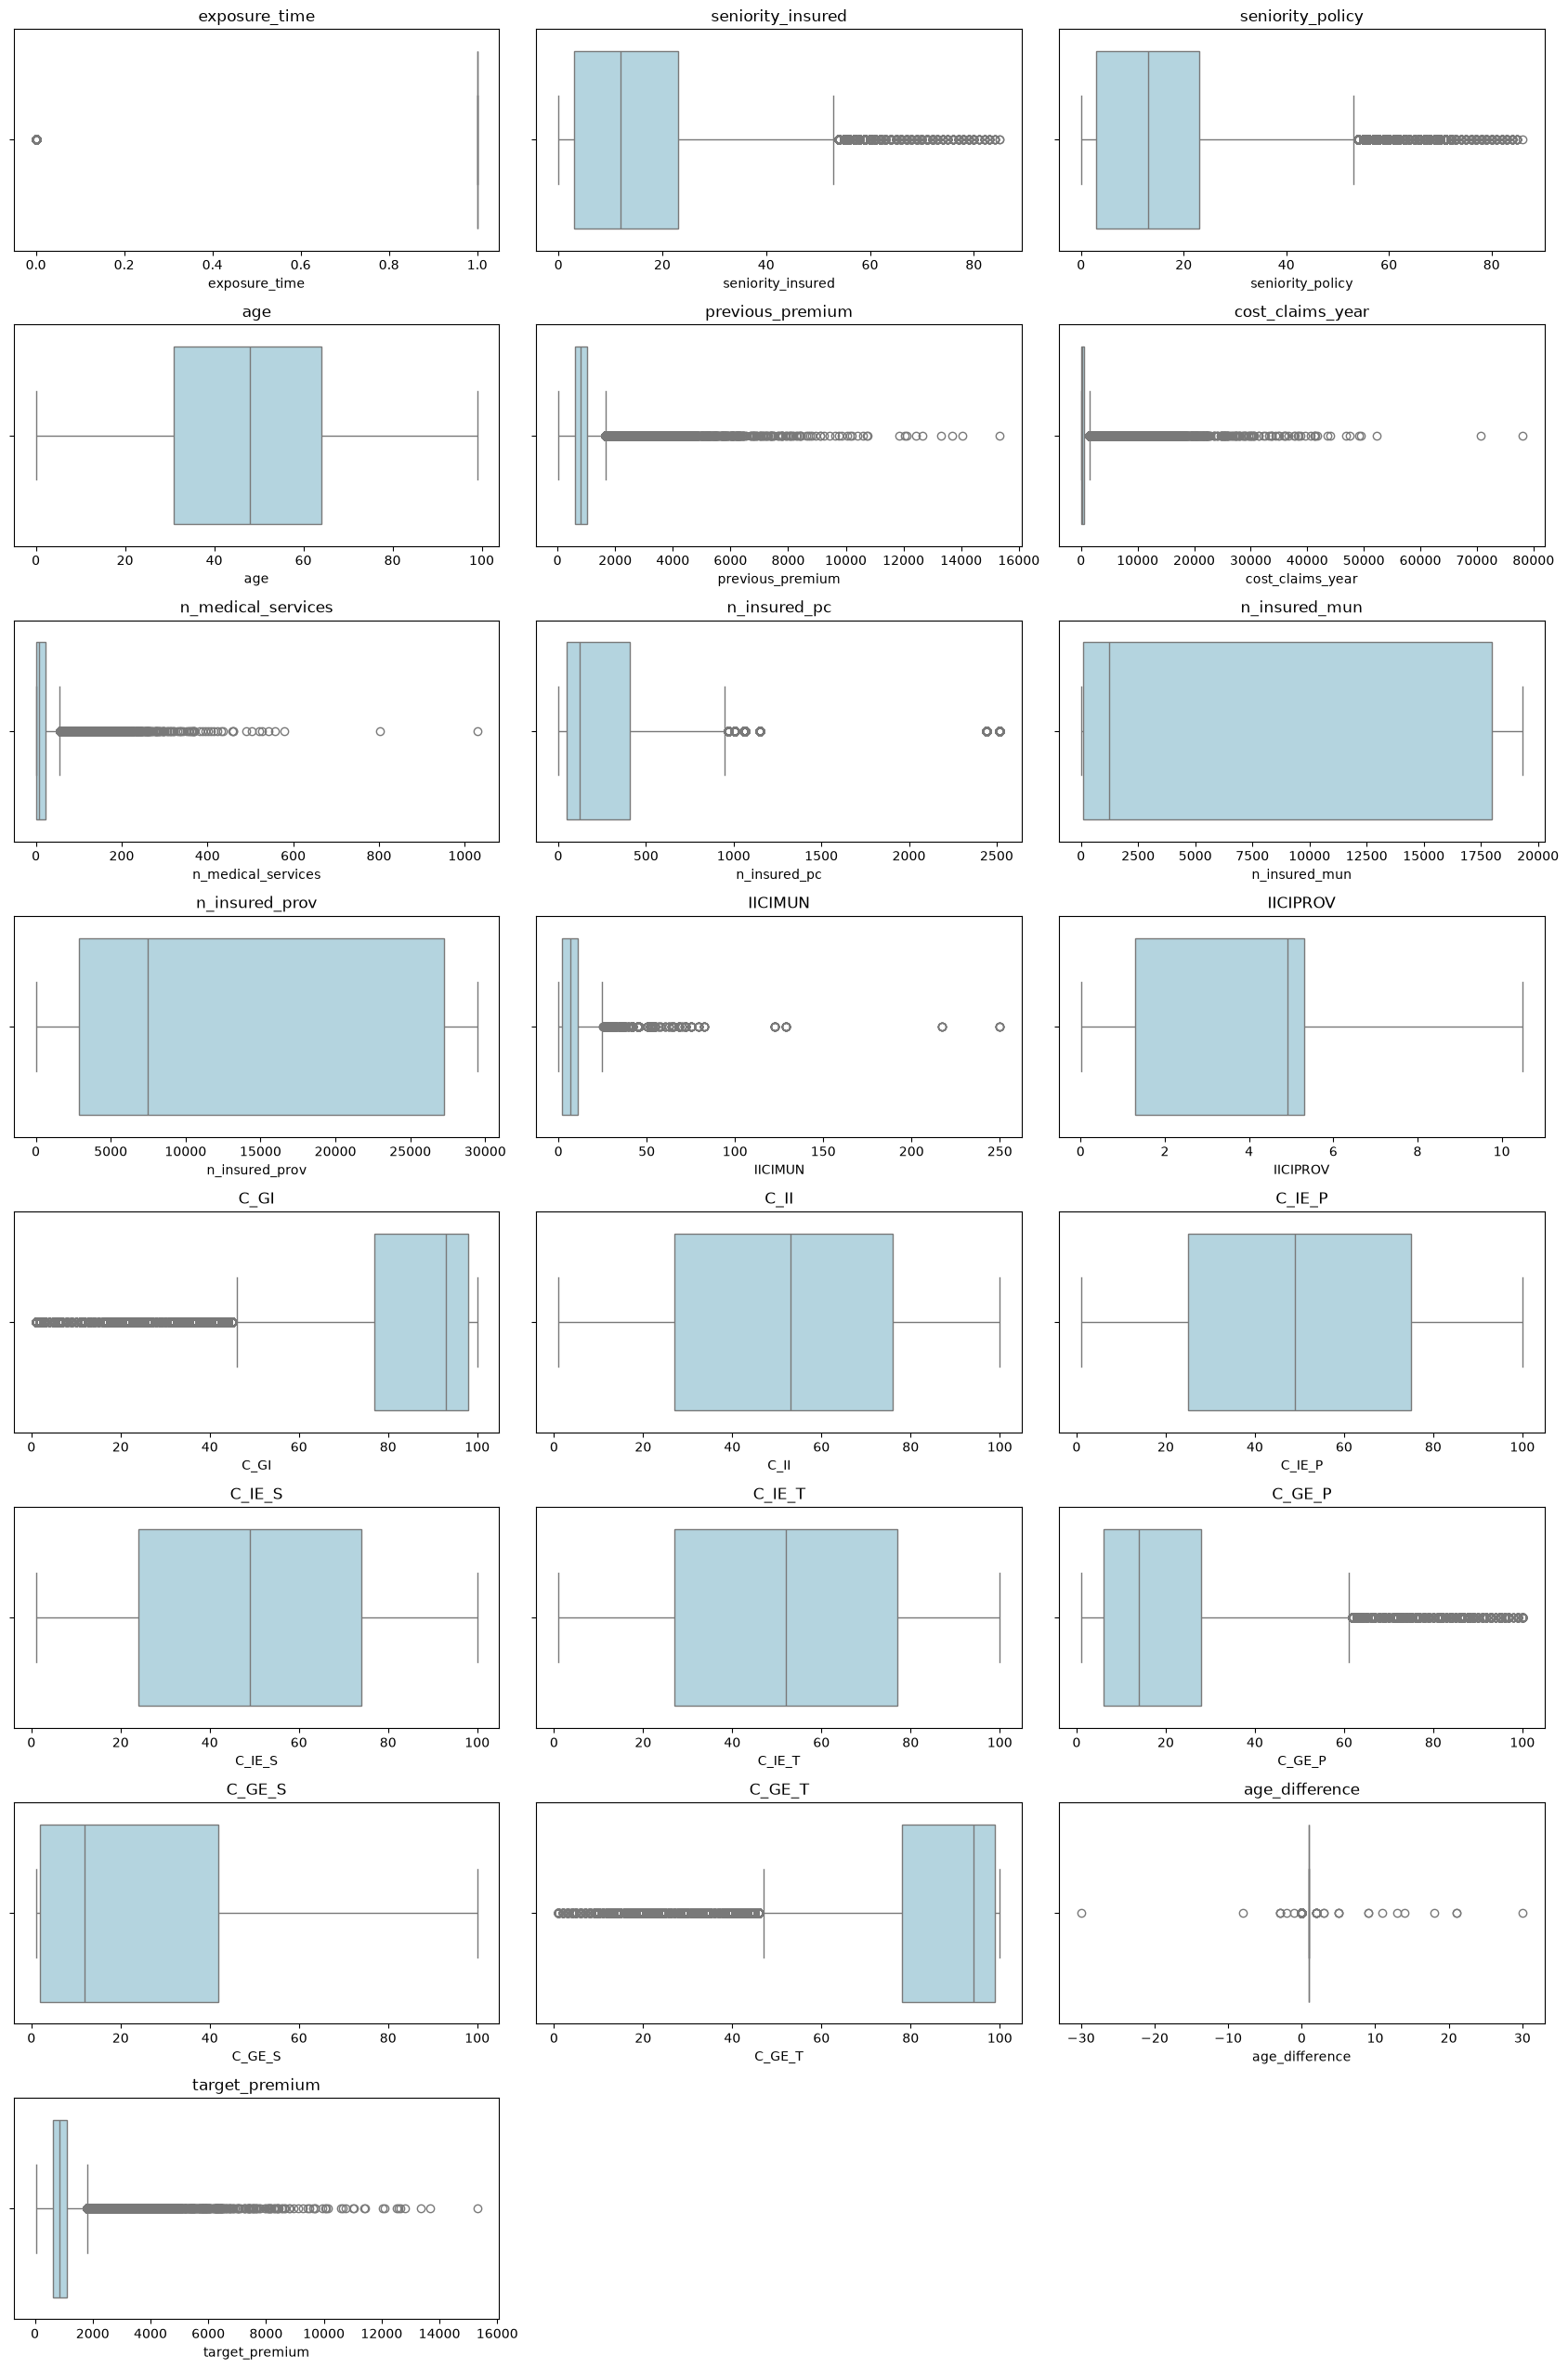

In [95]:

features_to_plot = outlier_features + [target]

n_cols = 3
n_rows = int(np.ceil(len(features_to_plot) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(17, n_rows * 3.2)
)

axes = np.array(axes).flatten()

for i, col in enumerate(features_to_plot):
    sns.boxplot(
        x=df[col],
        ax=axes[i],
        color="lightblue"
    )
    axes[i].set_title(col)

for j in range(len(features_to_plot), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 9.4 Interquartile Range Outlier Detection

#### Apply the 1.5×IQR rule to identify observations outside the conventional lower and upper fences. These observations are statistical outlier candidates rather than confirmed data errors.

In [96]:

iqr_results = []
iqr_masks = {}

for col in features_to_plot:
    s = df[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = df[col].notna() & (
        (df[col] < lower) | (df[col] > upper)
    )

    iqr_masks[col] = mask

    iqr_results.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": mask.sum(),
        "Outlier %": mask.sum() / len(s) * 100
    })

iqr_summary = pd.DataFrame(iqr_results)

display(
    iqr_summary.sort_values(
        "Outlier %", ascending=False
    ).round(2)
)


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
12,C_GI,45.50,129.50,11653,10.06
5,cost_claims_year,-817.53,1455.03,11728,9.51
6,n_medical_services,-32.00,56.00,8100,6.57
7,n_insured_pc,-500.00,956.00,7693,6.24
4,previous_premium,-61.11,1680.14,7276,5.90
21,target_premium,-87.07,1800.75,7053,5.72
19,C_GE_T,46.50,130.50,6624,5.72
20,age_difference,1.00,1.00,4197,3.40
17,C_GE_P,-27.00,61.00,3496,3.02
2,seniority_policy,-27.00,53.00,3014,2.44


### 9.5 Outlier Prevalence Across Features

#### Compare the percentage of IQR-flagged observations across numerical features to identify variables with substantial tail behavior.

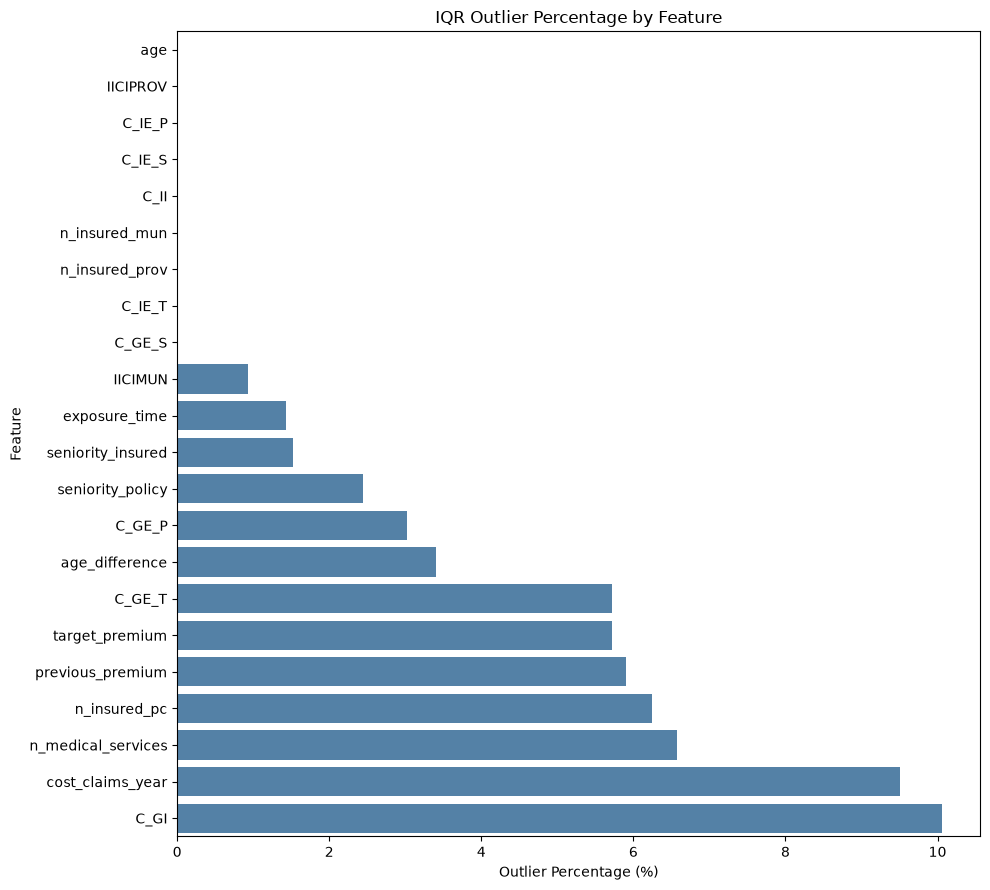

In [97]:

plot_data = iqr_summary.sort_values(
    "Outlier %", ascending=True
)

plt.figure(figsize=(10, 9))

sns.barplot(
    data=plot_data,
    x="Outlier %",
    y="Feature",
    color="steelblue"
)

plt.title("IQR Outlier Percentage by Feature")
plt.xlabel("Outlier Percentage (%)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### 9.6 Z-Score Outlier Screening

#### Identify observations more than three standard deviations from the mean. Compare these results with IQR screening, recognizing that Z-scores are sensitive to skewness and extreme values.

In [98]:

zscore_results = []

for col in features_to_plot:
    s = df[col]

    std = s.std()

    if pd.isna(std) or std == 0:
        continue

    z = (s - s.mean()) / std

    count = (z.abs() > 3).sum()

    zscore_results.append({
        "Feature": col,
        "Z-Score Outliers": count,
        "Outlier %": count / s.notna().sum() * 100
    })

zscore_summary = pd.DataFrame(zscore_results)

display(
    zscore_summary.sort_values(
        "Outlier %", ascending=False
    ).round(2)
)


,Feature,Z-Score Outliers,Outlier %
20,age_difference,4197,3.40
12,C_GI,3355,2.90
19,C_GE_T,2923,2.52
7,n_insured_pc,2991,2.43
17,C_GE_P,2349,2.03
2,seniority_policy,2237,1.81
6,n_medical_services,2194,1.78
1,seniority_insured,1873,1.52
4,previous_premium,1795,1.46
21,target_premium,1770,1.44


### 9.7 Comparison of Statistical Outlier Methods

#### Compare IQR and Z-score detection results to understand how outlier prevalence changes with the screening method.

In [99]:

outlier_comparison = iqr_summary[
    ["Feature", "Outlier %"]
].merge(
    zscore_summary[["Feature", "Outlier %"]],
    on="Feature",
    how="left",
    suffixes=("_IQR", "_ZScore")
)

display(
    outlier_comparison.sort_values(
        "Outlier %_IQR",
        ascending=False
    ).round(2)
)


,Feature,Outlier %_IQR,Outlier %_ZScore
12,C_GI,10.06,2.90
5,cost_claims_year,9.51,1.40
6,n_medical_services,6.57,1.78
7,n_insured_pc,6.24,2.43
4,previous_premium,5.90,1.46
21,target_premium,5.72,1.44
19,C_GE_T,5.72,2.52
20,age_difference,3.40,3.40
17,C_GE_P,3.02,2.03
2,seniority_policy,2.44,1.81


### 9.8 Age and Age-Difference Anomalies

#### Inspect extreme ages and unusual age differences to distinguish possible data inconsistencies from valid insurance records.

In [100]:

print("Age summary:")
display(df["age"].describe())

print("\nAge difference frequencies:")
display(
    df["age_difference"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRecords with age_difference outside 0 or 1:")

age_anomalies = df.loc[
    ~df["age_difference"].isin([0, 1]),
    [
        "ID", "period", "age",
        "age_difference",
        "year_effect_insured",
        "seniority_insured"
    ]
]

display(age_anomalies.head(30))
print("Count:", len(age_anomalies))


Age summary:


count    123298.000000
mean         46.387354
std          23.013324
min           0.000000
25%          31.000000
50%          48.000000
75%          64.000000
max          99.000000
Name: age, dtype: float64


Age difference frequencies:


age_difference
-30         1
-8          1
-3          3
-2          1
-1          1
 0       4168
 1     119101
 2          8
 3          2
 5          3
 9          2
 11         1
 13         1
 14         1
 18         1
 21         2
 30         1
Name: count, dtype: int64


Records with age_difference outside 0 or 1:


,ID,period,age,age_difference,year_effect_insured,seniority_insured
5284,11371_1,2017,45,2,2007,10
7685,11984_1,2018,46,14,2003,15
7687,11984_2,2018,47,21,2003,15
10326,125_2,2017,55,13,1993,24
14278,1372_1,2018,84,2,1995,23
15853,14137_2,2018,67,2,1994,24
22334,16022_1,2017,82,-8,1979,38
29117,177_2,2018,71,-3,1994,24
33369,1897_2,2017,61,18,1995,22
39830,20951_2,2018,74,-30,2004,14


Count: 29


### 9.9 Claims and Medical-Service Extremes

#### Inspect extreme claims costs and medical-service counts to identify unusually high utilization records and determine whether they require further domain validation.

In [101]:

claims_features = [
    "cost_claims_year",
    "n_medical_services"
]

for col in claims_features:
    print(f"\n{col}")

    display(
        df[col].describe(
            percentiles=[0.90, 0.95, 0.99, 0.999]
        ).round(2)
    )

    display(
        df.nlargest(
            10, col
        )[
            ["ID", "period", col, target]
        ]
    )



cost_claims_year


count    123298.00
mean        633.66
std        1639.92
min           0.00
90%        1392.79
95%        2486.64
99%        6848.54
99.9%     20638.59
max       78035.10
Name: cost_claims_year, dtype: float64

,ID,period,cost_claims_year,target_premium
108558,5957_1,2018,78035.10,2169.1014
73690,30842_1,2018,70678.79,1523.8577
82142,32778_3,2018,52271.94,901.5967
102937,4557_1,2017,49509.19,767.6000
62273,28209_1,2018,49181.34,2159.3194
4087,1109_1,2017,47477.94,6748.8200
103772,4779_1,2018,46814.51,4087.0686
101044,4095_1,2017,44124.88,1913.9500
74782,3115_2,2017,43566.35,3337.4400
82029,32748_3,2018,41728.20,1921.3937



n_medical_services


count    123298.00
mean         16.67
std          25.85
min           0.00
90%          46.00
95%          64.00
99%         114.00
99.9%       227.00
max        1029.00
Name: n_medical_services, dtype: float64

,ID,period,n_medical_services,target_premium
74193,30975_2,2017,1029,2178.720000
62273,28209_1,2018,802,2159.319400
102596,4484_1,2017,579,2309.870000
61486,27927_1,2017,557,1753.380000
105912,530_2,2018,543,6506.145857
108532,5948_1,2017,527,2047.270000
122824,9889_2,2017,521,1372.590000
75388,31306_193,2017,504,549.780000
927,10247_2,2017,490,953.700000
83549,331_1,2017,461,2762.350000


### 9.10 Extreme Premium Observations

#### Inspect the highest and lowest renewal premiums alongside previous premiums to identify unusual pricing patterns and possible inconsistencies.

In [102]:

premium_columns = [
    "ID",
    "period",
    "previous_premium",
    "target_premium",
    "type_policy",
    "age"
]

print("Highest target premiums:")
display(
    df.nlargest(15, target)[premium_columns]
)

print("\nLowest target premiums:")
display(
    df.nsmallest(15, target)[premium_columns]
)


Highest target premiums:


,ID,period,previous_premium,target_premium,type_policy,age
24365,1654_1,2018,13679.44,15307.58880,I,80
24364,1654_1,2017,15339.78,13679.44000,I,79
7008,11799_7,2018,12647.22,13341.04960,I,58
23371,162_2,2018,12101.82,12816.01383,I,80
7007,11799_7,2017,12429.72,12647.22000,I,57
108864,603_2,2018,12040.21,12574.58080,I,78
18896,15014_4,2018,8420.10,12506.89060,C,49
23370,162_2,2017,11865.66,12101.82000,I,79
108863,603_2,2017,14027.89,12040.21000,I,77
70461,3001_1,2018,10765.59,11413.63146,I,73



Lowest target premiums:


,ID,period,previous_premium,target_premium,type_policy,age
93358,35902_2,2018,34.68,34.190400,I,31
62925,28340_1,2017,33.66,34.340000,I,30
62889,28332_28,2017,33.66,34.680000,I,30
62948,28349_1,2017,33.33,34.680000,I,29
62960,28360_2,2017,33.66,34.680000,I,29
62949,28349_1,2018,34.68,34.986972,I,30
62961,28360_2,2018,34.68,35.332800,I,29
62833,28313_1,2017,44.44,43.430000,I,33
62891,28332_30,2017,33.33,43.430000,I,31
62900,28332_40,2018,43.86,43.682500,I,33


### 9.11 Extreme Renewal Premium Adjustments

#### Examine the largest positive and negative premium changes to identify unusual renewal adjustments that may warrant further investigation.

In [103]:

premium_review = df[
    premium_columns
].copy()

premium_review["premium_change"] = (
    premium_review["target_premium"]
    - premium_review["previous_premium"]
)

premium_review["premium_change_pct"] = (
    premium_review["premium_change"]
    / premium_review["previous_premium"].replace(0, np.nan)
) * 100

print("Largest premium increases:")
display(
    premium_review.nlargest(
        15, "premium_change_pct"
    )
)

print("\nLargest premium decreases:")
display(
    premium_review.nsmallest(
        15, "premium_change_pct"
    )
)


Largest premium increases:


,ID,period,previous_premium,target_premium,type_policy,age,premium_change,premium_change_pct
96052,37093_1,2018,391.68,1825.800566,I,64,1434.120566,366.145978
96053,37093_2,2018,387.84,1523.513650,I,61,1135.673650,292.820145
96055,37093_4,2018,391.68,1139.865800,I,38,748.185800,191.019659
98344,3803_1,2018,488.58,1343.115600,I,82,854.535600,174.901879
106874,5536_1,2018,1625.88,4092.984600,I,75,2467.104600,151.739649
77343,31407_1,2017,526.21,1251.390000,I,47,725.180000,137.811900
35298,19549_1,2018,1060.50,2467.662300,C,73,1407.162300,132.688571
117743,8412_1,2017,491.87,1143.420000,C,38,651.550000,132.463862
96054,37093_3,2018,387.84,877.571325,I,17,489.731325,126.271484
119233,8857_2,2017,862.54,1916.580000,C,45,1054.040000,122.201869



Largest premium decreases:


,ID,period,previous_premium,target_premium,type_policy,age,premium_change,premium_change_pct
106873,5536_1,2017,6033.74,1625.8800,I,74,-4407.8600,-73.053529
102297,439_1,2017,7007.38,2196.7500,I,72,-4810.6300,-68.650908
98343,3803_1,2017,1236.24,488.5800,I,81,-747.6600,-60.478548
91013,35051_1,2017,1482.06,602.8200,I,69,-879.2400,-59.325533
100244,390_2,2017,4669.23,1903.3200,I,45,-2765.9100,-59.236962
101030,4091_1,2017,2211.90,946.5600,I,55,-1265.3400,-57.206022
111648,6702_2,2017,1384.14,604.9900,I,34,-779.1500,-56.291271
102495,445_1,2018,8181.42,3642.6138,I,63,-4538.8062,-55.476998
102857,453_1,2017,7197.12,3344.5800,I,71,-3852.5400,-53.528912
10037,1252_2,2018,1631.15,760.1967,I,72,-870.9533,-53.395046


### 9.12 Multivariate Outlier Detection Using Isolation Forest

#### Apply Isolation Forest to a selected group of numerical predictors to identify unusual combinations of attributes. This analysis is exploratory and does not automatically classify flagged observations as erroneous.

In [104]:

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer

multivariate_features = [
    "age",
    "seniority_policy",
    "seniority_insured",
    "previous_premium",
    "n_medical_services",
    "cost_claims_year"
]

X_outlier = df[multivariate_features].copy()

imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X_outlier)

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

anomaly_labels = isolation_forest.fit_predict(
    X_imputed
)

anomaly_mask = anomaly_labels == -1

print("Detected anomalies:", anomaly_mask.sum())
print(
    "Anomaly percentage:",
    round(anomaly_mask.mean() * 100, 2)
)


Detected anomalies: 2466
Anomaly percentage: 2.0


### 9.13 Multivariate Anomaly Inspection

#### Compare flagged and nonflagged observations to determine which numerical characteristics distinguish the unusual records.

In [105]:
anomaly_review = df[
    multivariate_features + [target]
].copy()

anomaly_review["Anomaly"] = np.where(
    anomaly_mask,
    "Flagged",
    "Typical"
)

display(
    anomaly_review.groupby("Anomaly")[
        multivariate_features + [target]
    ].median().T.round(2)
)

print("\nSample flagged records:")

display(
    anomaly_review.loc[
        anomaly_review["Anomaly"] == "Flagged"
    ].head(20)
)


Anomaly,Flagged,Typical
age,74.00,47.00
seniority_policy,23.00,13.00
seniority_insured,22.00,11.00
previous_premium,1146.35,784.38
n_medical_services,98.50,7.00
cost_claims_year,5458.56,219.17
target_premium,1282.56,828.51



Sample flagged records:


,age,seniority_policy,seniority_insured,previous_premium,n_medical_services,cost_claims_year,target_premium,Anomaly
2,41,13,13,2885.57,82,2208.87,2882.5400,Flagged
68,69,13,13,1350.37,153,4912.32,1473.9000,Flagged
114,62,22,22,2595.90,188,10878.71,2673.4200,Flagged
252,62,12,12,1613.98,103,5818.61,1678.9200,Flagged
276,71,12,12,1846.20,266,21110.01,2442.1800,Flagged
277,72,13,13,2442.18,111,3145.68,2987.6310,Flagged
313,67,13,13,2469.45,32,7763.22,2604.6991,Flagged
332,67,22,22,6241.80,69,3198.72,6493.3200,Flagged
358,75,11,11,2960.04,76,2259.37,2259.3000,Flagged
436,59,12,12,1196.46,143,5291.76,1261.8420,Flagged


### 9.14 Outlier Analysis Summary

#### Consolidate statistical and multivariate outlier findings to identify features requiring further investigation. Outlier flags are treated as diagnostic indicators rather than automatic exclusion criteria.

In [106]:

final_outlier_summary = iqr_summary.merge(
    zscore_summary[
        ["Feature", "Z-Score Outliers", "Outlier %"]
    ],
    on="Feature",
    how="left",
    suffixes=("_IQR", "_ZScore")
)

display(
    final_outlier_summary.sort_values(
        "Outlier %_IQR",
        ascending=False
    ).round(2)
)

print("\nMultivariate anomalies:", anomaly_mask.sum())
print("Unusual age differences:", len(age_anomalies))


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %_IQR,Z-Score Outliers,Outlier %_ZScore
12,C_GI,45.50,129.50,11653,10.06,3355,2.90
5,cost_claims_year,-817.53,1455.03,11728,9.51,1726,1.40
6,n_medical_services,-32.00,56.00,8100,6.57,2194,1.78
7,n_insured_pc,-500.00,956.00,7693,6.24,2991,2.43
4,previous_premium,-61.11,1680.14,7276,5.90,1795,1.46
21,target_premium,-87.07,1800.75,7053,5.72,1770,1.44
19,C_GE_T,46.50,130.50,6624,5.72,2923,2.52
20,age_difference,1.00,1.00,4197,3.40,4197,3.40
17,C_GE_P,-27.00,61.00,3496,3.02,2349,2.03
2,seniority_policy,-27.00,53.00,3014,2.44,2237,1.81



Multivariate anomalies: 2466
Unusual age differences: 29


### 10.1 Numerical Features for Normality Analysis

#### Select numerical predictors and the target variable for distributional analysis. Identifier, categorical, and calendar-year variables are excluded because normality is not meaningful for their encoded values.

In [107]:
normality_features = [
    col for col in num_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

target = "target_premium"

normality_features = list(dict.fromkeys(
    normality_features + [target]
))

print("Features selected:", len(normality_features))
print(normality_features)


Features selected: 22
['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'previous_premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'age_difference', 'target_premium']


### 10.2 Distribution Shape Statistics

#### Calculate skewness and excess kurtosis for each numerical variable to assess asymmetry and tail behavior relative to a normal distribution.

In [108]:

normality_summary = pd.DataFrame({
    "Count": df[normality_features].count(),
    "Mean": df[normality_features].mean(),
    "Median": df[normality_features].median(),
    "Std": df[normality_features].std(),
    "Skewness": df[normality_features].skew(),
    "Excess Kurtosis": df[normality_features].kurt()
})

display(
    normality_summary.sort_values(
        "Skewness", ascending=False
    ).round(3)
)


,Count,Mean,Median,Std,Skewness,Excess Kurtosis
cost_claims_year,123298,633.662,228.26,1639.917,10.895,217.023
age_difference,123298,0.967,1.00,0.249,9.048,4430.620
IICIMUN,117288,7.328,6.56,6.604,6.306,153.038
n_medical_services,123298,16.668,7.00,25.852,4.551,57.454
previous_premium,123298,874.596,789.48,547.157,4.370,49.515
target_premium,123298,925.016,834.26,576.722,4.102,43.702
n_insured_pc,123298,309.082,120.00,450.406,3.013,11.128
C_GE_P,115883,19.400,14.00,17.465,1.470,2.441
seniority_policy,123298,15.154,13.00,14.119,1.368,2.477
seniority_insured,123298,14.151,12.00,13.148,1.248,1.985


### 10.3 Distribution Visualization

#### Use histograms and kernel density estimates to visually examine symmetry, multimodality, and long-tailed behavior across numerical variables.

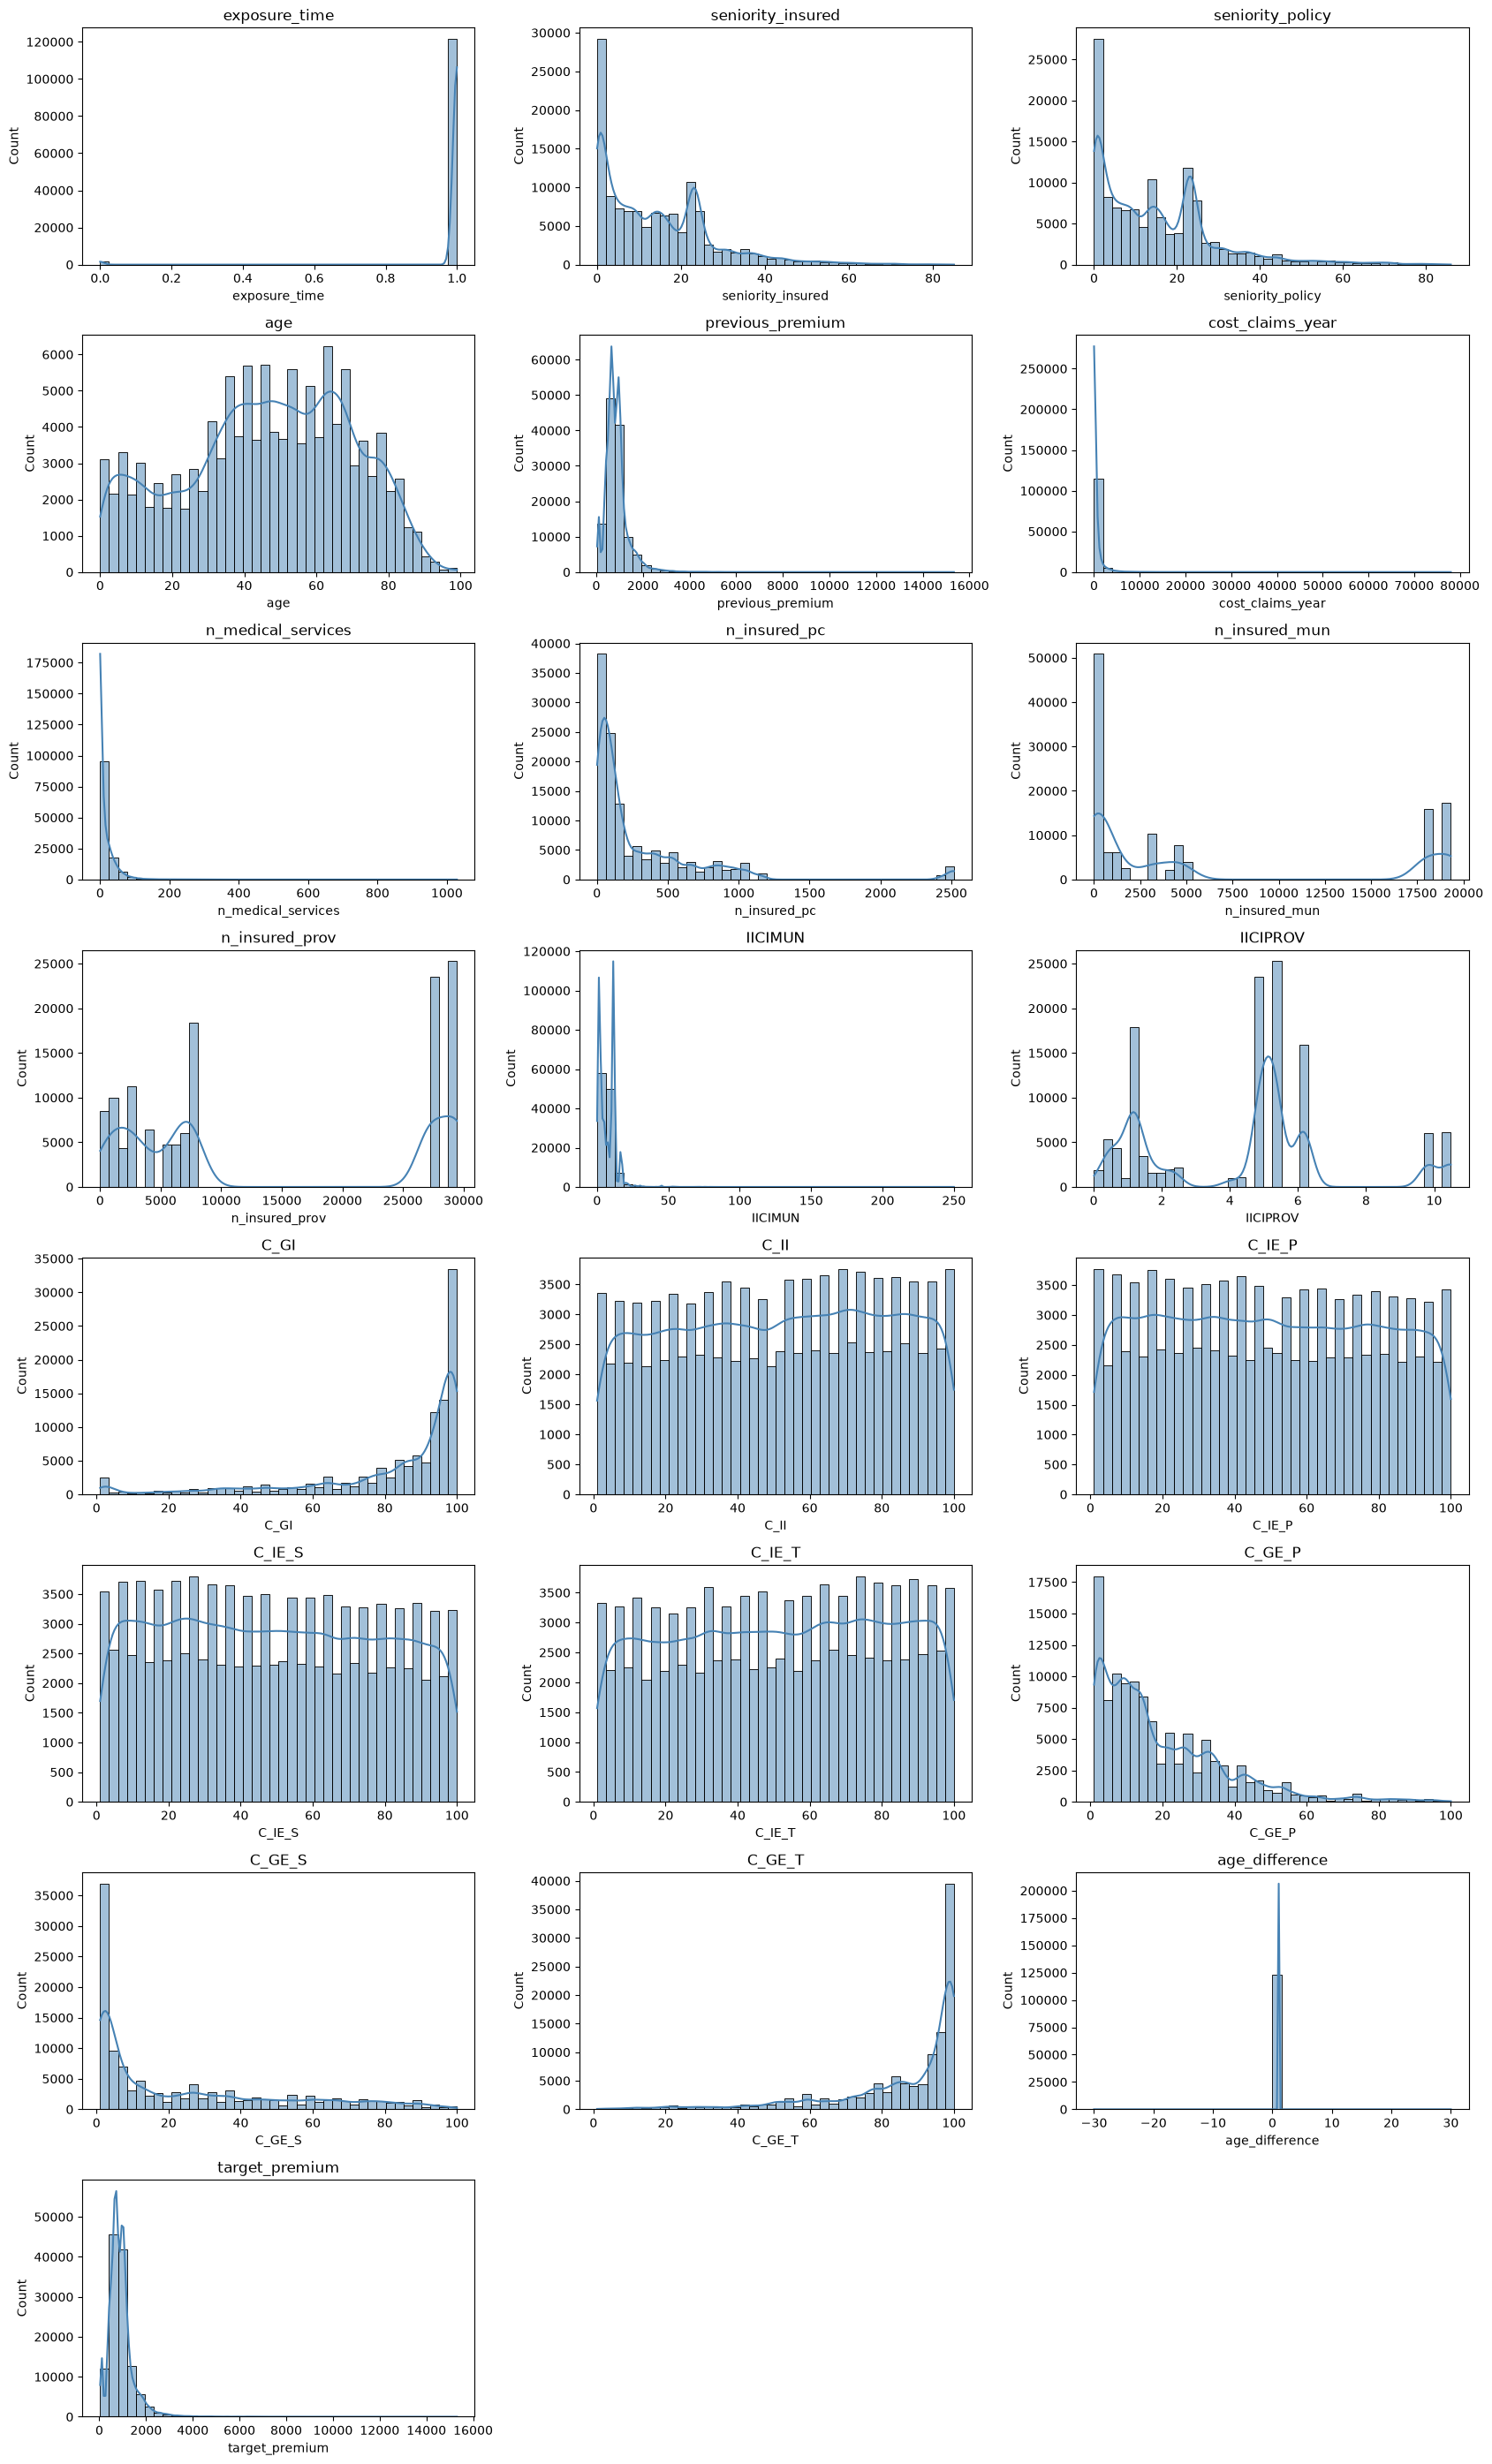

In [109]:
n_cols = 3
n_rows = int(np.ceil(len(normality_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(17, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(normality_features):
    sns.histplot(
        df[col].dropna(),
        bins=40,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )
    axes[i].set_title(col)

for j in range(len(normality_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 10.4 Normal Q–Q Plots

#### Compare observed feature quantiles against theoretical normal-distribution quantiles. Points close to the reference line indicate approximate normality, while systematic curvature suggests skewness or tail differences.

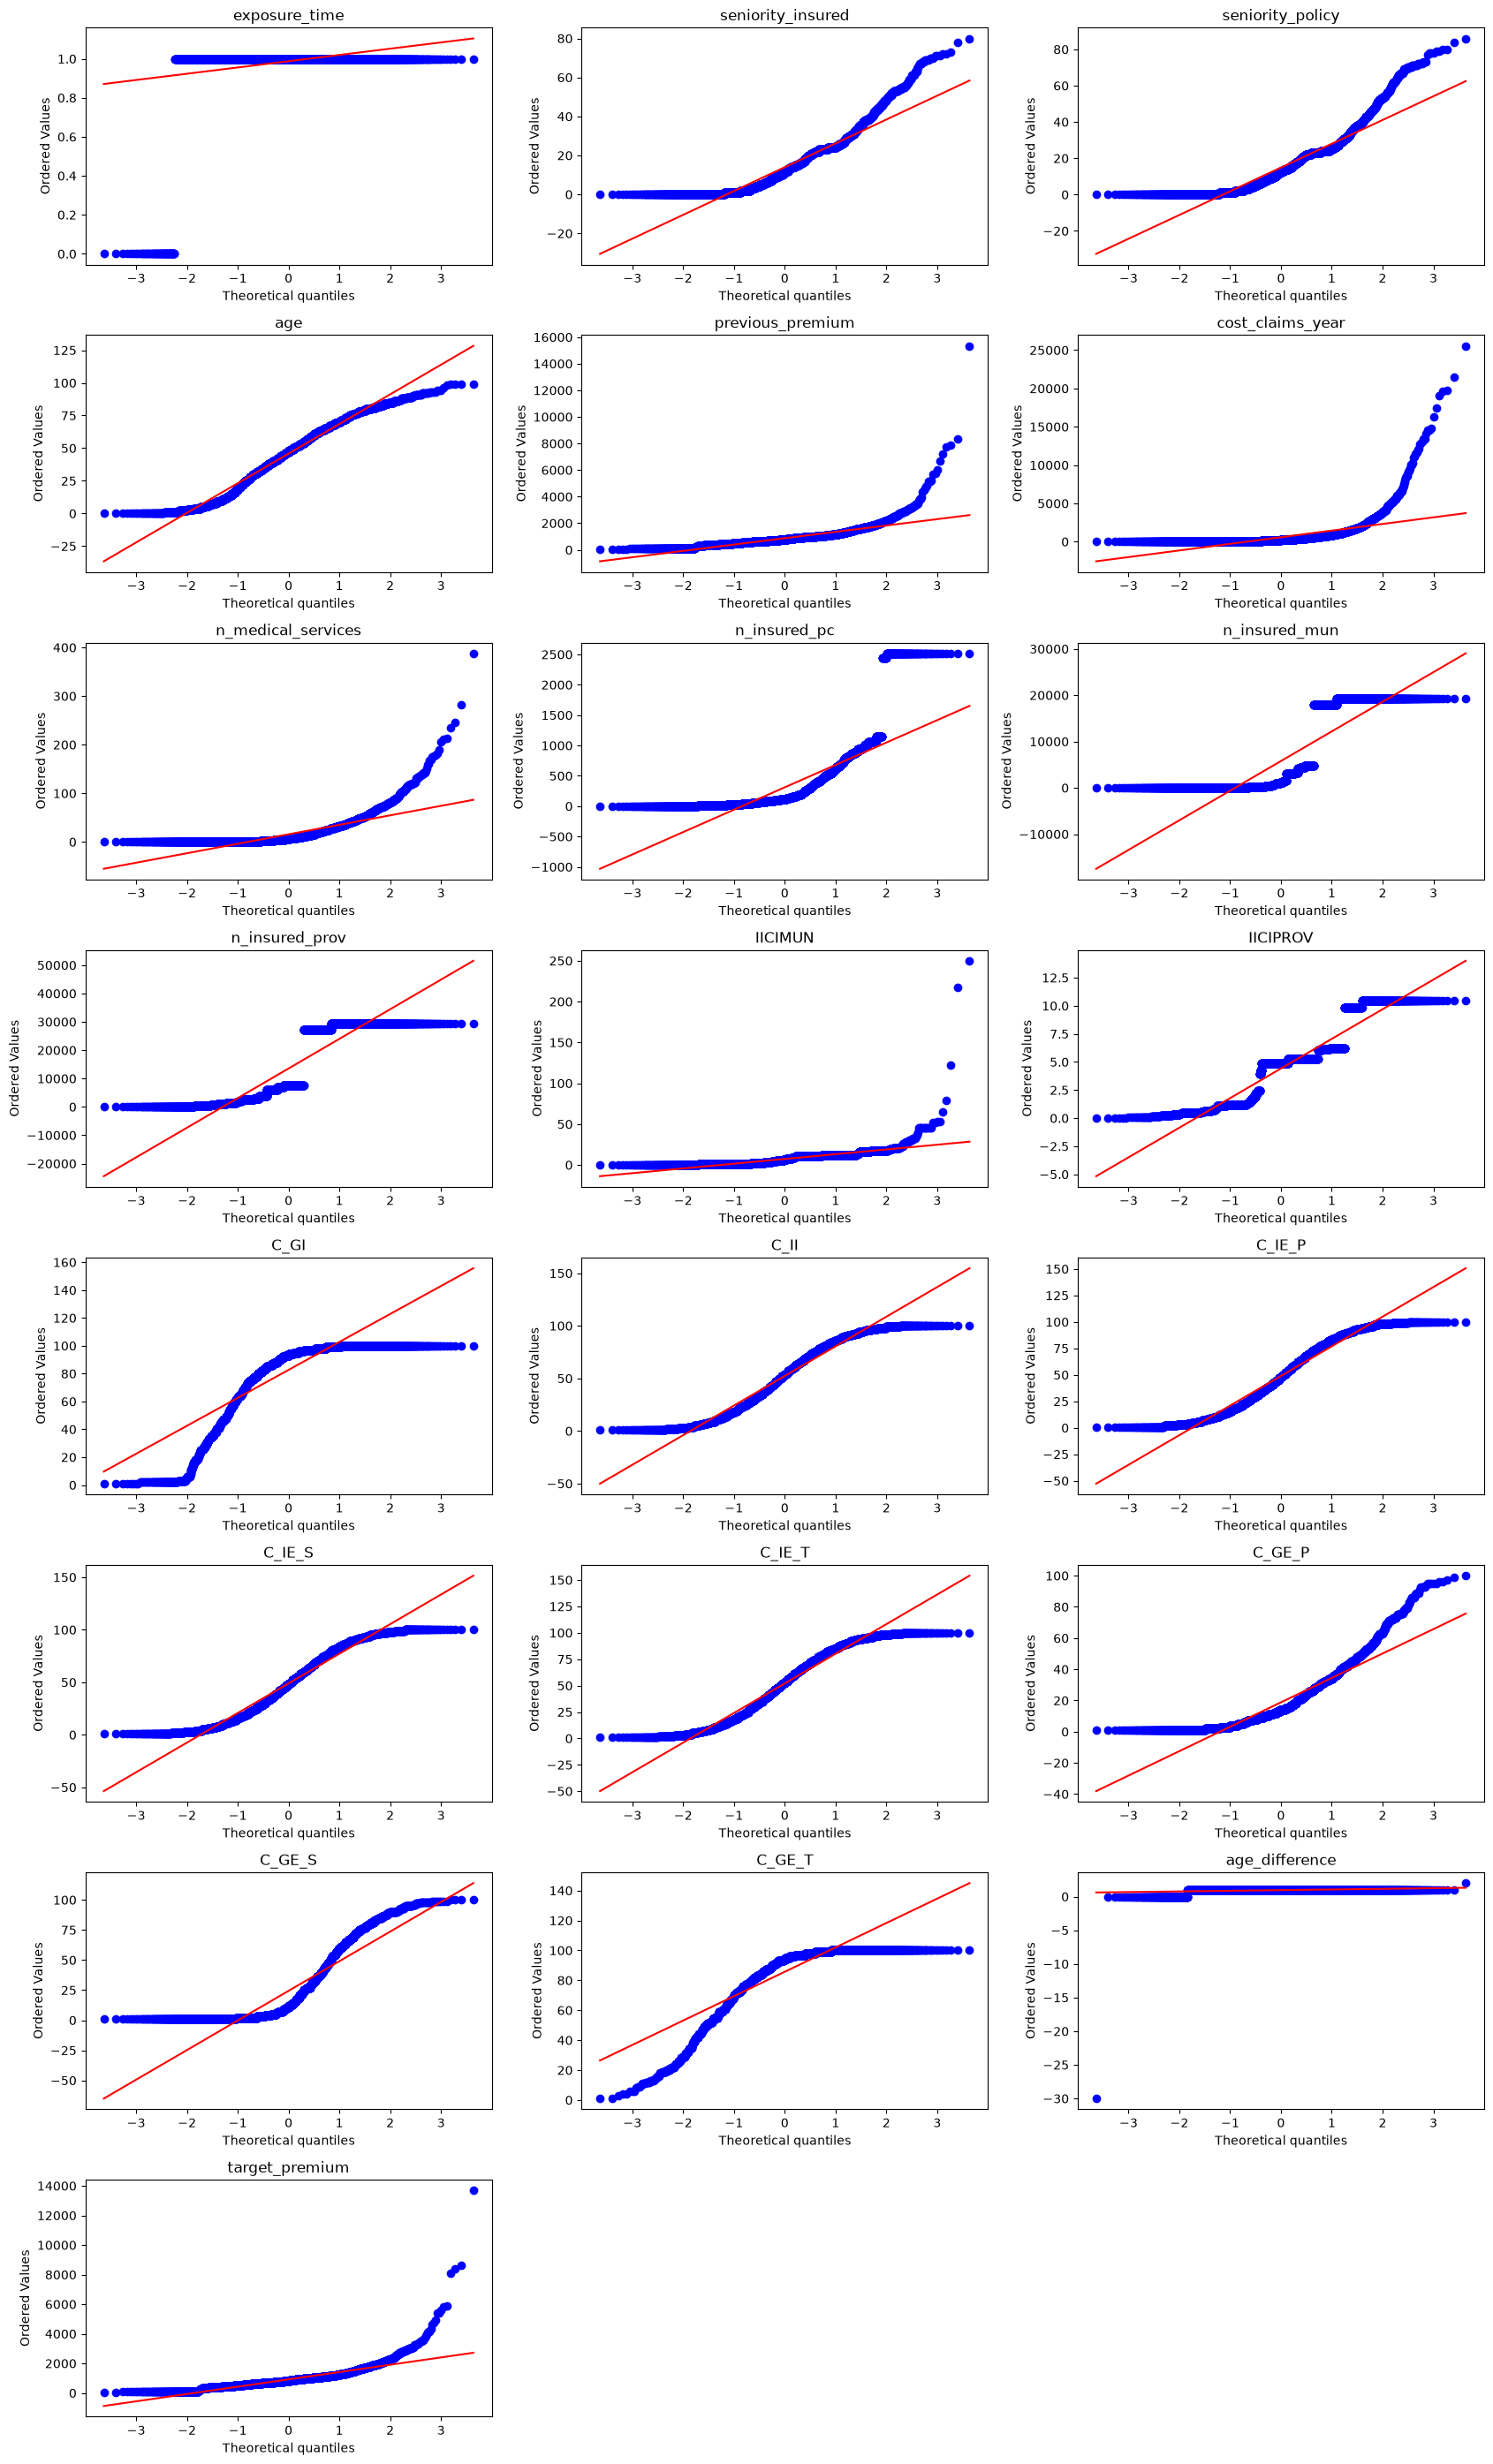

In [110]:
from scipy import stats
n_cols = 3
n_rows = int(np.ceil(len(normality_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(17, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(normality_features):

    values = df[col].dropna()

    if len(values) > 5000:
        values = values.sample(
            n=5000,
            random_state=42
        )

    if values.nunique() > 1:
        stats.probplot(
            values,
            dist="norm",
            plot=axes[i]
        )
    else:
        axes[i].text(
            0.5, 0.5,
            "Constant variable",
            ha="center",
            va="center"
        )

    axes[i].set_title(col)

for j in range(len(normality_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 10.5 Shapiro–Wilk Normality Test

#### Apply the Shapiro–Wilk test to a sample of each numerical variable. The null hypothesis is that observations come from a normal distribution. Sampling is used because the dataset is large and the test is sensitive to small deviations.

In [111]:

shapiro_results = []

for col in normality_features:

    values = df[col].dropna()

    if values.nunique() < 2:
        continue

    if len(values) > 5000:
        values = values.sample(
            n=5000,
            random_state=42
        )

    statistic, p_value = stats.shapiro(values)

    shapiro_results.append({
        "Feature": col,
        "Sample Size": len(values),
        "W Statistic": statistic,
        "P Value": p_value,
        "Reject Normality (5%)": p_value < 0.05
    })

shapiro_df = pd.DataFrame(shapiro_results)

display(shapiro_df.round(5))


,Feature,Sample Size,W Statistic,P Value,Reject Normality (5%)
0,exposure_time,5000,0.08430,0.0,True
1,seniority_insured,5000,0.88883,0.0,True
2,seniority_policy,5000,0.87727,0.0,True
3,age,5000,0.97624,0.0,True
4,previous_premium,5000,0.67891,0.0,True
5,cost_claims_year,5000,0.38411,0.0,True
6,n_medical_services,5000,0.65129,0.0,True
7,n_insured_pc,5000,0.62535,0.0,True
8,n_insured_mun,5000,0.67800,0.0,True
9,n_insured_prov,5000,0.76125,0.0,True


### 10.6 D’Agostino–Pearson Normality Test

#### Apply a complementary normality test based on skewness and kurtosis. This provides another statistical perspective on departures from normality.

In [112]:

dagostino_results = []

for col in normality_features:

    values = df[col].dropna()

    if len(values) < 8 or values.nunique() < 2:
        continue

    if len(values) > 5000:
        values = values.sample(
            n=5000,
            random_state=42
        )

    statistic, p_value = stats.normaltest(values)

    dagostino_results.append({
        "Feature": col,
        "K2 Statistic": statistic,
        "P Value": p_value,
        "Reject Normality (5%)": p_value < 0.05
    })

dagostino_df = pd.DataFrame(dagostino_results)

display(dagostino_df.round(5))


,Feature,K2 Statistic,P Value,Reject Normality (5%)
0,exposure_time,7142.03220,0.0,True
1,seniority_insured,995.75253,0.0,True
2,seniority_policy,1233.79203,0.0,True
3,age,503.11987,0.0,True
4,previous_premium,6213.31574,0.0,True
5,cost_claims_year,6670.48135,0.0,True
6,n_medical_services,4102.32650,0.0,True
7,n_insured_pc,3226.77061,0.0,True
8,n_insured_mun,1133.39518,0.0,True
9,n_insured_prov,21872.32050,0.0,True


### 10.7 Normality Test Comparison

#### Compare the results of both statistical tests to identify variables showing consistent evidence of departures from normality.

In [113]:

normality_comparison = shapiro_df[
    ["Feature", "P Value", "Reject Normality (5%)"]
].merge(
    dagostino_df[
        ["Feature", "P Value", "Reject Normality (5%)"]
    ],
    on="Feature",
    how="outer",
    suffixes=("_Shapiro", "_Dagostino")
)

display(normality_comparison)


,Feature,P Value_Shapiro,Reject Normality (5%)_Shapiro,P Value_Dagostino,Reject Normality (5%)_Dagostino
0,C_GE_P,4.782675e-54,True,1.937132e-274,True
1,C_GE_S,4.175998e-60,True,1.333714e-140,True
2,C_GE_T,5.855374e-65,True,0.000000e+00,True
3,C_GI,3.901332e-67,True,0.000000e+00,True
4,C_IE_P,9.091092e-37,True,0.000000e+00,True
5,C_IE_S,6.267419e-37,True,0.000000e+00,True
6,C_IE_T,7.340025e-37,True,0.000000e+00,True
7,C_II,5.748157e-37,True,0.000000e+00,True
8,IICIMUN,7.162922e-77,True,0.000000e+00,True
9,IICIPROV,5.452803e-52,True,5.387639e-31,True


### 10.8 Target Premium Normality

#### Examine the target premium separately to assess its distribution shape, skewness, and deviation from theoretical normality.

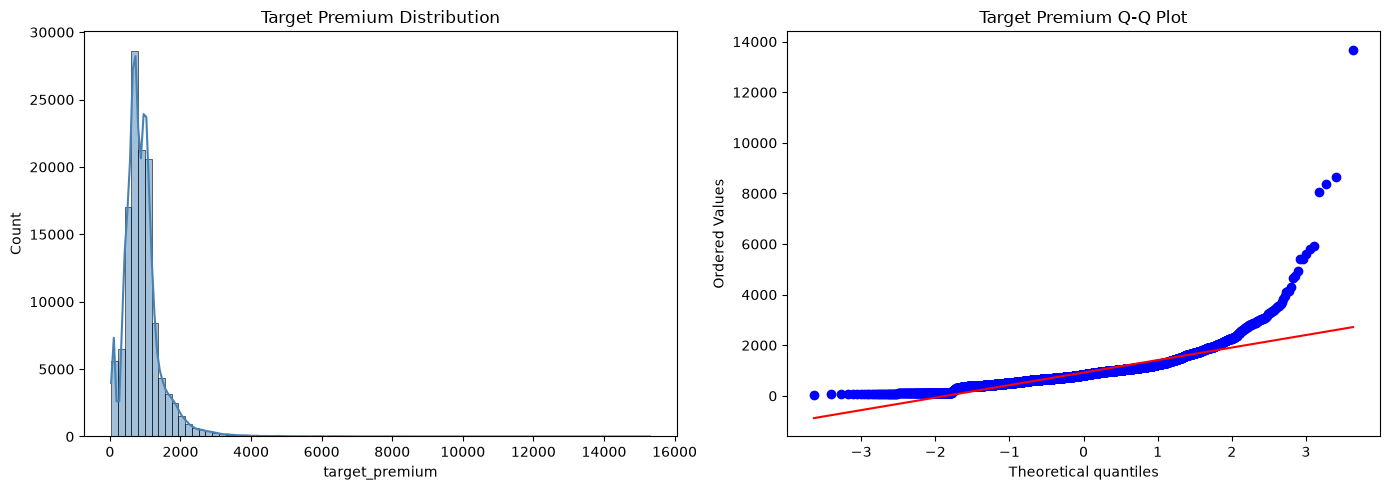

Target skewness: 4.102
Target excess kurtosis: 43.702


In [114]:

target_values = df[target].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    target_values,
    bins=80,
    kde=True,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Target Premium Distribution")

stats.probplot(
    target_values.sample(
        n=min(5000, len(target_values)),
        random_state=42
    ),
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Target Premium Q-Q Plot")

plt.tight_layout()
plt.show()

print("Target skewness:", round(target_values.skew(), 3))
print("Target excess kurtosis:", round(target_values.kurt(), 3))


### 10.9 Exploratory Log Transformation of Target Premium

#### Compare the original target distribution with its logarithmic transformation to assess whether right skewness and extreme-value influence are reduced.

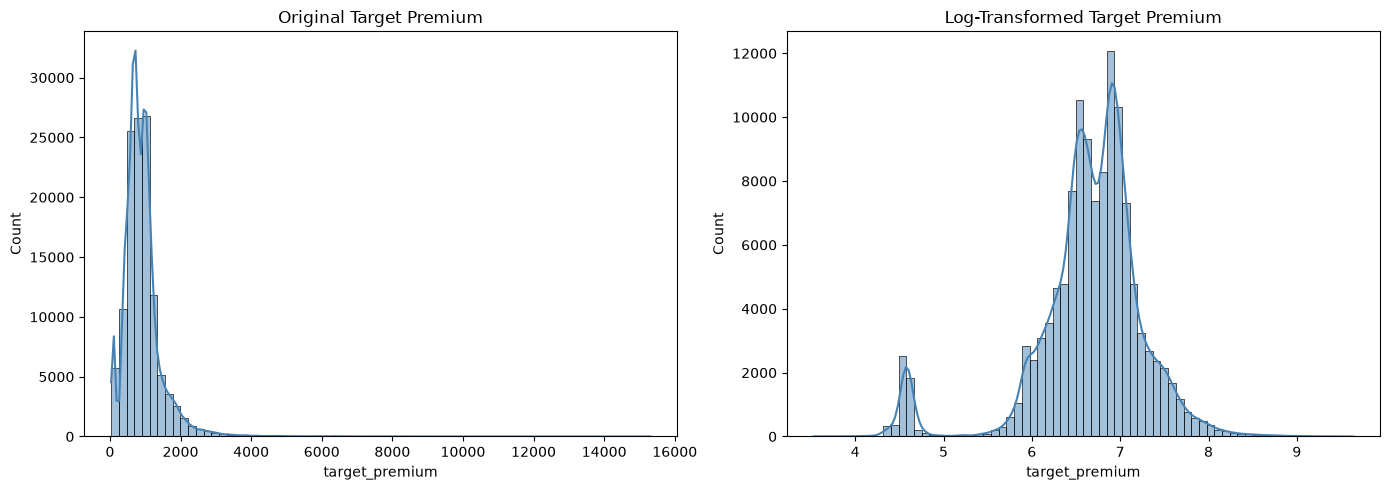

Original skewness: 4.102
Log skewness: -1.229
Original excess kurtosis: 43.702
Log excess kurtosis: 3.473


In [115]:

positive_target = df.loc[
    df[target] > 0, target
]

log_target = np.log(positive_target)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    positive_target,
    bins=70,
    kde=True,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Original Target Premium")

sns.histplot(
    log_target,
    bins=70,
    kde=True,
    ax=axes[1],
    color="steelblue"
)

axes[1].set_title("Log-Transformed Target Premium")

plt.tight_layout()
plt.show()

print("Original skewness:", round(positive_target.skew(), 3))
print("Log skewness:", round(log_target.skew(), 3))
print("Original excess kurtosis:", round(positive_target.kurt(), 3))
print("Log excess kurtosis:", round(log_target.kurt(), 3))

### 10.11 Normality Analysis Summary

#### Summarize distribution shape statistics and normality test results to identify skewed and heavy-tailed numerical variables that may benefit from further preprocessing investigation.

In [116]:
final_normality_summary = (
    normality_summary[
        ["Skewness", "Excess Kurtosis"]
    ]
    .reset_index()
    .rename(columns={"index": "Feature"})
    .merge(
        normality_comparison,
        on="Feature",
        how="left"
    )
)

display(
    final_normality_summary.sort_values(
        "Skewness",
        ascending=False
    ).round(4)
)


,Feature,Skewness,Excess Kurtosis,P Value_Shapiro,Reject Normality (5%)_Shapiro,P Value_Dagostino,Reject Normality (5%)_Dagostino
5,cost_claims_year,10.8954,217.0234,0.0,True,0.0,True
20,age_difference,9.0477,4430.6196,0.0,True,0.0,True
10,IICIMUN,6.3064,153.0381,0.0,True,0.0,True
6,n_medical_services,4.5508,57.4544,0.0,True,0.0,True
4,previous_premium,4.3703,49.5147,0.0,True,0.0,True
21,target_premium,4.1016,43.7018,0.0,True,0.0,True
7,n_insured_pc,3.0133,11.1276,0.0,True,0.0,True
17,C_GE_P,1.4700,2.4411,0.0,True,0.0,True
2,seniority_policy,1.3677,2.4767,0.0,True,0.0,True
1,seniority_insured,1.2478,1.9853,0.0,True,0.0,True


### Part 10 — Normality Analysis: Key Findings

#### Normality analysis reveals significant departures from normality across all 22 numerical variables according to both Shapiro–Wilk and D’Agostino–Pearson tests. The strongest right-skewed distributions occur in claims costs, medical-service utilization, geographical indicators, and premium-related variables.
#### The target premium is strongly right-skewed (4.102), with high excess kurtosis (43.702), indicating substantial tail behavior. A logarithmic transformation reduces skewness to −1.229 and excess kurtosis to 3.473, although the transformed distribution remains non-normal.
#### These findings suggest that selected transformations may be useful for regression modeling, particularly for scale-sensitive or outlier-sensitive methods. However, transformations will be evaluated empirically rather than applied solely to satisfy normality assumptions. No observations or features are modified during this analysis.

### 11.1 Numerical Variables for Correlation Analysis

#### Select numerical predictors and the target variable for correlation analysis. Identifier and calendar-year variables are excluded because their numerical values do not necessarily represent meaningful continuous measurements.

In [117]:
target = "target_premium"

correlation_features = [
    col for col in num_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

correlation_features = list(dict.fromkeys(
    correlation_features + [target]
))

print("Variables selected:", len(correlation_features))
print(correlation_features)


Variables selected: 22
['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'previous_premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'age_difference', 'target_premium']


### 11.2 Pearson Correlation Analysis

#### Calculate the Pearson correlation matrix to identify positive and negative linear associations among numerical variables and the renewal premium.

In [118]:
pearson_corr = df[
    correlation_features
].corr(method="pearson")

display(pearson_corr.round(3))


,exposure_time,seniority_insured,seniority_policy,age,previous_premium,cost_claims_year,n_medical_services,n_insured_pc,n_insured_mun,n_insured_prov,...,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,age_difference,target_premium
exposure_time,1.000,0.062,0.062,0.044,0.036,0.004,0.016,0.028,0.038,0.034,...,0.038,0.034,-0.030,-0.038,0.038,-0.030,-0.036,0.033,0.007,0.037
seniority_insured,0.062,1.000,0.957,0.519,0.192,0.067,0.136,0.196,0.459,0.408,...,0.195,0.206,-0.128,-0.236,0.210,-0.116,-0.225,0.172,0.140,0.200
seniority_policy,0.062,0.957,1.000,0.439,0.161,0.052,0.114,0.201,0.471,0.422,...,0.196,0.205,-0.127,-0.236,0.210,-0.117,-0.227,0.174,0.136,0.168
age,0.044,0.519,0.439,1.000,0.433,0.166,0.256,0.062,0.210,0.148,...,0.112,0.140,-0.082,-0.167,0.142,-0.059,-0.152,0.100,0.090,0.447
previous_premium,0.036,0.192,0.161,0.433,1.000,0.243,0.299,-0.048,-0.066,-0.125,...,0.068,0.106,-0.073,-0.125,0.108,-0.052,-0.117,0.080,0.083,0.986
cost_claims_year,0.004,0.067,0.052,0.166,0.243,1.000,0.627,0.007,-0.002,-0.021,...,0.015,0.024,-0.021,-0.032,0.029,-0.017,-0.031,0.024,0.046,0.275
n_medical_services,0.016,0.136,0.114,0.256,0.299,0.627,1.000,0.022,0.014,-0.003,...,0.049,0.036,-0.013,-0.042,0.034,-0.017,-0.042,0.032,0.068,0.323
n_insured_pc,0.028,0.196,0.201,0.062,-0.048,0.007,0.022,1.000,0.499,0.275,...,0.355,0.412,-0.306,-0.469,0.446,-0.310,-0.445,0.386,0.048,-0.049
n_insured_mun,0.038,0.459,0.471,0.210,-0.066,-0.002,0.014,0.499,1.000,0.707,...,0.350,0.402,-0.297,-0.497,0.454,-0.274,-0.449,0.371,0.058,-0.064
n_insured_prov,0.034,0.408,0.422,0.148,-0.125,-0.021,-0.003,0.275,0.707,1.000,...,0.357,0.333,-0.203,-0.242,0.252,-0.225,-0.212,0.238,0.041,-0.124


### 11.3 Pearson Correlation Heatmap

#### Visualize linear associations across numerical features to identify strongly correlated groups and potential predictor redundancy.

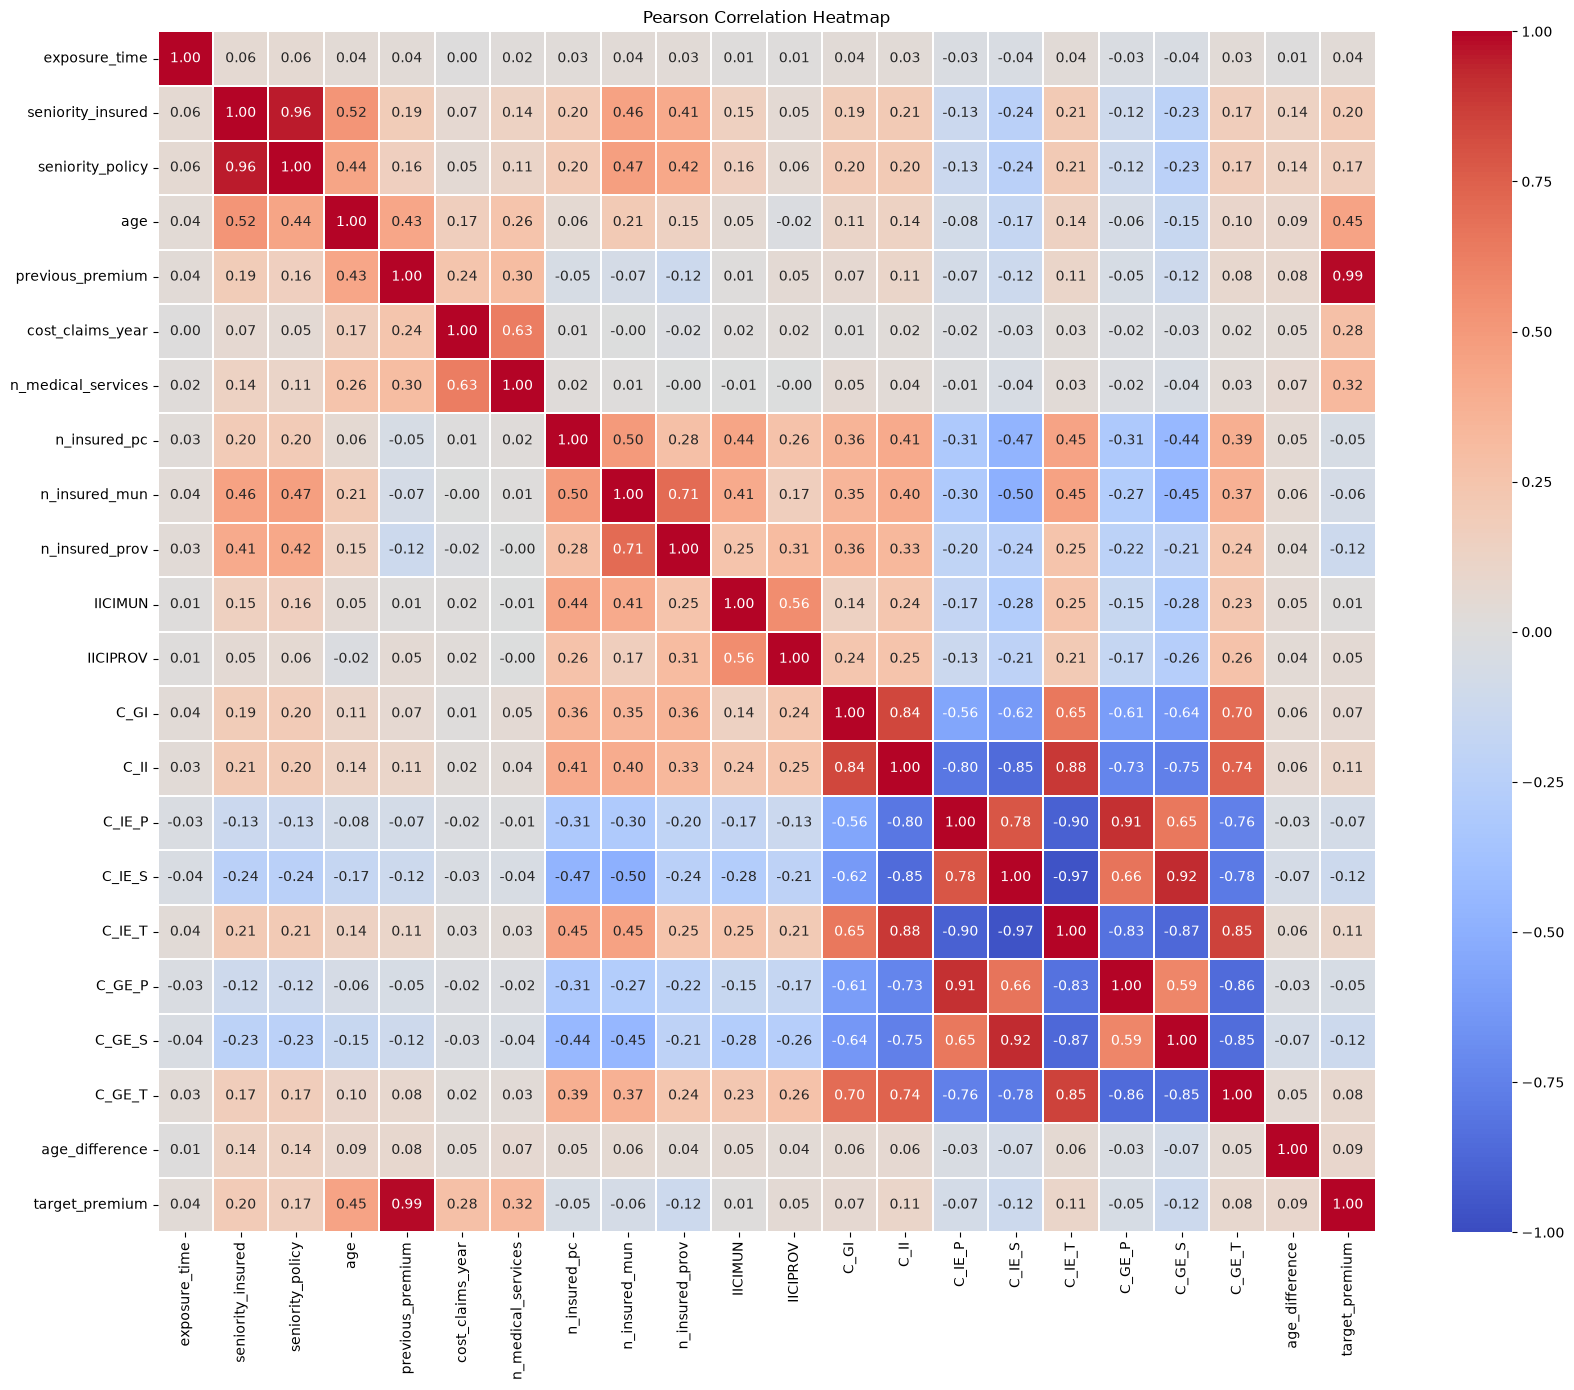

In [119]:

plt.figure(figsize=(17, 14))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)

plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()


### 11.4 Pearson Correlation with Target Premium

#### Rank numerical predictors by their linear correlation with the renewal premium to identify potentially informative variables.

In [120]:

pearson_target = (
    pearson_corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

display(
    pearson_target.to_frame(
        "Pearson Correlation"
    ).round(4)
)


,Pearson Correlation
previous_premium,0.9861
age,0.4472
n_medical_services,0.3230
cost_claims_year,0.2754
seniority_insured,0.1996
seniority_policy,0.1679
C_IE_S,-0.1248
n_insured_prov,-0.1243
C_GE_S,-0.1172
C_IE_T,0.1078


### 11.5 Spearman Rank Correlation Analysis

#### Calculate Spearman correlations to identify monotonic associations that may not be captured adequately by Pearson correlation.

In [121]:

spearman_corr = df[
    correlation_features
].corr(method="spearman")

display(spearman_corr.round(3))


,exposure_time,seniority_insured,seniority_policy,age,previous_premium,cost_claims_year,n_medical_services,n_insured_pc,n_insured_mun,n_insured_prov,...,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,age_difference,target_premium
exposure_time,1.000,0.069,0.071,0.046,0.048,0.029,0.033,0.033,0.037,0.021,...,0.034,0.033,-0.029,-0.037,0.038,-0.029,-0.036,0.037,0.009,0.049
seniority_insured,0.069,1.000,0.972,0.537,0.410,0.159,0.184,0.273,0.354,0.307,...,0.222,0.222,-0.136,-0.257,0.226,-0.133,-0.258,0.226,0.278,0.417
seniority_policy,0.071,0.972,1.000,0.480,0.384,0.146,0.172,0.284,0.365,0.320,...,0.224,0.224,-0.138,-0.261,0.229,-0.135,-0.261,0.230,0.268,0.391
age,0.046,0.537,0.480,1.000,0.555,0.245,0.263,0.117,0.179,0.121,...,0.143,0.144,-0.085,-0.171,0.145,-0.084,-0.170,0.144,0.128,0.571
previous_premium,0.048,0.410,0.384,0.555,1.000,0.363,0.348,0.005,0.045,-0.040,...,0.151,0.150,-0.102,-0.173,0.150,-0.099,-0.169,0.151,0.165,0.986
cost_claims_year,0.029,0.159,0.146,0.245,0.363,1.000,0.911,0.033,0.034,-0.013,...,0.037,0.036,-0.026,-0.044,0.039,-0.025,-0.043,0.043,0.155,0.384
n_medical_services,0.033,0.184,0.172,0.263,0.348,0.911,1.000,0.046,0.050,0.015,...,0.042,0.039,-0.011,-0.040,0.033,-0.009,-0.039,0.036,0.153,0.366
n_insured_pc,0.033,0.273,0.284,0.117,0.005,0.033,0.046,1.000,0.795,0.536,...,0.466,0.468,-0.353,-0.534,0.513,-0.349,-0.538,0.517,0.091,0.009
n_insured_mun,0.037,0.354,0.365,0.179,0.045,0.034,0.050,0.795,1.000,0.564,...,0.477,0.477,-0.360,-0.610,0.564,-0.358,-0.609,0.560,0.087,0.049
n_insured_prov,0.021,0.307,0.320,0.121,-0.040,-0.013,0.015,0.536,0.564,1.000,...,0.400,0.399,-0.257,-0.299,0.313,-0.256,-0.299,0.310,0.063,-0.037


### 11.6 Spearman Correlation Heatmap

#### Visualize monotonic associations across numerical variables to identify relationships that differ from the Pearson correlation structure.

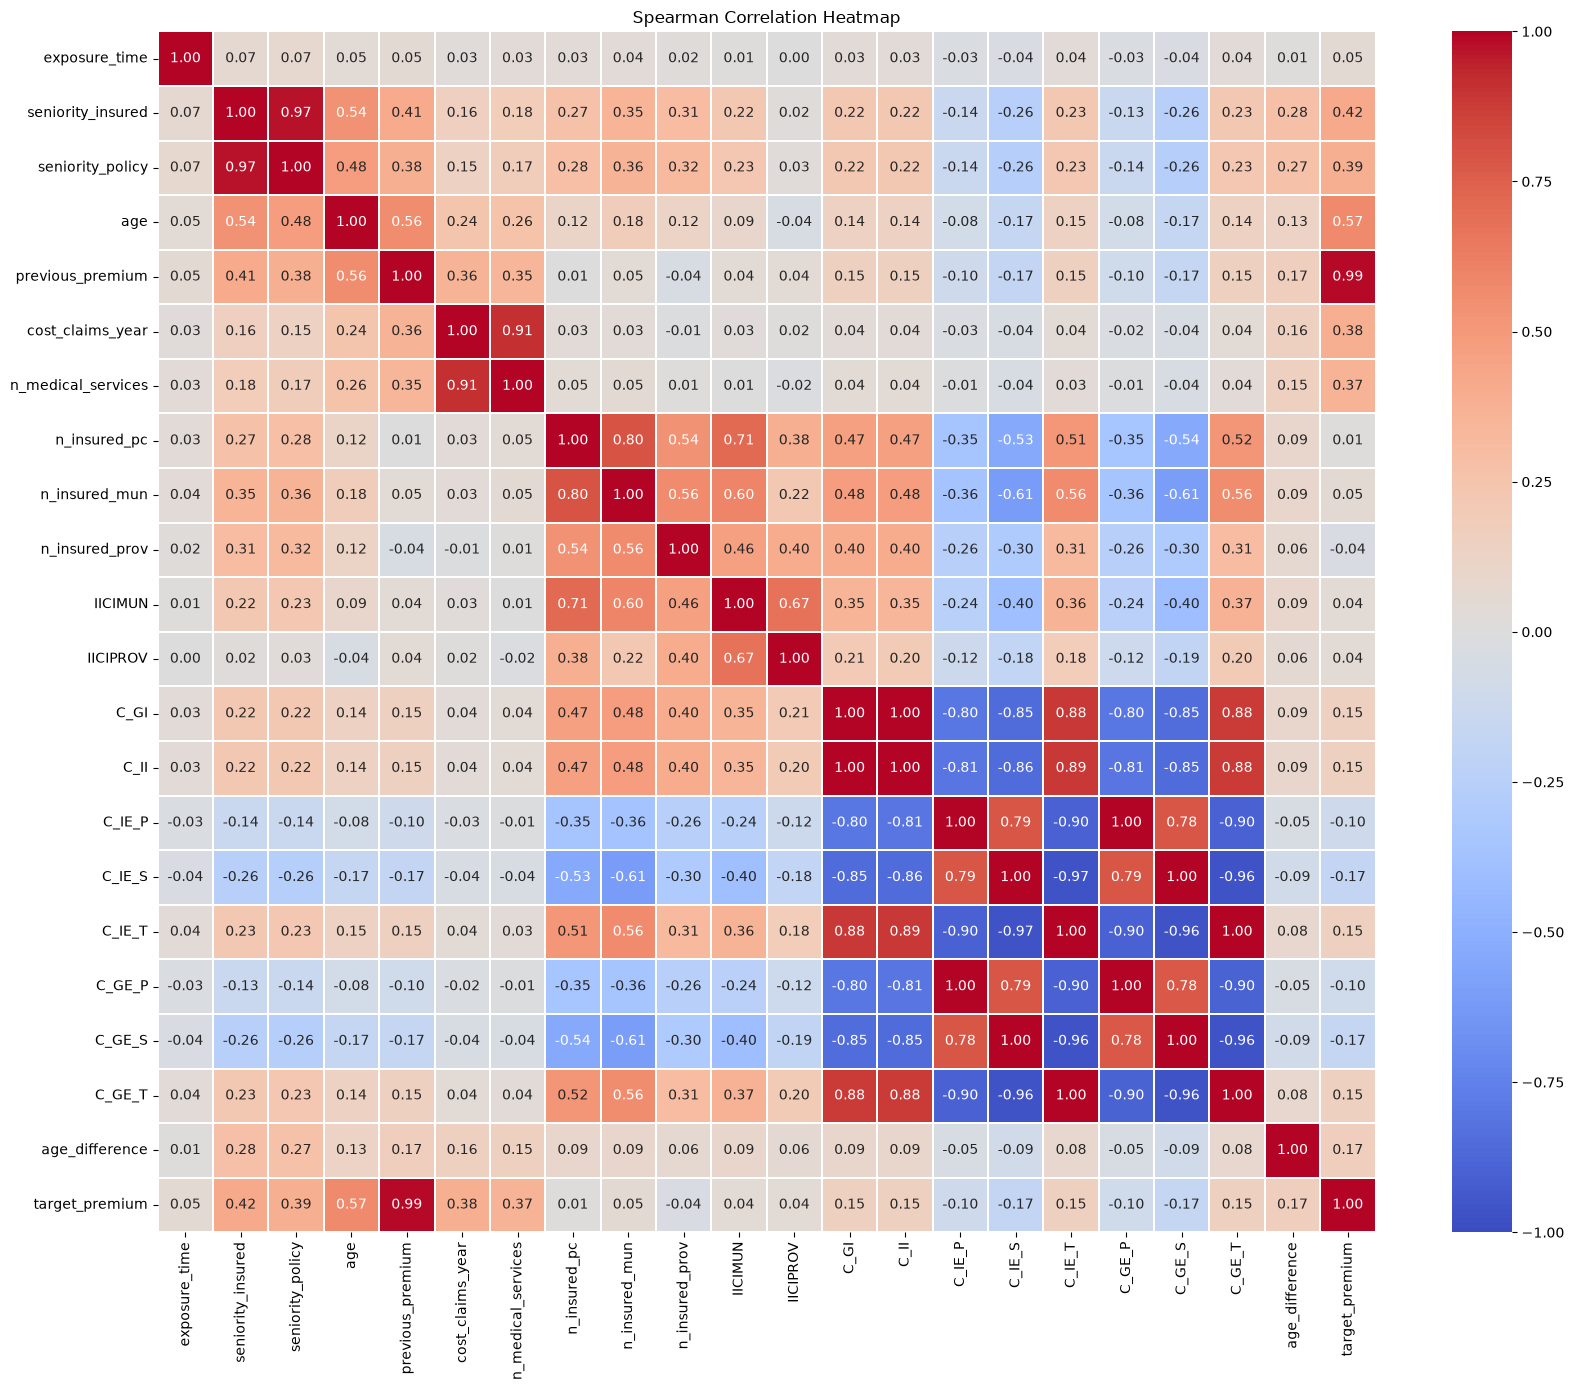

In [122]:

plt.figure(figsize=(17, 14))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()


### 11.7 Spearman Correlation with Target Premium

#### Rank numerical predictors by their monotonic association with the renewal premium to identify potentially informative relationships beyond linear correlation.

In [123]:
spearman_target = (
    spearman_corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

display(
    spearman_target.to_frame(
        "Spearman Correlation"
    ).round(4)
)


,Spearman Correlation
previous_premium,0.9861
age,0.5707
seniority_insured,0.4168
seniority_policy,0.3906
cost_claims_year,0.3841
n_medical_services,0.3664
C_IE_S,-0.1722
age_difference,0.1700
C_GE_S,-0.1689
C_GE_T,0.1514


### 11.8 Pearson and Spearman Comparison

#### Compare linear and monotonic correlations with the target premium to identify variables whose association patterns differ across the two methods.

In [124]:

correlation_comparison = pd.DataFrame({
    "Pearson": pearson_target,
    "Spearman": spearman_target
})

correlation_comparison["Absolute Difference"] = (
    correlation_comparison["Pearson"]
    - correlation_comparison["Spearman"]
).abs()

display(
    correlation_comparison.sort_values(
        "Absolute Difference",
        ascending=False
    ).round(4)
)


,Pearson,Spearman,Absolute Difference
seniority_policy,0.1679,0.3906,0.2227
seniority_insured,0.1996,0.4168,0.2172
age,0.4472,0.5707,0.1235
n_insured_mun,-0.0640,0.0486,0.1126
cost_claims_year,0.2754,0.3841,0.1087
n_insured_prov,-0.1243,-0.0366,0.0878
C_GI,0.0676,0.1507,0.0831
age_difference,0.0892,0.1700,0.0808
C_GE_T,0.0802,0.1514,0.0712
n_insured_pc,-0.0489,0.0091,0.0579


### 11.9 Target Correlation Comparison Visualization

#### Compare Pearson and Spearman coefficients visually to examine the direction and relative strength of numerical associations with the target premium.

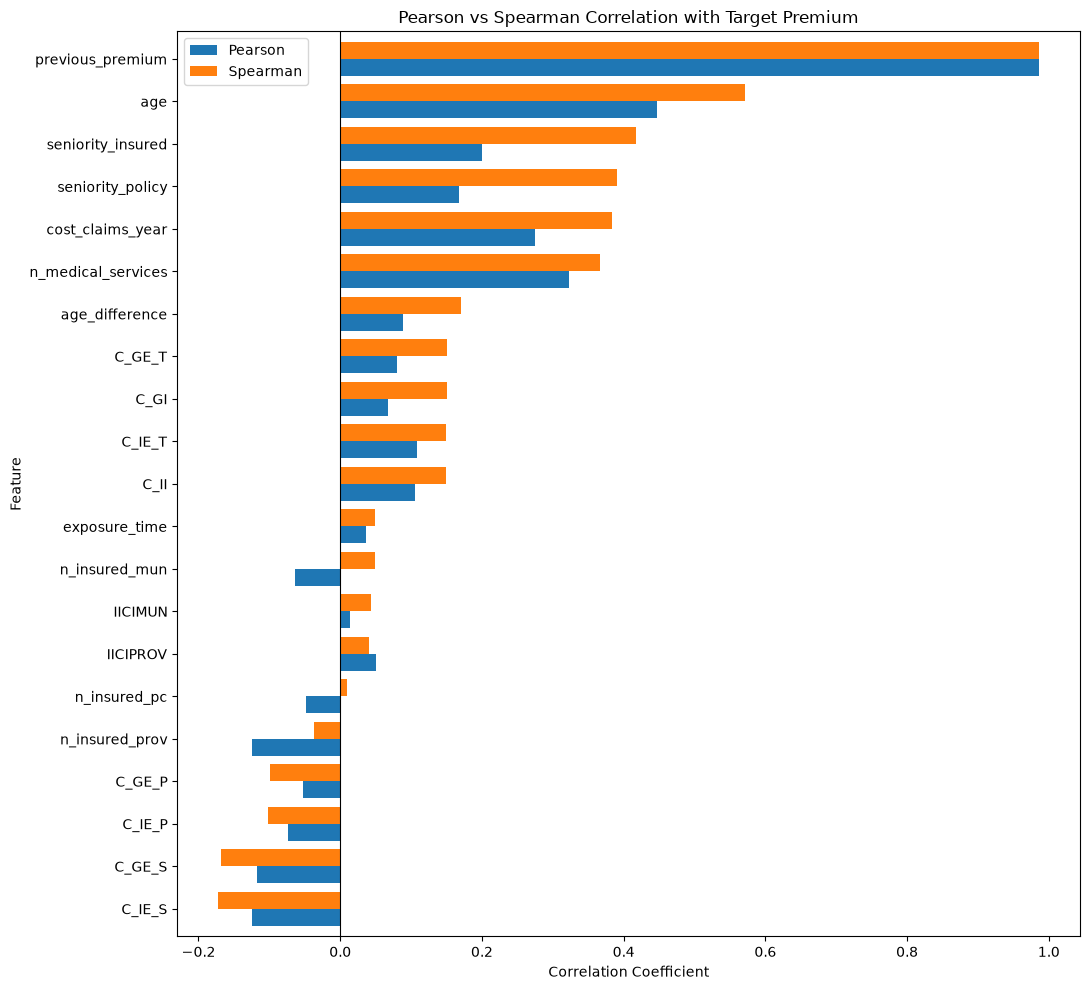

In [125]:

plot_corr = correlation_comparison[
    ["Pearson", "Spearman"]
].sort_values(
    "Spearman"
)

plot_corr.plot(
    kind="barh",
    figsize=(11, 10),
    width=0.8
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Pearson vs Spearman Correlation with Target Premium")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### 11.10 Highly Correlated Predictor Pairs

#### Identify numerical predictor pairs with an absolute Pearson correlation of at least 0.80 to screen for potential multicollinearity and redundant information.

In [126]:

predictor_features = [
    col for col in correlation_features
    if col != target
]

predictor_corr = pearson_corr.loc[
    predictor_features,
    predictor_features
]

upper_triangle = predictor_corr.where(
    np.triu(
        np.ones(predictor_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Pearson Correlation"
]

high_corr_pairs = high_corr_pairs.loc[
    high_corr_pairs["Pearson Correlation"].abs() >= 0.80
].copy()

high_corr_pairs = high_corr_pairs.sort_values(
    "Pearson Correlation",
    key=abs,
    ascending=False
)

display(high_corr_pairs.round(4))

print(
    "Highly correlated pairs:",
    len(high_corr_pairs)
)


,Feature 1,Feature 2,Pearson Correlation
331,C_IE_S,C_IE_T,-0.9656
23,seniority_insured,seniority_policy,0.9566
333,C_IE_S,C_GE_S,0.9230
311,C_IE_P,C_GE_P,0.9107
310,C_IE_P,C_IE_T,-0.9024
289,C_II,C_IE_T,0.8835
354,C_IE_T,C_GE_S,-0.8738
376,C_GE_P,C_GE_T,-0.8558
288,C_II,C_IE_S,-0.8530
355,C_IE_T,C_GE_T,0.8526


Highly correlated pairs: 14


### 11.11 Strong Monotonic Predictor Associations

#### Identify strongly monotonic predictor pairs that may not appear highly correlated under Pearson correlation.

In [127]:

predictor_spearman = spearman_corr.loc[
    predictor_features,
    predictor_features
]

upper_spearman = predictor_spearman.where(
    np.triu(
        np.ones(predictor_spearman.shape),
        k=1
    ).astype(bool)
)

high_spearman_pairs = (
    upper_spearman.stack()
    .reset_index()
)

high_spearman_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

high_spearman_pairs = high_spearman_pairs.loc[
    high_spearman_pairs["Spearman Correlation"].abs() >= 0.80
]

display(
    high_spearman_pairs.sort_values(
        "Spearman Correlation",
        key=abs,
        ascending=False
    ).round(4)
)


,Feature 1,Feature 2,Spearman Correlation
311,C_IE_P,C_GE_P,0.9994
333,C_IE_S,C_GE_S,0.9973
265,C_GI,C_II,0.9967
355,C_IE_T,C_GE_T,0.9962
23,seniority_insured,seniority_policy,0.9717
331,C_IE_S,C_IE_T,-0.9676
354,C_IE_T,C_GE_S,-0.9649
397,C_GE_S,C_GE_T,-0.9639
334,C_IE_S,C_GE_T,-0.9639
111,cost_claims_year,n_medical_services,0.9115


### 11.12 Previous Premium and Target Premium Association

#### Examine the linear and monotonic relationship between previous and renewal premiums, while recognizing that previous premium must be verified as available before the renewal pricing decision.

In [128]:

premium_corr_summary = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [
        df["previous_premium"].corr(
            df["target_premium"],
            method="pearson"
        ),
        df["previous_premium"].corr(
            df["target_premium"],
            method="spearman"
        )
    ]
})

display(premium_corr_summary.round(4))


,Method,Correlation
0,Pearson,0.9861
1,Spearman,0.9861


### 11.13 Year-Wise Correlation Stability

#### Compare feature–target correlations separately for 2017 and 2018 to identify relationships that may change across observation periods.

In [129]:

yearly_correlations = []

for year, group in df.groupby("period"):

    corr = group[
        correlation_features
    ].corr(method="spearman")[target]

    for feature, value in corr.items():
        if feature != target:
            yearly_correlations.append({
                "Period": year,
                "Feature": feature,
                "Spearman Correlation": value
            })

yearly_corr_df = pd.DataFrame(yearly_correlations)

yearly_corr_pivot = yearly_corr_df.pivot(
    index="Feature",
    columns="Period",
    values="Spearman Correlation"
)

display(yearly_corr_pivot.round(4))


Period,2017,2018
Feature,,
C_GE_P,-0.0934,-0.1073
C_GE_S,-0.1585,-0.1809
C_GE_T,0.1423,0.1620
C_GI,0.1404,0.1637
C_IE_P,-0.0958,-0.1097
C_IE_S,-0.1612,-0.1841
C_IE_T,0.1392,0.1611
C_II,0.1381,0.1624
IICIMUN,0.0381,0.0649


### 11.14 Changes in Correlation Across Years

#### Measure the absolute difference in feature–target Spearman correlations between 2017 and 2018 to identify potentially unstable associations.

In [130]:

if {2017, 2018}.issubset(yearly_corr_pivot.columns):

    yearly_corr_pivot["Absolute Difference"] = (
        yearly_corr_pivot[2018]
        - yearly_corr_pivot[2017]
    ).abs()

    display(
        yearly_corr_pivot.sort_values(
            "Absolute Difference",
            ascending=False
        ).round(4)
    )
else:
    print("Expected observation periods not found.")


Period,2017,2018,Absolute Difference
Feature,,,
n_insured_pc,-0.0337,0.0590,0.0927
age_difference,0.1410,0.1996,0.0586
n_insured_mun,0.0323,0.0816,0.0493
age,0.5530,0.5916,0.0386
n_medical_services,0.3500,0.3821,0.0320
seniority_policy,0.3751,0.4053,0.0302
cost_claims_year,0.3711,0.3994,0.0283
seniority_insured,0.4029,0.4305,0.0276
IICIMUN,0.0381,0.0649,0.0268


### 11.16 Correlation Analysis Summary

#### Summarize the strongest linear and monotonic target associations and identify highly correlated predictor pairs. These results will guide further bivariate and multivariate exploration without automatically eliminating variables.

In [131]:

final_correlation_summary = pd.DataFrame({
    "Pearson": pearson_target,
    "Spearman": spearman_target
})

final_correlation_summary["Max Absolute Correlation"] = (
    final_correlation_summary[
        ["Pearson", "Spearman"]
    ].abs().max(axis=1)
)

display(
    final_correlation_summary.sort_values(
        "Max Absolute Correlation",
        ascending=False
    ).round(4)
)

print(
    "\nHighly correlated Pearson predictor pairs:",
    len(high_corr_pairs)
)

print(
    "Highly correlated Spearman predictor pairs:",
    len(high_spearman_pairs)
)


,Pearson,Spearman,Max Absolute Correlation
previous_premium,0.9861,0.9861,0.9861
age,0.4472,0.5707,0.5707
seniority_insured,0.1996,0.4168,0.4168
seniority_policy,0.1679,0.3906,0.3906
cost_claims_year,0.2754,0.3841,0.3841
n_medical_services,0.3230,0.3664,0.3664
C_IE_S,-0.1248,-0.1722,0.1722
age_difference,0.0892,0.1700,0.1700
C_GE_S,-0.1172,-0.1689,0.1689
C_GE_T,0.0802,0.1514,0.1514



Highly correlated Pearson predictor pairs: 14
Highly correlated Spearman predictor pairs: 26


### Part 11 — Correlation Analysis: Key Findings
#### Correlation analysis identifies previous premium as the strongest numerical predictor associated with the renewal premium, with Pearson and Spearman coefficients of 0.9861. Age, policy seniority, insured seniority, claims costs, and medical-service utilization also exhibit meaningful positive associations.
#### Several predictors demonstrate stronger Spearman than Pearson correlations, suggesting possible nonlinear monotonic patterns or sensitivity to distributional characteristics. The analysis identifies 14 highly correlated Pearson predictor pairs and 26 highly correlated Spearman pairs, indicating potential multicollinearity, particularly among socioeconomic indicators.
#### The strongest associations remain broadly stable across 2017 and 2018. Nevertheless, correlation strength alone does not establish predictive suitability. Features potentially containing post-renewal information must undergo temporal availability verification before model development.

### 12.1 Bivariate Analysis Preparation

#### Select numerical and categorical predictors for examining their individual relationships with the renewal premium. Identifier variables, date variables, and the target itself are excluded from the predictor lists. The analysis is exploratory and does not determine final feature eligibility.

In [132]:
target = "target_premium"

bivariate_num = [
    col for col in num_cols
    if col in df.columns and col != target
]

bivariate_cat = [
    col for col in cat_cols
    if col in df.columns and col != target
]

print("Numerical predictors:", len(bivariate_num))
print("Categorical predictors:", len(bivariate_cat))

print("\nNumerical:", bivariate_num)
print("\nCategorical:", bivariate_cat)


Numerical predictors: 21
Categorical predictors: 10

Numerical: ['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'previous_premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'age_difference']

Categorical: ['lapse', 'type_policy', 'type_policy_dg', 'type_product', 'reimbursement', 'new_business', 'distribution_channel', 'gender', 'C_H', 'C_C']


### 12.2 Numerical Predictor Scatterplots

#### Visualize each numerical predictor against the target premium using a random sample of observations. These plots help identify relationship shape, dispersion, clusters, extreme values, and possible heteroscedasticity.

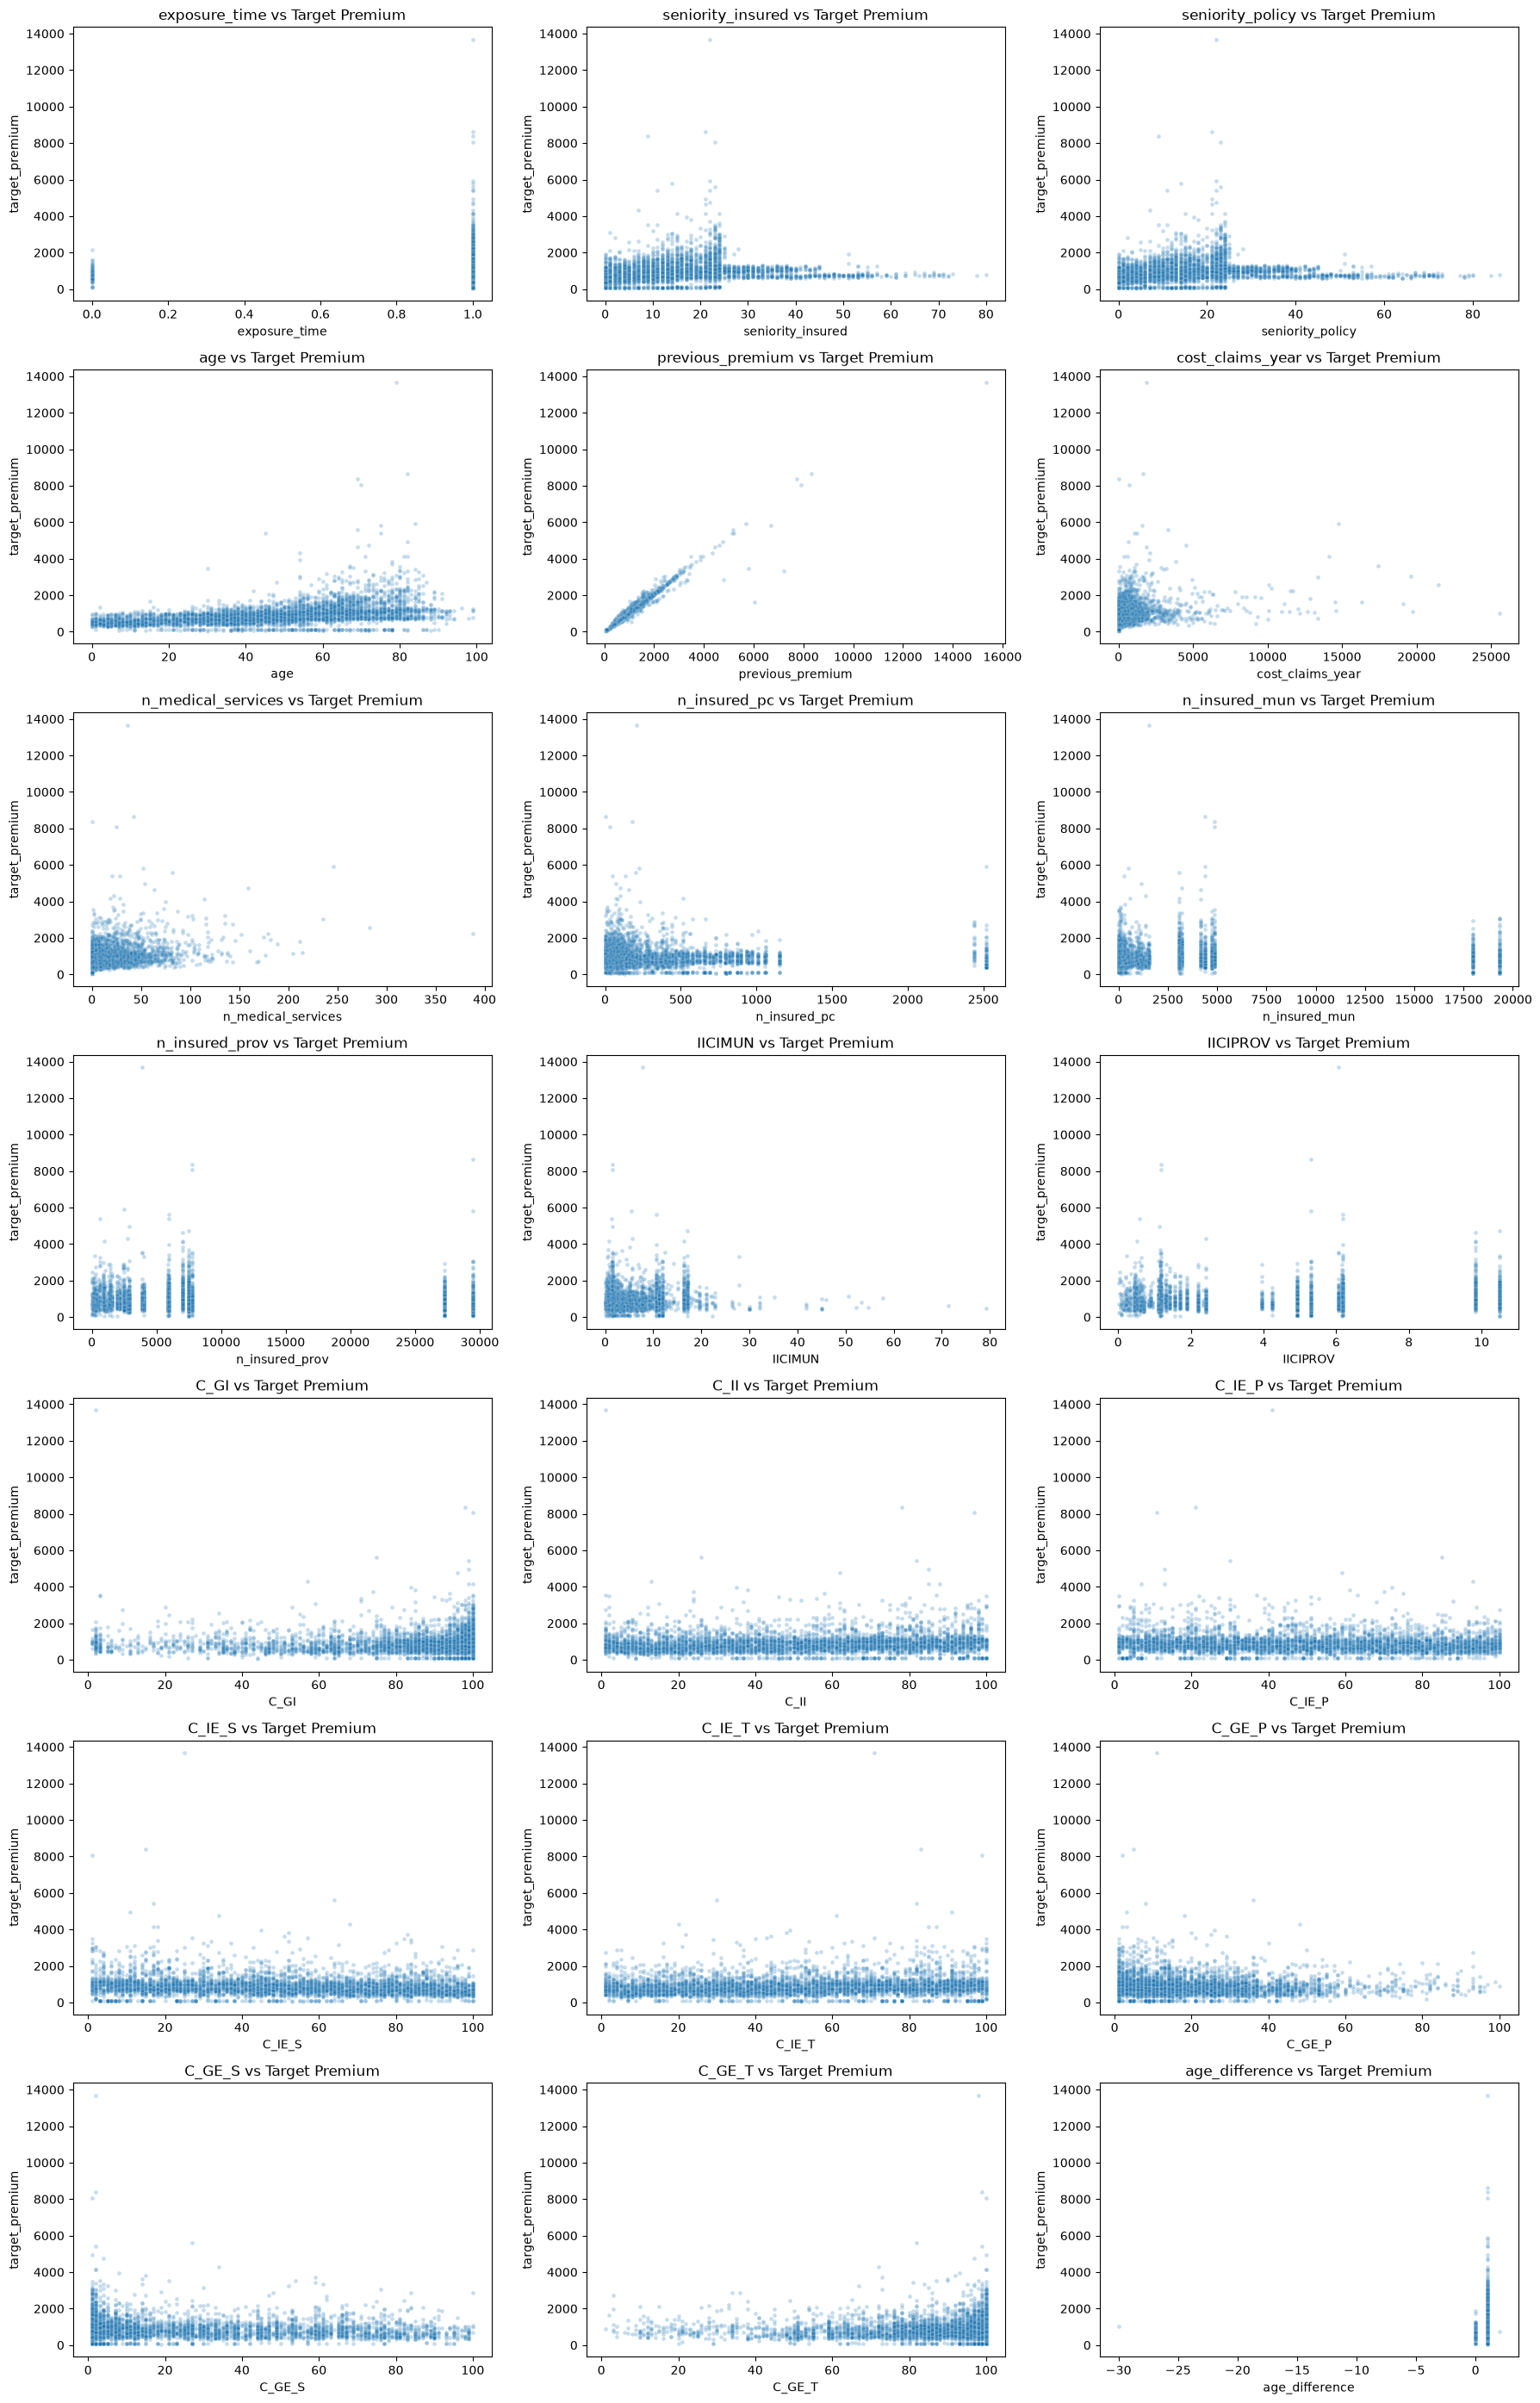

In [133]:

plot_sample = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

ncols = 3
nrows = int(np.ceil(len(bivariate_num) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, nrows * 4)
)

axes = np.array(axes).flatten()

for i, col in enumerate(bivariate_num):

    sns.scatterplot(
        data=plot_sample,
        x=col,
        y=target,
        alpha=0.25,
        s=12,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Target Premium")

for j in range(len(bivariate_num), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### 12.3 Previous Premium versus Renewal Premium

#### Compare previous and renewal premiums using a scatterplot and an equality reference line. Observations above the line represent premium increases, while observations below it represent premium decreases.

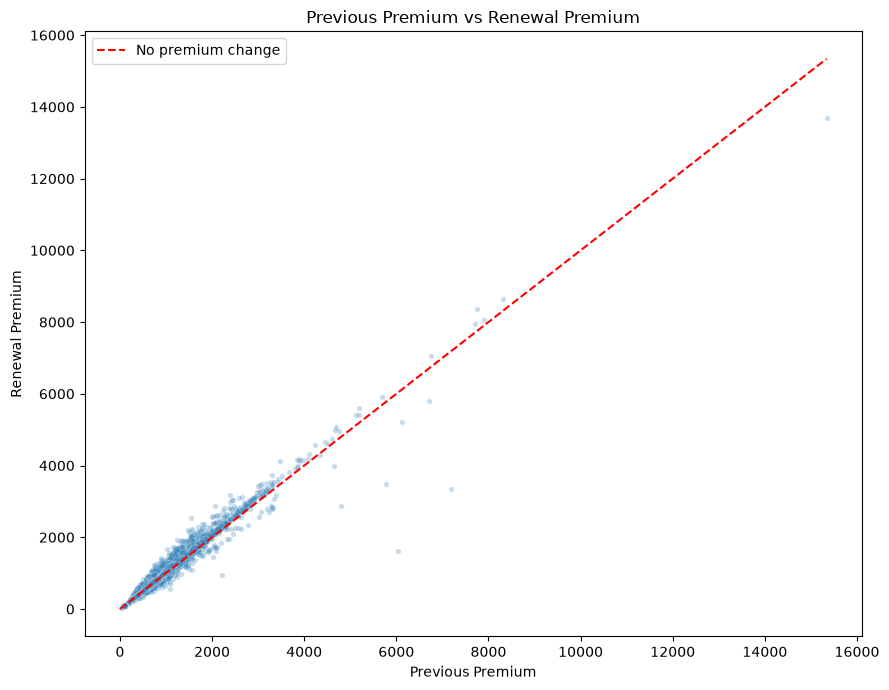

In [134]:

premium_sample = df[
    ["previous_premium", "target_premium"]
].dropna().sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=premium_sample,
    x="previous_premium",
    y="target_premium",
    alpha=0.25,
    s=15
)

max_value = premium_sample[
    ["previous_premium", "target_premium"]
].to_numpy().max()

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    color="red",
    label="No premium change"
)

plt.xlabel("Previous Premium")
plt.ylabel("Renewal Premium")
plt.title("Previous Premium vs Renewal Premium")
plt.legend()
plt.tight_layout()
plt.show()


### 12.4 Age and Renewal Premium

#### Examine the relationship between age and renewal premium using age-group summaries. Grouped medians and means help identify possible nonlinear changes in premium levels across age ranges.

,count,mean,median,std
age_group,,,,
"(-0.001, 18.0]",18841,556.57,528.12,200.49
"(18.0, 30.0]",11716,696.73,679.79,264.04
"(30.0, 40.0]",17050,756.50,723.97,309.93
"(40.0, 50.0]",18914,823.37,800.45,356.86
"(50.0, 60.0]",17877,990.17,985.86,473.58
"(60.0, 70.0]",19215,1201.84,1085.94,653.70
"(70.0, 80.0]",12788,1339.92,1146.08,879.26
"(80.0, inf]",6897,1305.24,1128.17,824.61


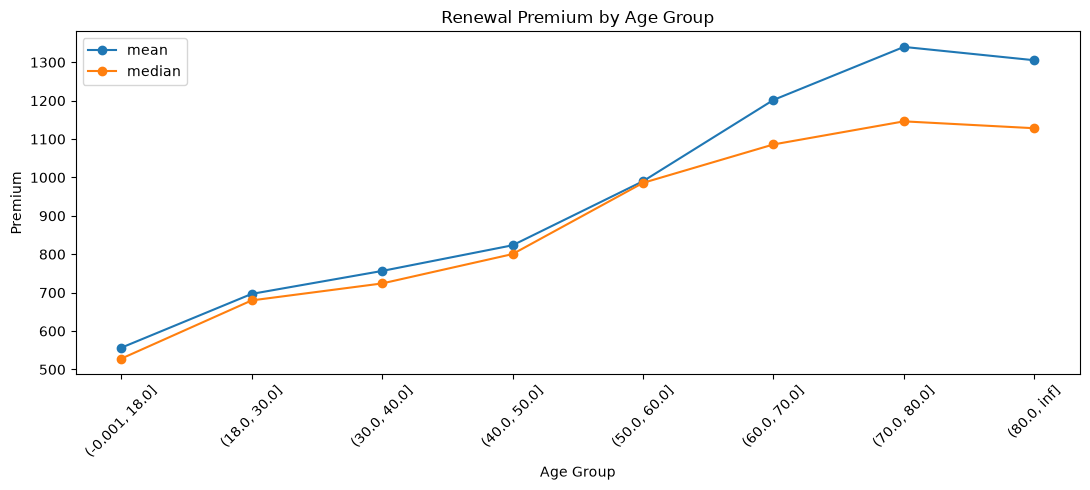

In [135]:

age_data = df[["age", target]].dropna().copy()

age_data["age_group"] = pd.cut(
    age_data["age"],
    bins=[0, 18, 30, 40, 50, 60, 70, 80, np.inf],
    include_lowest=True
)

age_summary = (
    age_data.groupby(
        "age_group",
        observed=True
    )[target]
    .agg(["count", "mean", "median", "std"])
)

display(age_summary.round(2))

age_summary[["mean", "median"]].plot(
    marker="o",
    figsize=(11, 5)
)

plt.title("Renewal Premium by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Premium")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 12.5 Seniority and Renewal Premium

#### Examine the association of policy seniority and insured seniority with renewal premium using binned median trends. This helps identify whether premium levels increase, decrease, or plateau across seniority ranges.

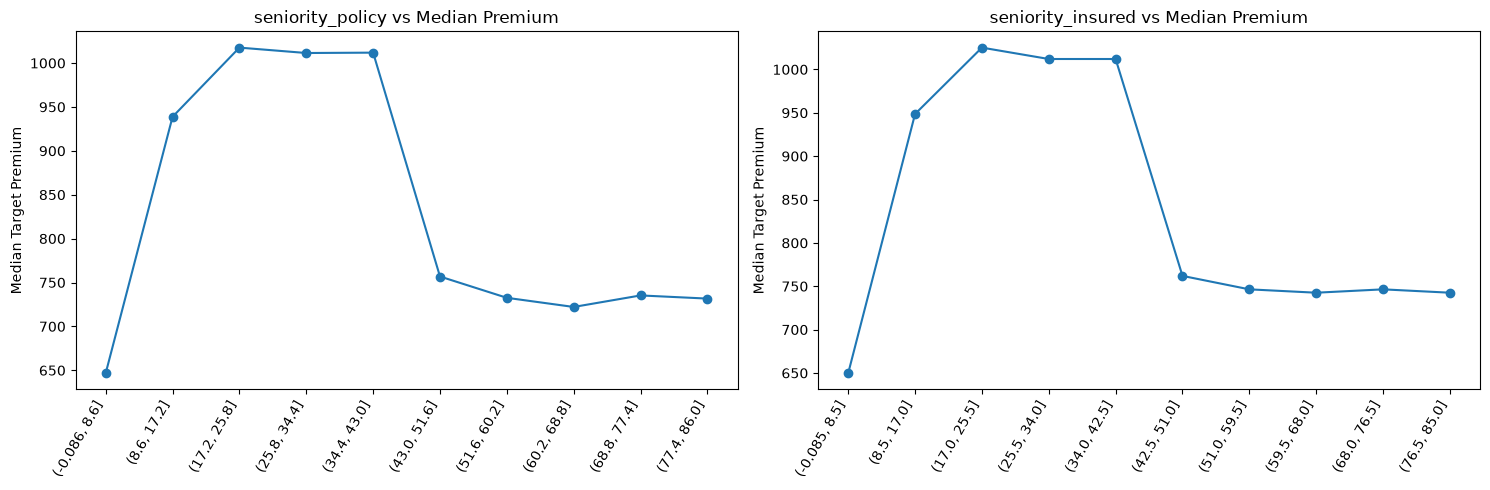

In [136]:

seniority_features = [
    "seniority_policy",
    "seniority_insured"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, col in zip(axes, seniority_features):

    temp = df[[col, target]].dropna().copy()

    temp["group"] = pd.cut(
        temp[col],
        bins=10,
        duplicates="drop"
    )

    summary = temp.groupby(
        "group",
        observed=True
    )[target].median()

    ax.plot(
        range(len(summary)),
        summary.values,
        marker="o"
    )

    ax.set_xticks(range(len(summary)))
    ax.set_xticklabels(
        summary.index.astype(str),
        rotation=60,
        ha="right"
    )

    ax.set_title(f"{col} vs Median Premium")
    ax.set_ylabel("Median Target Premium")

plt.tight_layout()
plt.show()


### 12.6 Claims and Medical Utilization

#### Examine the relationship between claims costs, medical-service utilization, and renewal premium. Because these variables are strongly right-skewed, logarithmic display scaling is used to improve visualization. This analysis does not establish their availability at the premium determination date.

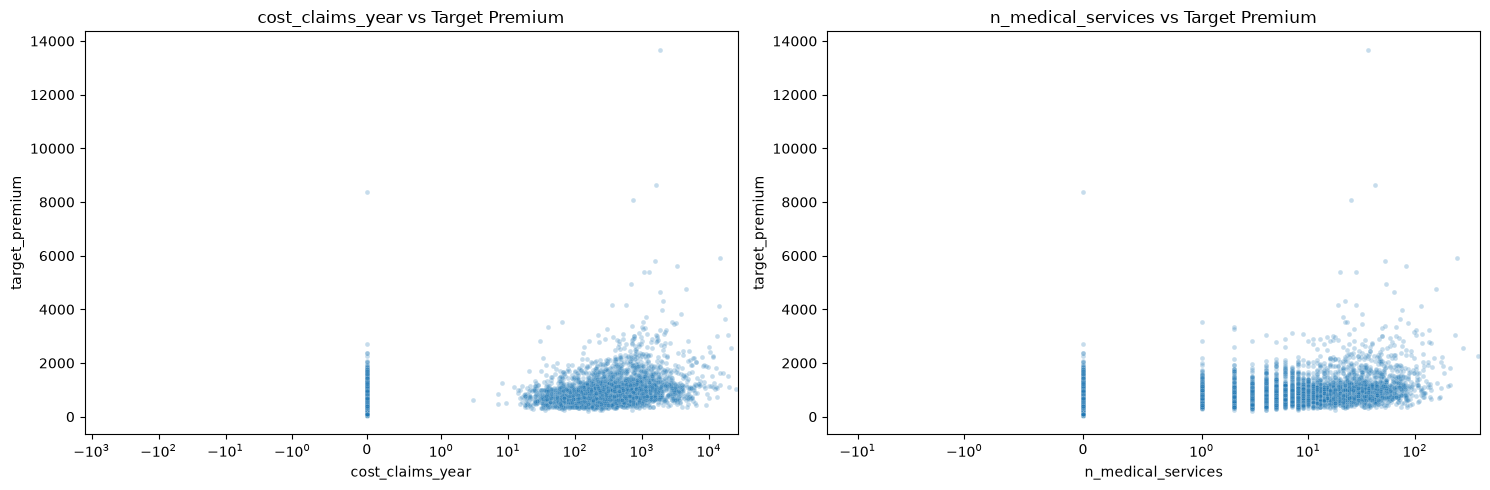

In [137]:

utilization_features = [
    "cost_claims_year",
    "n_medical_services"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, col in zip(axes, utilization_features):

    temp = plot_sample[
        [col, target]
    ].dropna()

    sns.scatterplot(
        data=temp,
        x=col,
        y=target,
        alpha=0.25,
        s=12,
        ax=ax
    )

    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(f"{col} vs Target Premium")

plt.tight_layout()
plt.show()


### 12.7 Categorical Predictor Summary

#### Calculate observation counts, mean premiums, median premiums, and standard deviations for each categorical predictor. Group-level comparisons help identify differences in premium distributions across categories.

In [138]:

categorical_summaries = {}

for col in bivariate_cat:

    summary = (
        df.groupby(
            col,
            dropna=False
        )[target]
        .agg(["count", "mean", "median", "std"])
        .sort_values("median", ascending=False)
    )

    categorical_summaries[col] = summary

    print(f"\nFeature: {col}")
    display(summary.round(2))



Feature: lapse


,count,mean,median,std
lapse,,,,
2,123298,925.02,834.26,576.72



Feature: type_policy


,count,mean,median,std
type_policy,,,,
I,74805,986.95,852.44,694.91
C,48493,829.47,801.50,292.78



Feature: type_policy_dg


,count,mean,median,std
type_policy_dg,,,,
C3,31356,915.21,948.60,200.93
I,58420,1051.94,917.08,754.44
C2,2485,872.31,900.92,247.70
SE,16385,755.23,690.42,326.47
C1,12853,669.07,604.99,380.78
C4,1799,421.93,378.42,75.78


... (10 outputs left out)


Feature: C_H


,count,mean,median,std
C_H,,,,
NaN,6010,1029.94,895.87,734.48
H6,72445,937.76,868.79,583.36
H1,1407,964.29,847.62,651.85
H2,11284,895.43,798.22,508.30
H3,14563,911.44,790.50,560.06
H5,9178,863.67,769.06,527.17
H4,8411,863.87,760.94,525.86



Feature: C_C


,count,mean,median,std
C_C,,,,
C2,3197,1118.72,961.86,662.51
NaN,5755,1026.18,887.54,742.28
C1,13115,977.57,867.59,654.43
C6,28480,1036.36,865.79,656.83
C5,3214,1010.49,839.89,765.37
C3,57103,832.28,802.50,448.72
C4,12434,921.71,790.56,572.23


### 12.8 Categorical Premium Boxplots

#### Visualize the distribution of renewal premiums across categorical groups. The plots highlight differences in medians, variability, and extreme observations. Categories with many distinct values are limited to their most frequent groups for readability.

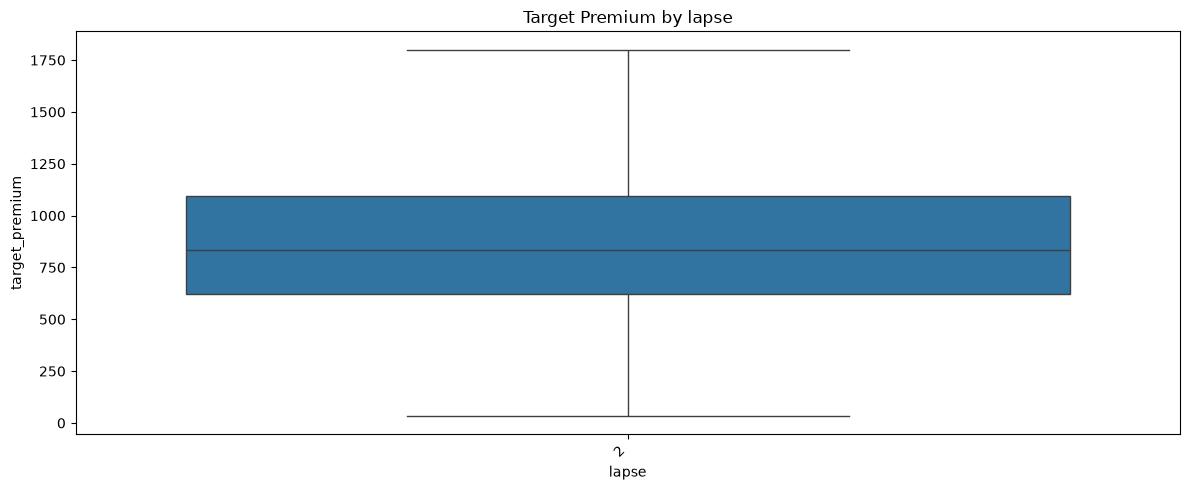

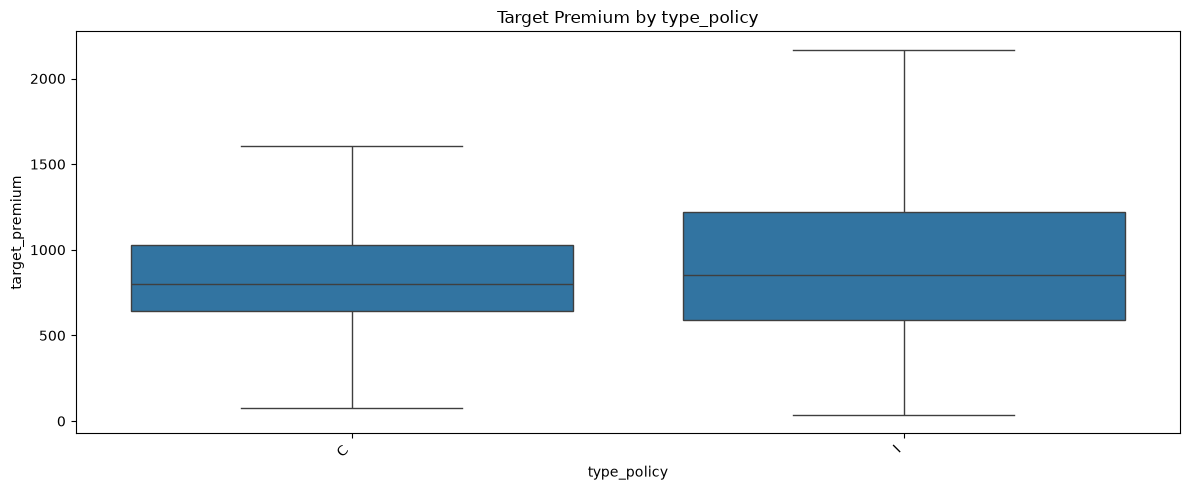

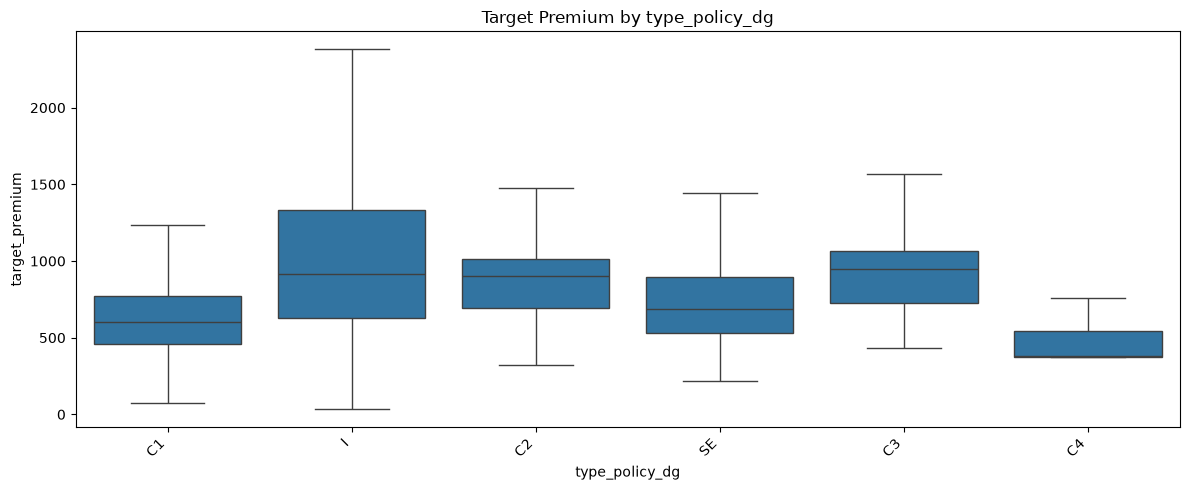

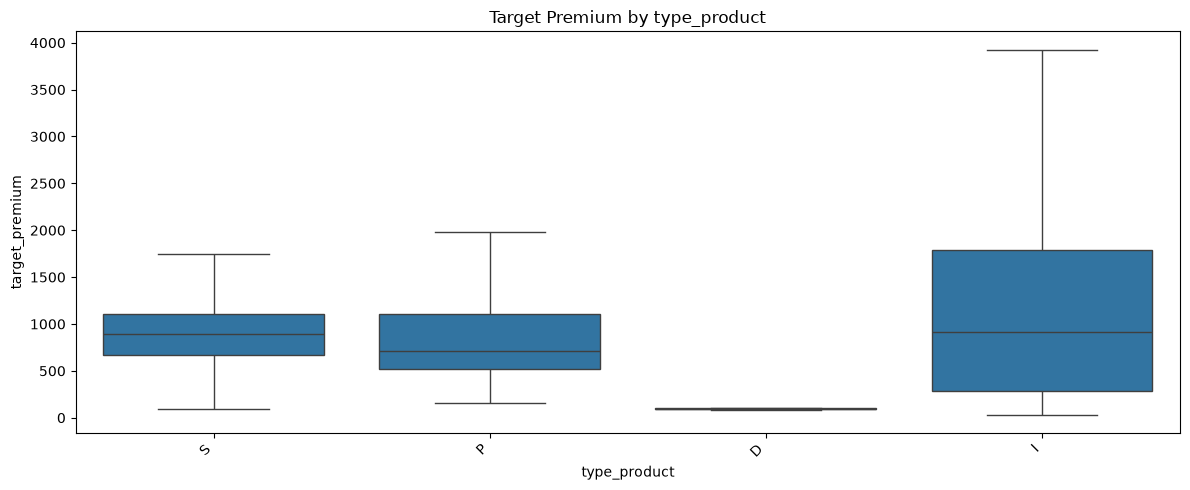

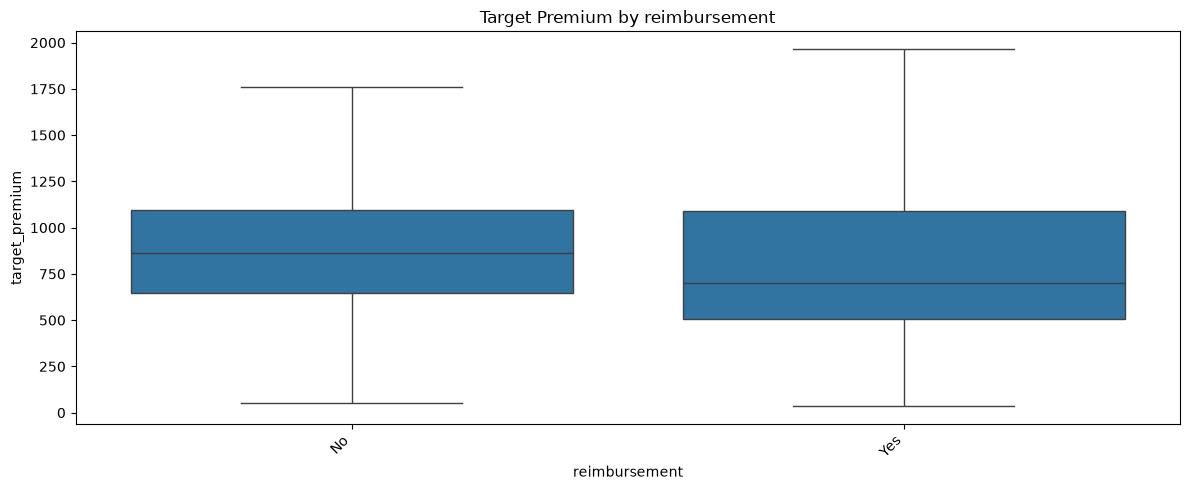

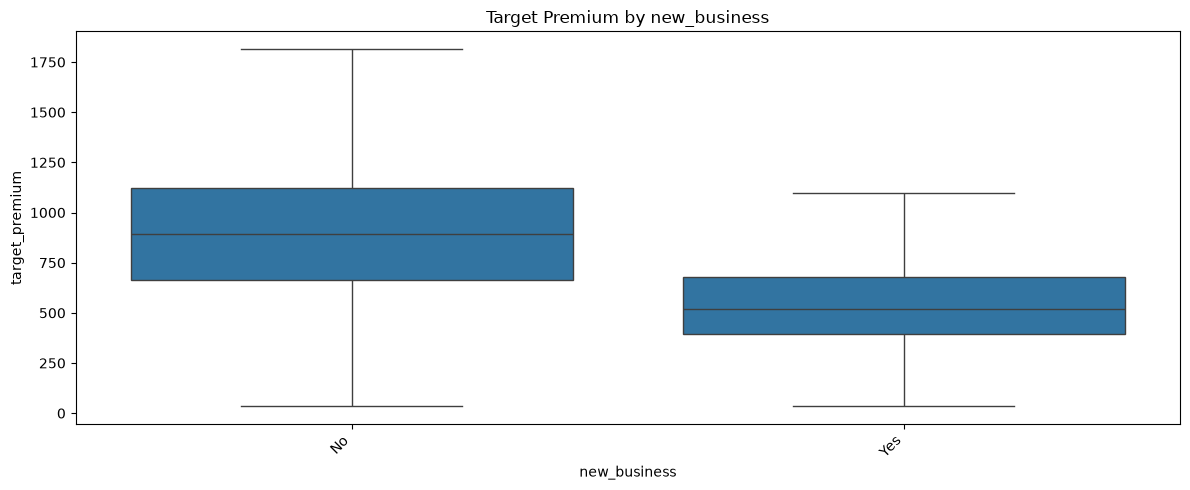

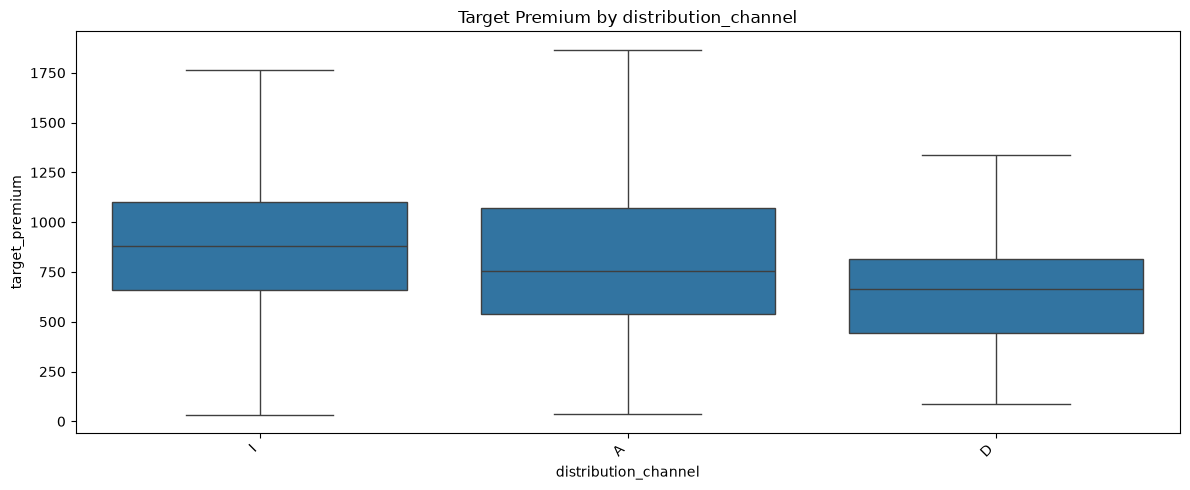

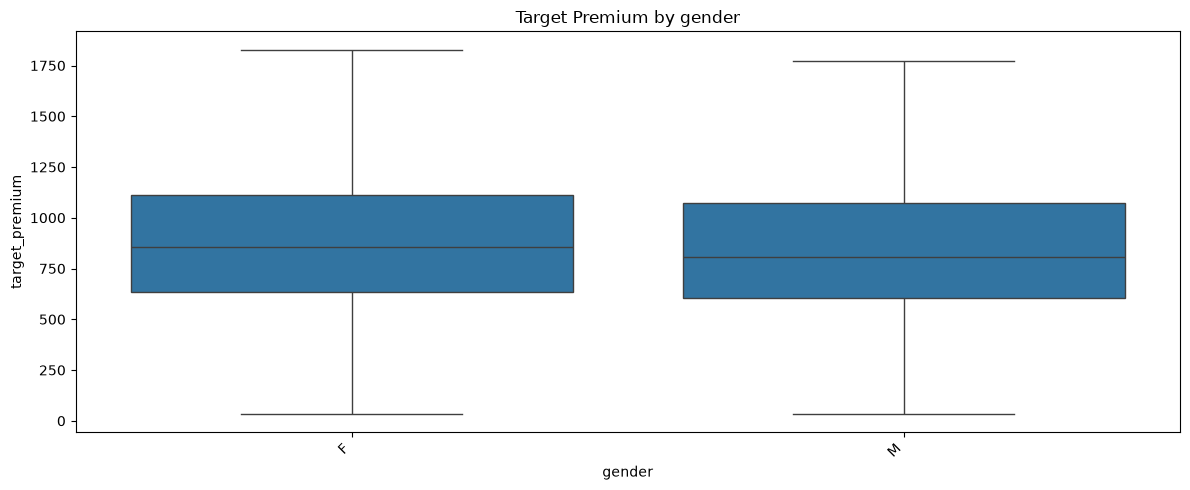

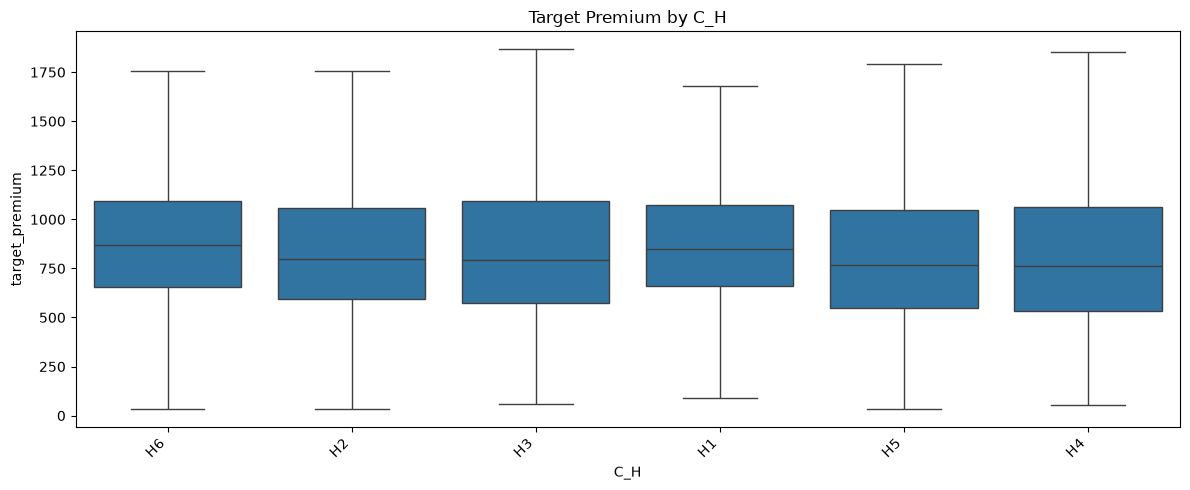

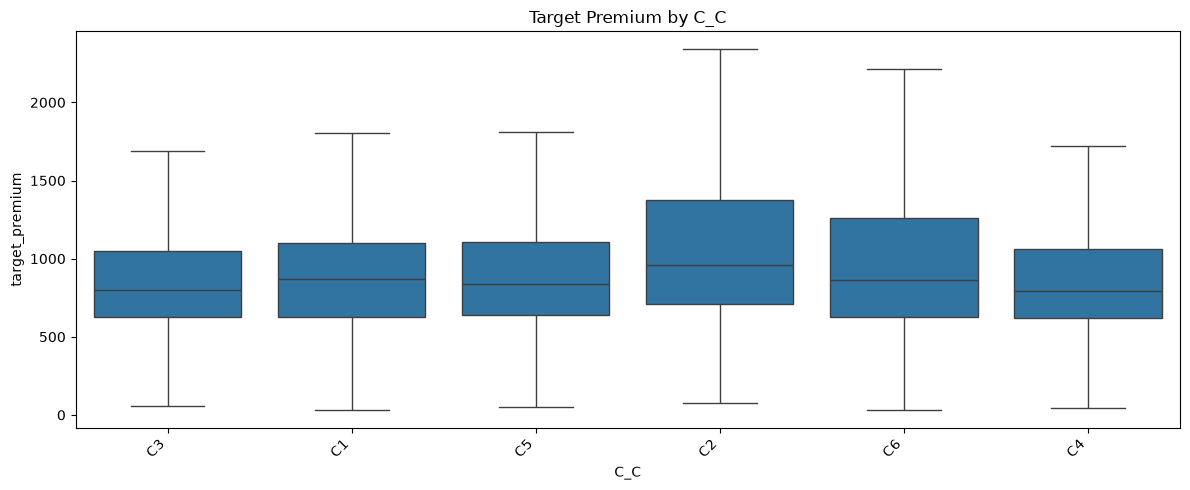

In [139]:

for col in bivariate_cat:

    top_categories = (
        df[col]
        .value_counts(dropna=False)
        .head(12)
        .index
    )

    temp = df[
        df[col].isin(top_categories)
    ].copy()

    if temp.empty:
        continue

    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=temp,
        x=col,
        y=target,
        showfliers=False
    )

    plt.title(f"Target Premium by {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


### 12.9 Eta-Squared Association Analysis

#### Calculate eta-squared for each categorical predictor against renewal premium. Eta-squared measures the proportion of total target variance associated with differences between category means. It is descriptive and does not imply causation or predictive generalization.

In [140]:

def calculate_eta_squared(data, category, target):

    temp = data[[category, target]].dropna()

    if temp.empty or temp[category].nunique() < 2:
        return np.nan

    grand_mean = temp[target].mean()

    group_stats = (
        temp.groupby(category)[target]
        .agg(["count", "mean"])
    )

    ss_between = (
        group_stats["count"]
        * (group_stats["mean"] - grand_mean) ** 2
    ).sum()

    ss_total = (
        (temp[target] - grand_mean) ** 2
    ).sum()

    return (
        ss_between / ss_total
        if ss_total > 0 else np.nan
    )


eta_results = []

for col in bivariate_cat:

    eta_results.append({
        "Feature": col,
        "Eta Squared": calculate_eta_squared(
            df, col, target
        )
    })

eta_df = pd.DataFrame(eta_results)

eta_df = eta_df.sort_values(
    "Eta Squared",
    ascending=False
)

display(eta_df.round(5))


,Feature,Eta Squared
3,type_product,0.09321
2,type_policy_dg,0.06634
5,new_business,0.04620
9,C_C,0.02703
1,type_policy,0.01779
6,distribution_channel,0.00365
8,C_H,0.00236
7,gender,0.00116
4,reimbursement,0.00003
0,lapse,NaN


### 12.10 Categorical Association Ranking

#### Rank categorical predictors by eta-squared to compare their observed association with variation in renewal premiums.

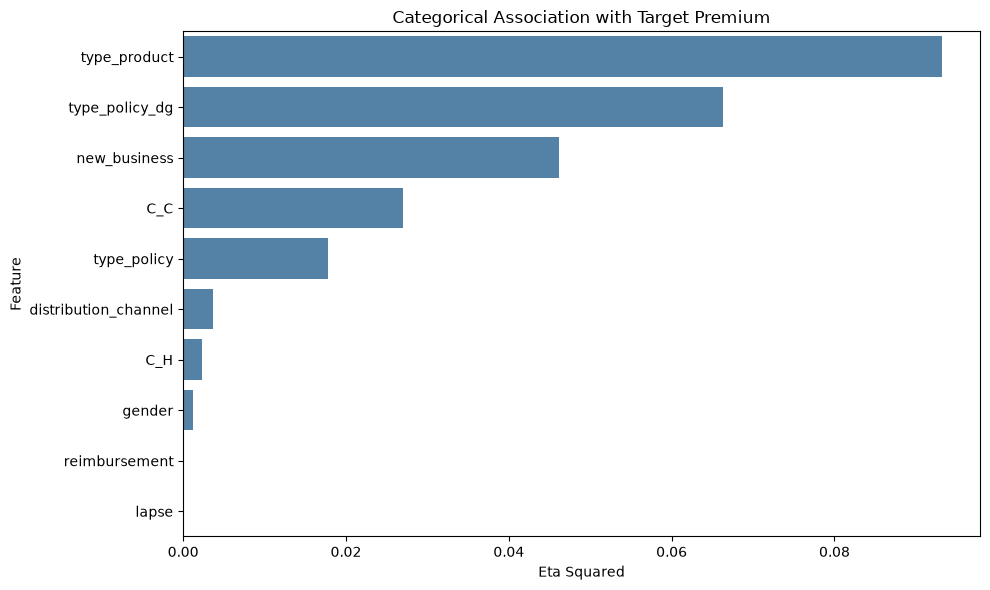

In [141]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=eta_df,
    x="Eta Squared",
    y="Feature",
    color="steelblue"
)

plt.title("Categorical Association with Target Premium")
plt.tight_layout()
plt.show()


### 12.11 Year-Wise Categorical Associations

#### Calculate eta-squared separately for each observation period to examine whether categorical associations with renewal premium are stable across 2017 and 2018.

In [142]:

yearly_eta = []

for year, group in df.groupby("period"):

    for col in bivariate_cat:

        yearly_eta.append({
            "Period": year,
            "Feature": col,
            "Eta Squared": calculate_eta_squared(
                group, col, target
            )
        })

yearly_eta_df = pd.DataFrame(yearly_eta)

yearly_eta_pivot = yearly_eta_df.pivot(
    index="Feature",
    columns="Period",
    values="Eta Squared"
)

if {2017, 2018}.issubset(yearly_eta_pivot.columns):
    yearly_eta_pivot["Absolute Difference"] = (
        yearly_eta_pivot[2018]
        - yearly_eta_pivot[2017]
    ).abs()

    yearly_eta_pivot = yearly_eta_pivot.sort_values(
        "Absolute Difference",
        ascending=False
    )

display(yearly_eta_pivot.round(5))


Period,2017,2018,Absolute Difference
Feature,,,
type_policy_dg,0.08944,0.04323,0.04621
type_policy,0.02741,0.00947,0.01793
C_C,0.03160,0.02264,0.00895
type_product,0.09177,0.09707,0.00530
distribution_channel,0.00171,0.00676,0.00505
new_business,0.04664,0.04537,0.00127
C_H,0.00201,0.00291,0.00090
gender,0.00128,0.00103,0.00025
reimbursement,0.00022,0.00003,0.00019


### Part 12 — Bivariate Analysis: Key Findings

#### Bivariate analysis reveals that renewal premiums generally increase with age, with the highest observed mean premium among individuals aged 71–80. Premium variability also increases across older age groups, suggesting potential nonlinear relationships and heteroscedasticity.

#### Among categorical predictors, product type exhibits the strongest association with renewal premium (η² = 0.09321), followed by policy classification (η² = 0.06634) and new-business status (η² = 0.04620). Product D is particularly distinctive, with substantially lower premiums and limited variability compared with other product categories.

#### Product type and new-business associations remain relatively stable across 2017 and 2018, whereas policy classification shows a noticeable change in association strength. Gender and reimbursement have very weak unadjusted eta-squared values. The lapse variable is constant and therefore provides no discriminatory information.

#### These findings motivate further multivariate analysis to determine whether observed relationships persist after accounting for previous premium, age, product type, and policy characteristics. Feature eligibility will also depend on whether information is available at the premium determination date.

### 13.1 Multivariate Analysis Preparation

#### Select key demographic, policy, financial, and product variables for joint analysis of renewal premiums. Create a temporary analysis dataset while preserving the original dataframe. The analysis is exploratory and does not establish final predictor eligibility.

In [144]:
multi_features = [
    "period",
    "target_premium",
    "previous_premium",
    "age",
    "seniority_policy",
    "seniority_insured",
    "cost_claims_year",
    "n_medical_services",
    "type_product",
    "type_policy",
    "type_policy_dg",
    "new_business",
    "gender"
]

multi_df = df[multi_features].copy()

print("Shape:", multi_df.shape)
display(multi_df.head())


Shape: (123298, 13)


,period,target_premium,previous_premium,age,seniority_policy,seniority_insured,cost_claims_year,n_medical_services,type_product,type_policy,type_policy_dg,new_business,gender
0,2017,630.3600,573.24,40,13,13,0.00,0,S,C,C1,No,F
1,2018,652.5858,630.36,41,14,14,102.01,1,S,C,C1,No,F
2,2017,2882.5400,2885.57,41,13,13,2208.87,82,S,I,I,No,F
3,2018,3038.3931,2882.54,42,14,14,2237.15,21,S,I,I,No,F
4,2017,2010.9100,1877.82,67,13,13,0.00,0,S,I,I,No,M


### 13.2 Age–Premium Relationship by Product Type

#### Examine median renewal premiums across age groups separately for each product type. This helps determine whether the overall age–premium relationship is consistent across products or influenced by product composition.

,age_group,type_product,count,mean,median
0,"(-0.001, 18.0]",D,283,97.02,95.88
1,"(-0.001, 18.0]",I,119,417.12,143.42
2,"(-0.001, 18.0]",P,5101,510.26,466.62
3,"(-0.001, 18.0]",S,13338,585.27,553.01
4,"(18.0, 30.0]",D,528,97.64,96.20
5,"(18.0, 30.0]",I,110,619.00,887.08
6,"(18.0, 30.0]",P,2501,679.72,617.15
7,"(18.0, 30.0]",S,8577,739.57,713.06
8,"(30.0, 40.0]",D,566,97.19,95.88
9,"(30.0, 40.0]",I,234,360.10,193.63


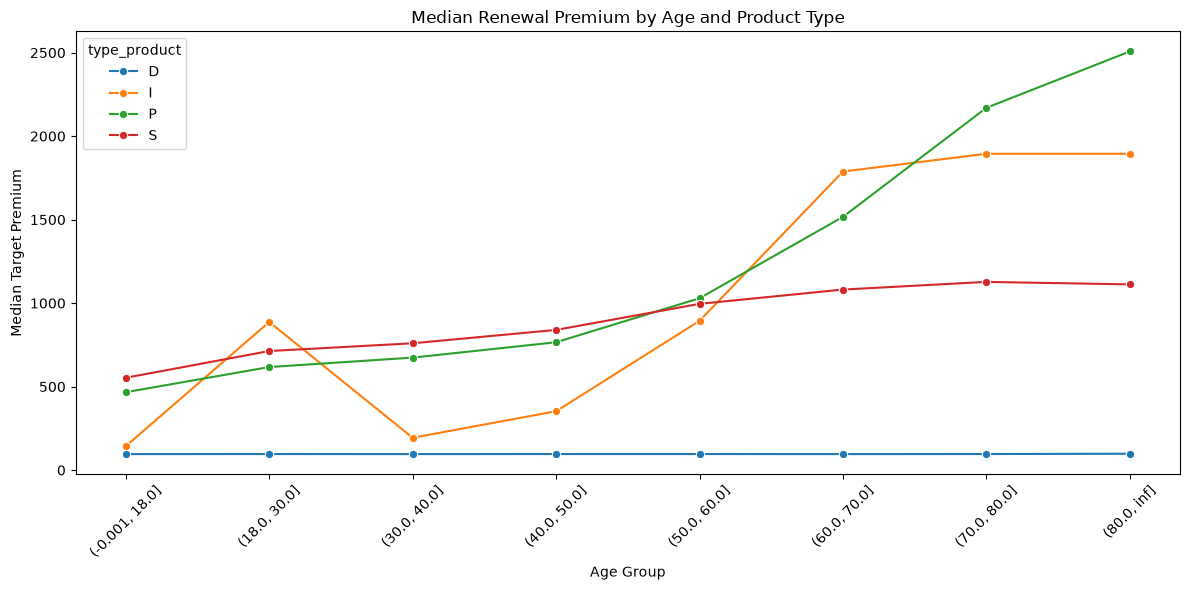

In [147]:

age_product = multi_df[
    ["age", "type_product", "target_premium"]
].dropna().copy()

age_product["age_group"] = pd.cut(
    age_product["age"],
    bins=[0, 18, 30, 40, 50, 60, 70, 80, np.inf],
    include_lowest=True
)

age_product_summary = (
    age_product.groupby(
        ["age_group", "type_product"],
        observed=True
    )["target_premium"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

display(age_product_summary.round(2))

# Convert interval categories to readable strings
age_product_summary["age_group"] = (
    age_product_summary["age_group"].astype(str)
)

# Preserve chronological age-group order
age_order = [
    "(-0.001, 18.0]",
    "(18.0, 30.0]",
    "(30.0, 40.0]",
    "(40.0, 50.0]",
    "(50.0, 60.0]",
    "(60.0, 70.0]",
    "(70.0, 80.0]",
    "(80.0, inf]"
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=age_product_summary,
    x="age_group",
    y="median",
    hue="type_product",
    marker="o",
    estimator=None,
    sort=False
)

plt.title("Median Renewal Premium by Age and Product Type")
plt.xlabel("Age Group")
plt.ylabel("Median Target Premium")
plt.xticks(
    ticks=range(len(age_order)),
    labels=age_order,
    rotation=45
)
plt.tight_layout()
plt.show()


### 13.3 Previous and Renewal Premium by Product

#### Examine whether the relationship between previous and renewal premiums is consistent across product categories. Compare within-product Pearson correlations and average premium changes.

In [156]:

product_premium_results = []

for product, group in multi_df.groupby("type_product"):

    valid = group[
        ["previous_premium", "target_premium"]
    ].dropna()

    correlation = valid[
        "previous_premium"
    ].corr(valid["target_premium"])

    change = (
        valid["target_premium"]
        - valid["previous_premium"]
    )

    product_premium_results.append({
        "Product": product,
        "Count": len(valid),
        "Pearson": correlation,
        "Mean Change": change.mean(),
        "Median Change": change.median()
    })

product_premium_df = pd.DataFrame(
    product_premium_results
)

display(product_premium_df.round(4))


,Product,Count,Pearson,Mean Change,Median Change
0,D,5310,0.8556,-2.8693,-0.6269
1,I,1703,0.9949,62.0408,51.3282
2,P,20877,0.9874,52.9189,31.5700
3,S,95408,0.9827,52.6306,40.7527


### 13.4 Premium Change by Age and Product

#### Analyze renewal premium changes across age groups and product types. Premium change is defined as target premium minus previous premium. This is an exploratory derived outcome and is not used as a predictor of target premium.

type_product,D,I,P,S
age_group,,,,
"(-0.001, 18.0]",-0.63,4.56,18.36,16.36
"(18.0, 30.0]",-1.12,43.97,25.25,27.02
"(30.0, 40.0]",-0.27,9.20,30.30,30.51
"(40.0, 50.0]",-0.63,16.33,32.32,30.65
"(50.0, 60.0]",-0.63,50.50,39.75,38.38
"(60.0, 70.0]",-0.63,102.80,63.71,57.57
"(70.0, 80.0]",-0.63,109.37,98.18,72.54
"(80.0, inf]",-0.63,108.27,103.02,70.61


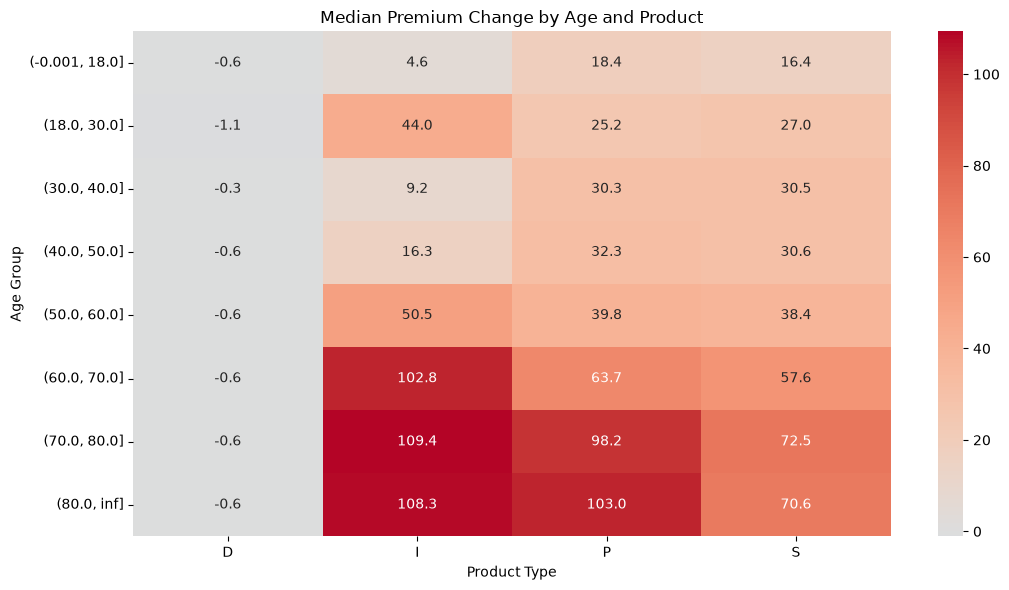

In [148]:

premium_change_df = multi_df.copy()

premium_change_df["premium_change"] = (
    premium_change_df["target_premium"]
    - premium_change_df["previous_premium"]
)

premium_change_df["age_group"] = pd.cut(
    premium_change_df["age"],
    bins=[0, 18, 30, 40, 50, 60, 70, 80, np.inf],
    include_lowest=True
)

change_summary = (
    premium_change_df.groupby(
        ["age_group", "type_product"],
        observed=True
    )["premium_change"]
    .median()
    .unstack()
)

display(change_summary.round(2))

plt.figure(figsize=(11, 6))

sns.heatmap(
    change_summary,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0
)

plt.title("Median Premium Change by Age and Product")
plt.xlabel("Product Type")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()


### 13.5 New Business and Product Type

#### Compare renewal premiums between new and existing business within each product category. This helps identify whether the overall new-business difference is partly associated with product composition.

,type_product,new_business,count,mean,median
0,D,No,4832,97.32,96.20
1,D,Yes,478,92.80,87.45
2,I,No,1672,1074.12,916.07
3,I,Yes,31,207.02,164.22
4,P,No,14280,1099.17,831.30
5,P,Yes,6597,637.35,577.16
6,S,No,88762,993.45,924.90
7,S,Yes,6646,549.84,499.60


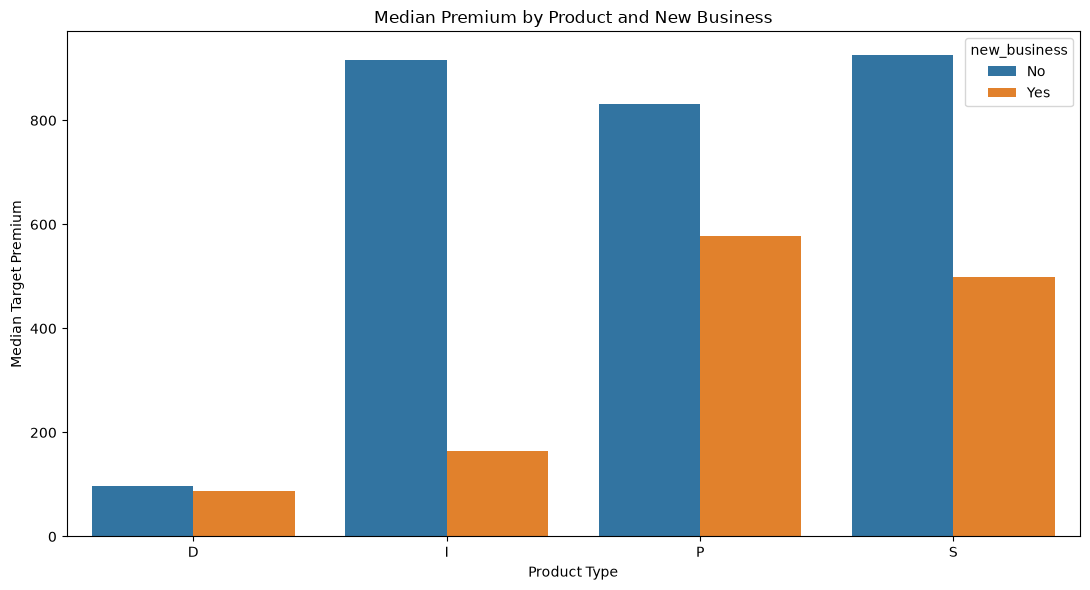

In [149]:

business_product_summary = (
    multi_df.groupby(
        ["type_product", "new_business"]
    )["target_premium"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

display(business_product_summary.round(2))

plt.figure(figsize=(11, 6))

sns.barplot(
    data=business_product_summary,
    x="type_product",
    y="median",
    hue="new_business"
)

plt.title("Median Premium by Product and New Business")
plt.xlabel("Product Type")
plt.ylabel("Median Target Premium")
plt.tight_layout()
plt.show()


### 13.6 Age, Seniority, and Premium

#### Examine correlations among age, policy seniority, insured seniority, and renewal premium to identify overlapping information and potential multicollinearity.

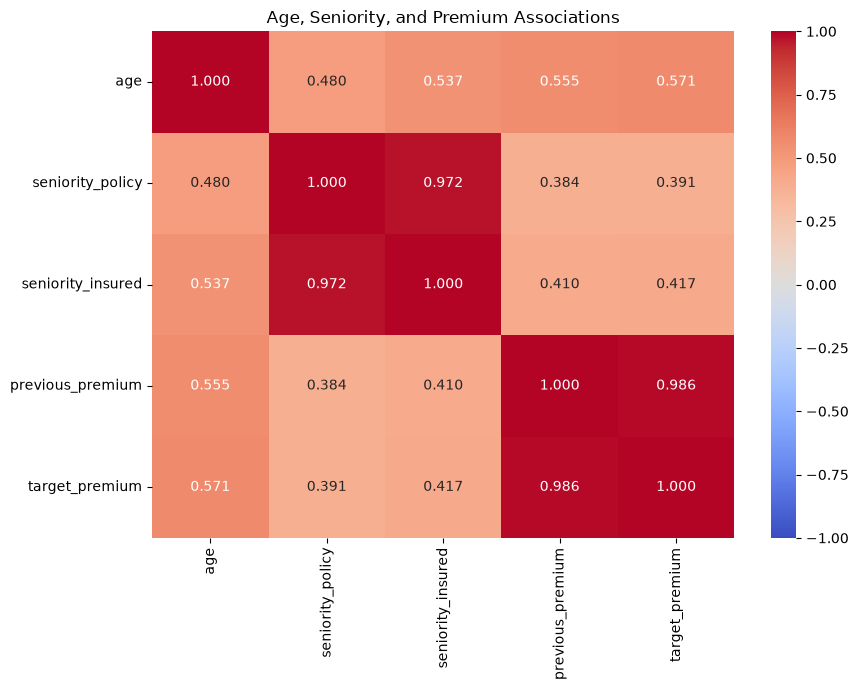

In [150]:

age_seniority_cols = [
    "age",
    "seniority_policy",
    "seniority_insured",
    "previous_premium",
    "target_premium"
]

age_seniority_corr = multi_df[
    age_seniority_cols
].corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    age_seniority_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Age, Seniority, and Premium Associations")
plt.tight_layout()
plt.show()


### 13.7 Claims, Medical Utilization, and Premium

#### Examine joint correlations among claims costs, medical-service utilization, previous premium, and renewal premium. These relationships are exploratory because the time reference of claims and utilization variables must be verified before predictive modeling.

,cost_claims_year,n_medical_services,previous_premium,target_premium
cost_claims_year,1.0000,0.9115,0.3626,0.3841
n_medical_services,0.9115,1.0000,0.3480,0.3664
previous_premium,0.3626,0.3480,1.0000,0.9861
target_premium,0.3841,0.3664,0.9861,1.0000


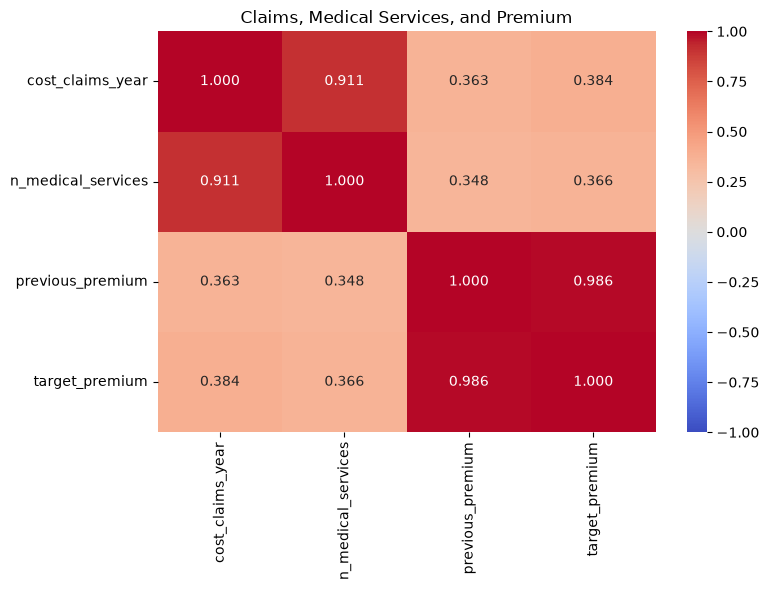

In [151]:

claims_features = [
    "cost_claims_year",
    "n_medical_services",
    "previous_premium",
    "target_premium"
]

claims_corr = multi_df[
    claims_features
].corr(method="spearman")

display(claims_corr.round(4))

plt.figure(figsize=(8, 6))

sns.heatmap(
    claims_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Claims, Medical Services, and Premium")
plt.tight_layout()
plt.show()


### 13.8 Correlation with Premium Change

#### Calculate associations between numerical predictors and the difference between renewal premium and previous premium. This helps identify features potentially associated with renewal adjustments. Premium change is used only as an exploratory outcome and is not included among model predictors.

In [152]:

change_features = [
    "age",
    "seniority_policy",
    "seniority_insured",
    "cost_claims_year",
    "n_medical_services",
    "previous_premium"
]

change_correlations = (
    premium_change_df[
        change_features + ["premium_change"]
    ]
    .corr(method="spearman")["premium_change"]
    .drop("premium_change")
    .sort_values(key=abs, ascending=False)
)

display(
    change_correlations.to_frame(
        "Spearman with Premium Change"
    ).round(4)
)


,Spearman with Premium Change
previous_premium,0.4475
age,0.4079
cost_claims_year,0.3495
seniority_insured,0.3433
seniority_policy,0.3337
n_medical_services,0.3314


### 13.9 Incremental Predictive Information

#### Compare a linear model using previous premium alone against one additionally using age, seniority, product type, policy classification, and new-business status. The comparison uses a held-out sample and is exploratory rather than a final model evaluation. Because observations may repeat across periods, the final modeling strategy must account for repeated entities and temporal structure.

In [154]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

baseline_features = ["previous_premium"]

extended_numeric = [
    "previous_premium",
    "age",
    "seniority_policy",
    "seniority_insured"
]

extended_categorical = [
    "type_product",
    "type_policy_dg",
    "new_business"
]

model_features = list(dict.fromkeys(
    extended_numeric + extended_categorical
))

diagnostic_df = df[
    ["ID", "target_premium"] + model_features
].dropna(subset=["ID", "target_premium"]).copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        diagnostic_df,
        groups=diagnostic_df["ID"]
    )
)

train = diagnostic_df.iloc[train_idx]
test = diagnostic_df.iloc[test_idx]

def evaluate_diagnostic_model(
    numerical,
    categorical,
    model_name
):

    transformers = [
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numerical
        )
    ]

    if categorical:
        transformers.append(
            (
                "categorical",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(strategy="most_frequent")
                    ),
                    (
                        "encoder",
                        OneHotEncoder(
                            handle_unknown="ignore"
                        )
                    )
                ]),
                categorical
            )
        )

    preprocessing = ColumnTransformer(
        transformers
    )

    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", Ridge(alpha=1.0))
    ])

    features = numerical + categorical

    pipeline.fit(
        train[features],
        train["target_premium"]
    )

    predictions = pipeline.predict(
        test[features]
    )

    return {
        "Model": model_name,
        "MAE": mean_absolute_error(
            test["target_premium"],
            predictions
        ),
        "R2": r2_score(
            test["target_premium"],
            predictions
        )
    }

results = [
    evaluate_diagnostic_model(
        baseline_features,
        [],
        "Previous Premium Only"
    ),
    evaluate_diagnostic_model(
        extended_numeric,
        extended_categorical,
        "Extended Ridge"
    )
]

display(pd.DataFrame(results).round(4))


,Model,MAE,R2
0,Previous Premium Only,45.0593,0.9731
1,Extended Ridge,43.0511,0.9742


### 13.10 Unchanged-Premium Baseline

#### Evaluate the simple historical-premium baseline, which predicts the renewal premium to equal the previous premium. This provides a practical reference for judging whether more complex models improve predictive performance.

In [155]:

valid_baseline = test[
    ["previous_premium", "target_premium"]
].dropna()

baseline_actual = valid_baseline[
    "target_premium"
]

baseline_prediction = valid_baseline[
    "previous_premium"
]

print(
    "Unchanged-premium MAE:",
    round(
        mean_absolute_error(
            baseline_actual,
            baseline_prediction
        ),
        4
    )
)

print(
    "Unchanged-premium R²:",
    round(
        r2_score(
            baseline_actual,
            baseline_prediction
        ),
        4
    )
)


Unchanged-premium MAE: 63.0249
Unchanged-premium R²: 0.9651


### 13.11 Multivariate Analysis Summary

#### Multivariate analysis investigates how age, product classification, policy seniority, new-business status, claims history, and previous premium jointly relate to renewal premiums.

#### Particular emphasis is placed on whether apparent bivariate relationships persist within product categories and whether additional predictors improve performance beyond the strong previous-premium baseline.

#### The exploratory comparisons do not establish causal effects or final model performance. Temporal feature availability, repeated observations, and appropriate train–test separation must be addressed before developing the final predictive model.

### Part 13 — Multivariate Analysis: Key Findings

#### Multivariate exploration reveals that the association between age and renewal premium differs substantially across product categories. Product D has nearly constant median premiums across age groups, whereas Products P and S exhibit increasing premiums with age. These patterns suggest possible interactions between age and product type.

#### Previous premium remains strongly correlated with renewal premium within every product category. Analysis of premium adjustments reveals that age, seniority, and previous premium are also associated with the magnitude of renewal changes. Existing-business observations have higher median premiums than new-business observations within each product category, although these comparisons do not establish causal effects.

#### An exploratory Ridge regression comparison shows that adding demographic and policy variables to previous premium improves MAE from 45.0593 to 43.0511 and R² from 0.9731 to 0.9742. This indicates modest incremental predictive value beyond previous premium.

#### Final model development must account for repeated entities, chronological validation, and the availability of predictors at premium determination. Current-year claims and medical utilization remain subject to temporal leakage verification.

### 14.1 Final Dataset Overview

#### Summarize the dataset's dimensions, observation periods, unique identifiers, missing values, and target variable. This provides a consolidated description of the data before preprocessing and modeling.

In [157]:

dataset_summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Total columns",
        "Unique IDs",
        "Unique policies",
        "Unique insured individuals",
        "Observation periods",
        "Target missing values",
        "Target mean",
        "Target median",
        "Target standard deviation"
    ],
    "Value": [
        len(df),
        df.shape[1],
        df["ID"].nunique(),
        df["ID_policy"].nunique(),
        df["ID_insured"].nunique(),
        sorted(df["period"].dropna().unique().tolist()),
        df["target_premium"].isna().sum(),
        round(df["target_premium"].mean(), 2),
        round(df["target_premium"].median(), 2),
        round(df["target_premium"].std(), 2)
    ]
})

display(dataset_summary)


,Metric,Value
0,Total observations,123298
1,Total columns,44
2,Unique IDs,69738
3,Unique policies,32543
4,Unique insured individuals,1205
5,Observation periods,"[2017, 2018]"
6,Target missing values,0
7,Target mean,925.02
8,Target median,834.26
9,Target standard deviation,576.72


### 14.2 Consolidated EDA Findings

#### The renewal premium is right-skewed and exhibits substantial variability. Previous premium is the strongest observed numerical predictor, while age and product type show meaningful relationships with premium levels and adjustments.

#### Multivariate analysis suggests that the age–premium relationship differs across products. Additional demographic and policy variables provide modest incremental predictive information beyond previous premium.

#### The dataset contains repeated observations across periods, correlated predictors, and structured missingness. These characteristics must inform preprocessing, feature selection, and evaluation design.

In [158]:

variability_results = []

for col in df.columns:

    counts = df[col].value_counts(
        normalize=True,
        dropna=False
    )

    variability_results.append({
        "Feature": col,
        "Unique Values": df[col].nunique(dropna=False),
        "Most Common Share": (
            counts.iloc[0] if len(counts) else np.nan
        )
    })

variability_df = pd.DataFrame(variability_results)

constant_features = variability_df[
    variability_df["Unique Values"] <= 1
]

near_constant_features = variability_df[
    (variability_df["Most Common Share"] >= 0.99)
    & (variability_df["Unique Values"] > 1)
]

print("Constant features:")
display(constant_features)

print("\nNear-constant features (>=99% one value):")
display(near_constant_features)


Constant features:


,Feature,Unique Values,Most Common Share
13,lapse,1,1.0



Near-constant features (>=99% one value):


,Feature,Unique Values,Most Common Share


### 14.3 Highly Correlated Predictors

#### Identify strongly correlated numerical predictor pairs using an absolute Pearson correlation threshold of 0.90. These pairs are flagged for further investigation rather than automatically removed.

In [159]:

numeric_predictors = [
    col for col in num_cols
    if col in df.columns and col != "target_premium"
]

corr_matrix = df[
    numeric_predictors
].corr(method="pearson").abs()

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for col in upper_triangle.columns:

    for row, value in upper_triangle[col].dropna().items():

        if value >= 0.90:
            high_corr_pairs.append({
                "Feature 1": row,
                "Feature 2": col,
                "Absolute Correlation": value
            })

high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=[
        "Feature 1",
        "Feature 2",
        "Absolute Correlation"
    ]
).sort_values(
    "Absolute Correlation",
    ascending=False
)

display(high_corr_df.round(4))


,Feature 1,Feature 2,Absolute Correlation
2,C_IE_S,C_IE_T,0.9656
0,seniority_insured,seniority_policy,0.9566
4,C_IE_S,C_GE_S,0.9230
3,C_IE_P,C_GE_P,0.9107
1,C_IE_P,C_IE_T,0.9024


### 14.4 Historical Premium Consistency

#### Compare the 2017 renewal premium with the 2018 previous premium for IDs appearing in both periods. This checks whether the previous-premium variable is consistent with the dataset's observed annual premium history. Agreement supports historical consistency but does not, by itself, establish feature availability at the pricing date.

In [160]:

premium_2017 = (
    df.loc[
        df["period"] == 2017,
        ["ID", "target_premium"]
    ]
    .rename(
        columns={
            "target_premium": "target_premium_2017"
        }
    )
)

premium_2018 = (
    df.loc[
        df["period"] == 2018,
        ["ID", "previous_premium"]
    ]
    .rename(
        columns={
            "previous_premium": "previous_premium_2018"
        }
    )
)

premium_match = premium_2017.merge(
    premium_2018,
    on="ID",
    how="inner",
    validate="one_to_one"
)

premium_match["difference"] = (
    premium_match["previous_premium_2018"]
    - premium_match["target_premium_2017"]
)

premium_match["matches"] = np.isclose(
    premium_match["previous_premium_2018"],
    premium_match["target_premium_2017"],
    rtol=0,
    atol=0.01
)

print("Matched IDs:", len(premium_match))
print(
    "Match percentage:",
    round(premium_match["matches"].mean() * 100, 2)
)

display(
    premium_match["difference"].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
)

display(
    premium_match.loc[
        ~premium_match["matches"]
    ].head(10)
)


Matched IDs: 53560
Match percentage: 100.0


count    53560.0
mean         0.0
std          0.0
min          0.0
1%           0.0
5%           0.0
50%          0.0
95%          0.0
99%          0.0
max          0.0
Name: difference, dtype: float64

,ID,target_premium_2017,previous_premium_2018,difference,matches


### 14.5 Preliminary Modeling Feature Set

#### Create an initial candidate feature list using historical premium, demographics, and policy characteristics. Temporally uncertain claims, utilization, exposure, and socioeconomic features are withheld pending verification. The list is provisional and will be finalized after the feature eligibility audit.

In [161]:

candidate_numeric = [
    "previous_premium",
    "age",
    "seniority_policy",
    "seniority_insured"
]

candidate_categorical = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "new_business",
    "distribution_channel"
]

candidate_features = (
    candidate_numeric
    + candidate_categorical
)

candidate_features = [
    col for col in candidate_features
    if col in df.columns
]

print("Candidate feature count:", len(candidate_features))

display(
    pd.DataFrame({
        "Candidate Feature": candidate_features
    })
)


Candidate feature count: 11


,Candidate Feature
0,previous_premium
1,age
2,seniority_policy
3,seniority_insured
4,gender
5,type_policy
6,type_policy_dg
7,type_product
8,reimbursement
9,new_business


### Part 14 — Final EDA Conclusions

#### The exploratory analysis indicates that the dataset contains substantial information for studying insurance renewal premiums. Previous premium is strongly associated with the target, while age, product type, policy classification, seniority, and new-business status provide additional descriptive information.

#### Premium distributions are right-skewed, and the relationship between age and premium differs across product categories. The exploratory extended Ridge model achieves a modest improvement over the previous-premium-only model, suggesting some incremental predictive information.

#### The dataset also presents important methodological challenges, including repeated observations, highly correlated predictors, structured missingness, and uncertainty about when certain variables become available. In particular, claims costs, medical-service utilization, exposure time, and lapse-related variables require temporal verification before predictive use.

#### The next phase will focus on validating the prediction objective, confirming feature availability, establishing leakage-safe evaluation procedures, and implementing preprocessing and supervised regression models.